# Two nodes - Hong-Ou-Mandel analysis
Valid for master-satellite two-node runs of Two_nodes_HOM_experiment (GeneralVariableScan_master_satellite_two_nodes) from 2026-10-27 until ...

Ported from standalone/Two photon analysis/two_photon_analysis_20260626.ipynb (RIDs 37525-37550: V = 0.74 ± 0.08). What is different now:
* Both nodes run one loop on one timeline, so there is no handshake. The Node2 delay is D = t_Node2_excitation_delay_mu − t_Node2_rtio_offset_mu (the offset is stored as 0), used directly: positive = Node2 later, and no 189 to subtract. Node2's whole excitation block (FORT off/on and excitation pulse) moves by D.
* The data are in the compact format of single_photon_experiment_9: one row per excitation attempt in which any SPCM clicked, holding the first click of each SPCM and that attempt's t1; n_photon_events rows per measurement; attempts = (n_excitation_cycles + 1) × n_excitation_attempts.
* Detectors as in June: SPCM0 = H1, SPCM1 = V1, SPCM0_OtherNode = H2, SPCM1_OtherNode = V2. The HOM signal is H1H2 + V1V2 (same polarisation, opposite beamsplitter ports); the cross-polarised H1V2 + V1H2 is the reference.
* The four SPCMs share one gate, the union of both nodes' gates for the delay used, so it widens with |D|. A coincidence window inside it can be set to keep the background constant across a delay scan.

**Timing check.** To set D, run the same experiment twice with one node's excitation off (override `p_GRIN2_excitation_Node2 = -150.0`, then `p_GRIN2_excitation_Node1 = -150.0`). Section A compares the two arrival histograms and gives the D at which they overlap. Section B is the HOM scan over D, B.1 the same with only the photons of each cycle's first attempt (runs that record the attempt), and B.2 the same for older runs, the attempt reconstructed from timing. Section C shows the photon arrival histogram of each selected file, and D (general analysis) the retention and loading, SPCM histograms, atom loading time, FORT monitors, excitation cycles and arrival histograms per scan point of the selected files.

In [107]:
date_filters = ["2026-10-27", "2026-10-28", "2026-10-29"]

### which two-node sequences to list
experiment_functions = ["Two_nodes_HOM_experiment"]


from matplotlib import pyplot as plt
import numpy as np
import os, sys
import h5py
from scipy.optimize import curve_fit
from scipy.special import erfc, erfcx
from IPython.display import display, HTML ## for large prints

sys.path.append("..\\")
from h5_data_utilities import * # helper functions for dealing with h5 files

SPCM_NAMES = ['SPCM0', 'SPCM1', 'SPCM0_OtherNode', 'SPCM1_OtherNode']
DETECTOR_LABELS = {'SPCM0': 'H1', 'SPCM1': 'V1', 'SPCM0_OtherNode': 'H2', 'SPCM1_OtherNode': 'V2'}
### p_GRIN2_excitation at or below this means that node was not excited (-150 by convention)
EXCITATION_OFF_DBM = -100.0
RUN_COLORS = {'Node1 only': 'tab:blue', 'Node2 only': 'tab:red'}


def seconds_to_exact_mu(seconds, ref_period=1e-9):
    """The whole machine units m that the kernel saved as float(m)*ref_period (mu_to_seconds).

    Unique while the float64 spacing of the saved seconds is below ref_period,
    i.e. while the RTIO counter is below 2**23 s (97 days). -1 where no
    candidate reproduces the saved value. Rounding seconds*1e9 is not enough:
    near 3e6 s it is ambiguous at the half-ns, and above 2**22 s it is wrong
    for about a fifth of the values.
    """
    seconds = np.asarray(seconds, dtype=float)
    guess = np.round(seconds/ref_period).astype(np.int64)
    exact = np.full(seconds.shape, -1, dtype=np.int64)
    for step in (0, -1, 1, -2, 2):
        candidate = guess+step
        hit = (exact < 0) & (candidate.astype(float)*ref_period == seconds)
        exact[hit] = candidate[hit]
    return exact


def gauss_exp_conv(t, t0, A, sigma, tau, B):
    """Gaussian pulse convolved with an exponential decay, plus a flat background.

    The model of the All-SPCMs fit in 2026_Single_Node_Single_Photon_Analysis,
    rewritten with erfcx where the erfc argument is positive: there the original
    form multiplies an overflowing exponential by a vanishing erfc, which turns
    times long before t0 into nan. Same values everywhere else.
    """
    x = np.asarray(t, dtype=float)-t0
    z = (1/np.sqrt(2))*((sigma/tau)-x/sigma)
    with np.errstate(over='ignore', invalid='ignore'):
        shape = np.where(z > 0,
                         np.exp(-x**2/(2*sigma**2))*erfcx(np.maximum(z, 0)),
                         np.exp(sigma**2/(2*tau**2)-x/tau)*erfc(np.minimum(z, 0)))
    return A*(0.5/tau)*shape+B


def fit_arrival_histogram(times, bin_ns, t0_guess=None, sigma_guess=5.0, tau_guess=24.0):
    """Histogram arrival times and fit gauss_exp_conv, as in the All-SPCMs cell.

    The bins span only the times that were recorded, i.e. the gate that was
    actually open, so a gate that cut the rising edge or the tail leaves those
    times out of the fit instead of pulling it. Whole-ns times sit in the
    middle of the bins; a last bin that would stick out past the gate is
    dropped rather than fitted half-empty.
    """
    window = (float(np.min(times)), float(np.max(times)))
    n_bins = max(int((window[1]-window[0]+1)//bin_ns), 1)
    edges = window[0]-0.5+bin_ns*np.arange(n_bins+1)
    counts, edges = np.histogram(times, bins=edges)
    centers = 0.5*(edges[:-1]+edges[1:])

    if t0_guess is None: t0_guess = centers[np.argmax(counts)]
    B_guess = max(float(np.percentile(counts, 10)), 0.0)
    A_guess = max(float(np.sum(np.maximum(counts-B_guess, 0))*bin_ns), 1.0)
    p0 = [t0_guess, A_guess, sigma_guess, tau_guess, B_guess]
    lower_bounds = [edges[0]-50.0, 0.0, 0.1, 0.1, 0.0]
    upper_bounds = [edges[-1]+50.0, np.inf, 100.0, 500.0, np.inf]
    fit_uncertainty = np.sqrt(np.maximum(counts, 1.0))

    popt, pcov = curve_fit(gauss_exp_conv, centers, counts, p0=p0, sigma=fit_uncertainty, absolute_sigma=True, bounds=(lower_bounds, upper_bounds), maxfev=100000)
    perr = np.sqrt(np.diag(pcov))
    chi2_red = np.sum(((counts-gauss_exp_conv(centers, *popt))/fit_uncertainty)**2)/max(len(counts)-len(popt), 1)

    fine_t = np.linspace(edges[0], edges[-1], 4000)
    t_peak = fine_t[np.argmax(gauss_exp_conv(fine_t, *popt))]
    return {'times': times, 'window': window, 'bin_ns': bin_ns, 'edges': edges, 'counts': counts, 'centers': centers,
            'popt': popt, 'perr': perr, 'chi2_red': chi2_red, 't_peak': t_peak}


def histogram_overlap(times1, window1, times2, window2, bin_ns, min_common_fraction=0.5):
    """Overlap sum(sqrt(p1*p2)) of two arrival-time histograms (Bhattacharyya coefficient).

    1 = identical shapes, 0 = no overlap. Only the time range that BOTH gates
    covered is compared, and each histogram is normalised inside it, so a gate
    that cut one node's rising edge or tail does not count as a shape
    difference.

    nan if that common range holds less than min_common_fraction of either
    node's photons: two decay tails alone also look alike, and would otherwise
    score as a good overlap at a wrong delay. That does not help when one
    node's gate recorded ONLY its tail; the histogram cell flags that case.
    """
    start = max(window1[0], window2[0])
    stop = min(window1[1], window2[1])
    if stop-start < bin_ns: return np.nan
    edges = np.arange(start-0.5, stop+0.5+1e-9, bin_ns)
    counts1, _ = np.histogram(times1, bins=edges)
    counts2, _ = np.histogram(times2, bins=edges)
    if counts1.sum() == 0 or counts2.sum() == 0: return np.nan
    if min(counts1.sum()/len(times1), counts2.sum()/len(times2)) < min_common_fraction: return np.nan
    return float(np.sum(np.sqrt((counts1/counts1.sum())*(counts2/counts2.sum()))))


def overlap_vs_delay(times1, window1, times2, window2, delays, bin_ns, min_common_fraction=0.5):
    """histogram_overlap with Node2's times, and its gate, moved by each delay in turn."""
    return np.array([histogram_overlap(times1, window1, times2+d, (window2[0]+d, window2[1]+d), bin_ns, min_common_fraction) for d in delays])


def refine_peak(delays, overlaps, half_width=4):
    """Sub-ns position of the overlap maximum: a parabola through the points within half_width ns of the best one."""
    if not np.any(np.isfinite(overlaps)): return np.nan
    k = int(np.nanargmax(overlaps))
    near = np.isfinite(overlaps) & (np.abs(delays-delays[k]) <= half_width)
    if np.count_nonzero(near) < 3: return float(delays[k])
    a, b, c = np.polyfit(delays[near], overlaps[near], 2)
    if a >= 0 or not (delays[near].min() <= -b/(2*a) <= delays[near].max()): return float(delays[k])
    return float(-b/(2*a))


def per_iteration_value(run, name):
    """A setting's value at each iteration: the scan values if it was scanned, else its one value."""
    if run.get('scan_variable1_name') == name: return np.asarray(run['scan_sequence1'][:run['iterations']], dtype=float)
    return np.full(run['iterations'], float(run[name]))


def load_hom_run(filename):
    """Load one Two_nodes_HOM_experiment run into its own dictionary.

    Loaded with ms_two_nodes_archive_and_datasets_to_locals, so per-node names
    keep their suffix (p_GRIN2_excitation_Node2) and joint ones are bare.
    Measurements and photon rows are selected as in the "if underflow happened"
    cell of 2026_Single_Node_Single_Photon_Analysis: the most recent complete
    experiment, only complete iterations.

    Adds, per iteration:
      'rows'          for each SPCM, the first click of every saved row in ns
                      after t1, NaN where that SPCM did not click; and, in
                      runs from 2026-10-29 on, 'attempt': each row's attempt
                      within its cycle, 0 = the first (excitation_attempt_of_row)
      'attempt_recorded' whether the file has that, i.e. 'attempt' is in the rows
                      Every row dict also has 't1_ns' (that attempt's t1, ns on
                      the RTIO clock) and 'measurement' (its measurement's
                      index in the run), which B.2 uses.
      'click_ends_cycle' True for runs from 2026-10-29 on, where a click ends the
                      cycle's attempts; earlier runs played every attempt. Read
                      from the presence of excitation_attempt_of_row, which came
                      with that change.
      'attempts_iAll' excitation attempts, (n_excitation_cycles + 1) x n_excitation_attempts.
                      Since 2026-10-29 a click ends a cycle's attempts, so this
                      is the most that were played; the cycles stay exact.
      'delay_iAll'    D = t_Node2_excitation_delay_mu - t_Node2_rtio_offset_mu
      'excited_iAll'  (Node1 excited, Node2 excited), from p_GRIN2_excitation_NodeX
      'gate_iAll'     the shared gate (start, end) programmed after t1, as the trace computes it
    """
    run = {}
    with h5py.File(filename, 'r') as f:
        ms_two_nodes_archive_and_datasets_to_locals(f, run, quiet=True)
        run['rid'] = int(f['rid'][()])
    run['filename'] = filename
    run['date'] = os.path.basename(os.path.dirname(os.path.dirname(filename)))

    if run.get('experiment_function') != 'Two_nodes_HOM_experiment': raise ValueError(f"RID {run['rid']} is a {run.get('experiment_function')} run, not Two_nodes_HOM_experiment.")
    if len(np.ravel(run['scan_sequence2'])) > 1: raise ValueError(f"RID {run['rid']} scans two variables; this notebook handles one.")
    if len(np.ravel(run['n_photon_events'])) <= 1: raise ValueError(f"RID {run['rid']} holds no measurements yet.")

    n_measurements = int(run['n_measurements'])
    requested_iterations = len(run['scan_sequence1'])
    requested_n_measurements = n_measurements*requested_iterations

    ###########################################################################
    # Select complete measurements and iterations
    ###########################################################################

    n_photon_events_full = np.ravel(np.asarray(run['n_photon_events'][1:], dtype=int))
    n_excitation_cycles_full = np.ravel(np.asarray(run['n_excitation_cycles'][1:], dtype=int))
    n_available_measurements = min(len(n_photon_events_full), len(n_excitation_cycles_full))
    if len(n_photon_events_full) != len(n_excitation_cycles_full): print(f'WARNING: n_photon_events has {len(n_photon_events_full)} measurements, while n_excitation_cycles has {len(n_excitation_cycles_full)}. Using {n_available_measurements} common measurements.')
    n_photon_events_full = n_photon_events_full[:n_available_measurements]
    n_excitation_cycles_full = n_excitation_cycles_full[:n_available_measurements]

    if n_available_measurements >= requested_n_measurements:
        iterations = requested_iterations
        measurement_start = n_available_measurements-requested_n_measurements
        if measurement_start > 0: print(f'WARNING: ignoring {measurement_start} earlier measurements from underflowed/retried executions.')
    else:
        iterations = n_available_measurements//n_measurements
        measurement_start = 0
        print(f'WARNING: only {iterations}/{requested_iterations} complete iterations are available.')
    if iterations == 0: raise ValueError(f'RID {run["rid"]}: fewer than one complete iteration of {n_measurements} measurements.')

    used_n_measurements = iterations*n_measurements
    measurement_end = measurement_start+used_n_measurements
    n_photon_events_all = n_photon_events_full[measurement_start:measurement_end]
    n_photon_events_iAll = n_photon_events_all.reshape(iterations, n_measurements).sum(axis=1)
    n_excitation_cycles_iAll = (n_excitation_cycles_full[measurement_start:measurement_end]+1).reshape(iterations, n_measurements).sum(axis=1)

    ###########################################################################
    # Align the photon rows with those measurements
    ###########################################################################

    tStamps_full = {name: np.ravel(np.asarray(run[f'{name}_SinglePhoton_reduced_tStamps'][1:], dtype=float)) for name in SPCM_NAMES}
    t1_reference_full = np.ravel(np.asarray(run['reference_tStamps_t1'][1:], dtype=float))
    if len(set([len(values) for values in tStamps_full.values()]+[len(t1_reference_full)])) != 1: raise ValueError(f'RID {run["rid"]}: the compact timestamp datasets have different lengths.')

    ### each row's attempt within its cycle, 0 = the first: written since
    ### 2026-10-29. Older files have no such record, and their t1 timing places
    ### only about a third of the rows, so they are not split.
    attempt_full = None
    if 'excitation_attempt_of_row' in run:
        attempt_full = np.ravel(np.asarray(run['excitation_attempt_of_row'][1:], dtype=int))
        if len(attempt_full) != len(t1_reference_full):
            print(f'WARNING: RID {run["rid"]}: excitation_attempt_of_row has {len(attempt_full)} rows, the timestamps {len(t1_reference_full)}; the attempts are not used.')
            attempt_full = None

    actual_timestamp_rows = len(t1_reference_full)
    expected_timestamp_rows = int(np.sum(n_photon_events_all))
    if int(np.sum(n_photon_events_full)) == actual_timestamp_rows:
        timestamp_start = int(np.sum(n_photon_events_full[:measurement_start]))
    elif actual_timestamp_rows > expected_timestamp_rows:
        timestamp_start = actual_timestamp_rows-expected_timestamp_rows
        print(f'WARNING: discarding {timestamp_start} leading timestamp rows without corresponding n_photon_events metadata.')
    else:
        raise ValueError(f'RID {run["rid"]}: n_photon_events requires {expected_timestamp_rows} rows, but only {actual_timestamp_rows} are saved.')

    ### whole machine units (1 mu = 1 ns), recovered exactly from the saved float seconds
    exact_mu = {name: seconds_to_exact_mu(values) for name, values in tStamps_full.items()}
    t1_reference_mu = seconds_to_exact_mu(t1_reference_full)
    saved = np.concatenate(list(tStamps_full.values())+[t1_reference_full])
    use_exact_mu = np.count_nonzero(seconds_to_exact_mu(saved[saved > 0]) < 0) == 0
    if not use_exact_mu: print(f'WARNING: RID {run["rid"]}: some saved timestamps do not map back to whole machine units, so arrival times are float differences.')

    end_indices = timestamp_start+np.cumsum(n_photon_events_iAll)
    start_indices = np.insert(end_indices[:-1], 0, timestamp_start)
    ### each row's measurement (index among the used ones) and t1 in ns
    measurement_of_row = np.repeat(np.arange(len(n_photon_events_all)), n_photon_events_all)
    t1_ns_full = t1_reference_mu.astype(float) if use_exact_mu else t1_reference_full*1e9

    rows = []
    for i in range(iterations):
        sl = slice(start_indices[i], end_indices[i])
        valid_reference = t1_reference_full[sl] > 0
        rows_i = {}
        for name in SPCM_NAMES:
            clicked = (tStamps_full[name][sl] > 0) & valid_reference
            if use_exact_mu: rel = (exact_mu[name][sl]-t1_reference_mu[sl]).astype(float)
            else: rel = (tStamps_full[name][sl]-t1_reference_full[sl])*1e9
            rows_i[name] = np.where(clicked, rel, np.nan)
        if attempt_full is not None: rows_i['attempt'] = attempt_full[sl]
        rows_i['t1_ns'] = t1_ns_full[sl]
        rows_i['measurement'] = measurement_of_row[sl.start-timestamp_start:sl.stop-timestamp_start]
        rows.append(rows_i)

    ###########################################################################
    # Settings per iteration
    ###########################################################################

    run['iterations'] = iterations
    run['used_n_measurements'] = used_n_measurements
    run['rows'] = rows
    run['attempt_recorded'] = attempt_full is not None
    run['click_ends_cycle'] = 'excitation_attempt_of_row' in run
    run['attempts_iAll'] = n_excitation_cycles_iAll*int(run['n_excitation_attempts'])
    run['delay_iAll'] = per_iteration_value(run, 't_Node2_excitation_delay_mu')-per_iteration_value(run, 't_Node2_rtio_offset_mu')
    excited_Node1 = per_iteration_value(run, 'p_GRIN2_excitation_Node1') > EXCITATION_OFF_DBM
    excited_Node2 = per_iteration_value(run, 'p_GRIN2_excitation_Node2') > EXCITATION_OFF_DBM
    run['excited_iAll'] = list(zip(excited_Node1, excited_Node2))

    ### the shared gate, as record_excitation_and_photon_collection_both_nodes computes it
    G1 = per_iteration_value(run, 'gate_start_offset_mu_Node1')
    G2 = per_iteration_value(run, 'gate_start_offset_mu_Node2')
    ### one collection time for both nodes: t_photon_collection_time_two_nodes since
    ### 2026-10-27, which the loader publishes bare (older files: the equal _Node1/_Node2 pair)
    L1 = L2 = np.floor(per_iteration_value(run, 't_photon_collection_time')/1e-9)
    D = run['delay_iAll']
    run['gate_iAll'] = list(zip(np.minimum(G1, G2+D), np.maximum(G1+L1, G2+D+L2)))
    return run


def describe_hom_run(run):
    """What was loaded, per iteration: delay, which node was excited, the shared gate."""
    excited_names = {(True, True): 'both', (True, False): 'Node1 only', (False, True): 'Node2 only', (False, False): 'neither'}
    display(HTML(f"""<b style='font-size:18px;'> {run['date']} - RID {run['rid']} - {run['experiment_function']}</b>"""))
    if run.get('override_ExperimentVariables_global') is not None:
        print("override global:", run.get('override_ExperimentVariables_global'))
    print("override Node1:", run.get('override_ExperimentVariables_Node1'))
    print("override Node2:", run.get('override_ExperimentVariables_Node2'))
    print(f"{run['iterations']} iterations x {run['n_measurements']} measurements, scanned over {run.get('scan_variable1_name')}")
    for i in range(run['iterations']):
        gate = run['gate_iAll'][i]
        print(f"    iteration {i}: D = {run['delay_iAll'][i]:.0f} ns, excited: {excited_names[tuple(bool(x) for x in run['excited_iAll'][i])]}, "
              f"shared gate t1+{gate[0]:.0f}..t1+{gate[1]:.0f} mu, {run['attempts_iAll'][i]} attempts, {len(run['rows'][i]['SPCM0'])} photon rows")


def arrival_times(run, iterations_to_combine=None):
    """Every click of all four SPCMs in the selected iterations, ns after t1."""
    if iterations_to_combine is None: iterations_to_combine = list(range(run['iterations']))
    times = [run['rows'][i][name] for i in iterations_to_combine for name in SPCM_NAMES]
    times = np.concatenate(times) if times else np.array([])
    return times[np.isfinite(times)], iterations_to_combine


### one file per RID: the plain file ARTIQ writes when a run ends, or the copy
### the GVS rewrites after every scan point while a run is still going
fnames = ms_two_nodes_files(date_filters, # only find files from these date directories
                            experiment_functions=experiment_functions,
                            start_dir=results)

print(f"found {len(fnames)} files")
for i, f in enumerate(fnames):
    try:
        with h5py.File(f, "r") as h:
            rid = h['rid'][()]
            scan_str = ms_scan_label(h)
            overrides = ms_overrides(h)
        status = ", copy written while the run was going" if "_TwoNodes_" in os.path.basename(f) else ""
        print(f"file {i} (RID {rid}) scanned over {scan_str}{status}")
        ### the global dictionary exists in runs from 2026-10-29 on
        for field in ('global', 'Node1', 'Node2'):
            if overrides.get(field): print(f"    override {field}: {overrides[field]}")
    except Exception as error:
        print(f"file {i}: oops... something wrong with {f}")
        print(f"    {type(error).__name__}: {error}")

found 43 files
file 0 (RID 39553) scanned over dummy_variable
    override Node1: {'t_Node2_excitation_delay_mu': -143, 't_photon_collection_time': 150*ns, 'target_780_HWP': 90.0, 'target_780_QWP': 77.5}
    override Node2: {'t_photon_collection_time': 150*ns, 'target_780_HWP': 90.0, 'target_780_QWP': 200.0, 'p_GRIN2_excitation': -150.0}
file 1 (RID 39554) scanned over dummy_variable
    override Node1: {'t_Node2_excitation_delay_mu': -143, 't_photon_collection_time': 150*ns, 'target_780_HWP': 90.0, 'target_780_QWP': 77.5, 'p_GRIN2_excitation': -150.0}
    override Node2: {'t_photon_collection_time': 150*ns, 'target_780_HWP': 90.0, 'target_780_QWP': 200.0}
file 2 (RID 39574) scanned over dummy_variable
    override Node1: {'t_Node2_excitation_delay_mu': -144, 'n_excitation_attempts': 3, 'target_780_HWP': 90.0, 'target_780_QWP': 77.5}
    override Node2: {'p_GRIN2_excitation': -150.0, 'target_780_HWP': 90.0, 'target_780_QWP': 212.0}
file 3 (RID 39575) scanned over dummy_variable
    ove

## A. Arrival timing: one node excited at a time
Two runs of Two_nodes_HOM_experiment with the same Node2 delay D, one with Node2's excitation off (`p_GRIN2_excitation_Node2 = -150.0`), one with Node1's off. Everything else, both FORTs and the shared gate included, runs identically, and both runs are timed from the same t1, so the two arrival histograms are directly comparable. The extra delay Δ that makes them overlap best (maximising Σ√(p₁p₂), as in 2026_Compare_Single_Photon_Arrival_Timing) gives the D to use: D + Δ. Δ < 0 means Node2's photons still arrive late.

override Node1: {'n_excitation_attempts': 5, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0, 'p_GRIN2_excitation': -150.0}
25 iterations x 100 measurements, scanned over dummy_variable
    iteration 0: D = -144 ns, excited: Node1 only, shared gate t1+646..t1+800 mu, 40500 attempts, 280 photon rows
    iteration 1: D = -144 ns, excited: Node1 only, shared gate t1+646..t1+800 mu, 36750 attempts, 240 photon rows
    iteration 2: D = -144 ns, excited: Node1 only, shared gate t1+646..t1+800 mu, 34350 attempts, 220 photon rows
    iteration 3: D = -144 ns, excited: Node1 only, shared gate t1+646..t1+800 mu, 41250 attempts, 281 photon rows
    iteration 4: D = -144 ns, excited: Node1 only, shared gate t1+646..t1+800 mu, 42600 attempts, 271 photon rows
    iteration 5: D = -144 ns, excited: Node1 only, shared gate t1+646..t1+800 mu, 32700 attempts, 199 photon rows
    iteration 6: D = -144 ns, exci

override Node1: {'n_excitation_attempts': 5, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0, 'p_GRIN2_excitation': -150.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
25 iterations x 100 measurements, scanned over dummy_variable
    iteration 0: D = -144 ns, excited: Node2 only, shared gate t1+646..t1+800 mu, 38250 attempts, 257 photon rows
    iteration 1: D = -144 ns, excited: Node2 only, shared gate t1+646..t1+800 mu, 37500 attempts, 283 photon rows
    iteration 2: D = -144 ns, excited: Node2 only, shared gate t1+646..t1+800 mu, 39300 attempts, 265 photon rows
    iteration 3: D = -144 ns, excited: Node2 only, shared gate t1+646..t1+800 mu, 40050 attempts, 268 photon rows
    iteration 4: D = -144 ns, excited: Node2 only, shared gate t1+646..t1+800 mu, 37800 attempts, 230 photon rows
    iteration 5: D = -144 ns, excited: Node2 only, shared gate t1+646..t1+800 mu, 38850 attempts, 282 photon rows
    iteration 6: D = -144 ns, exci

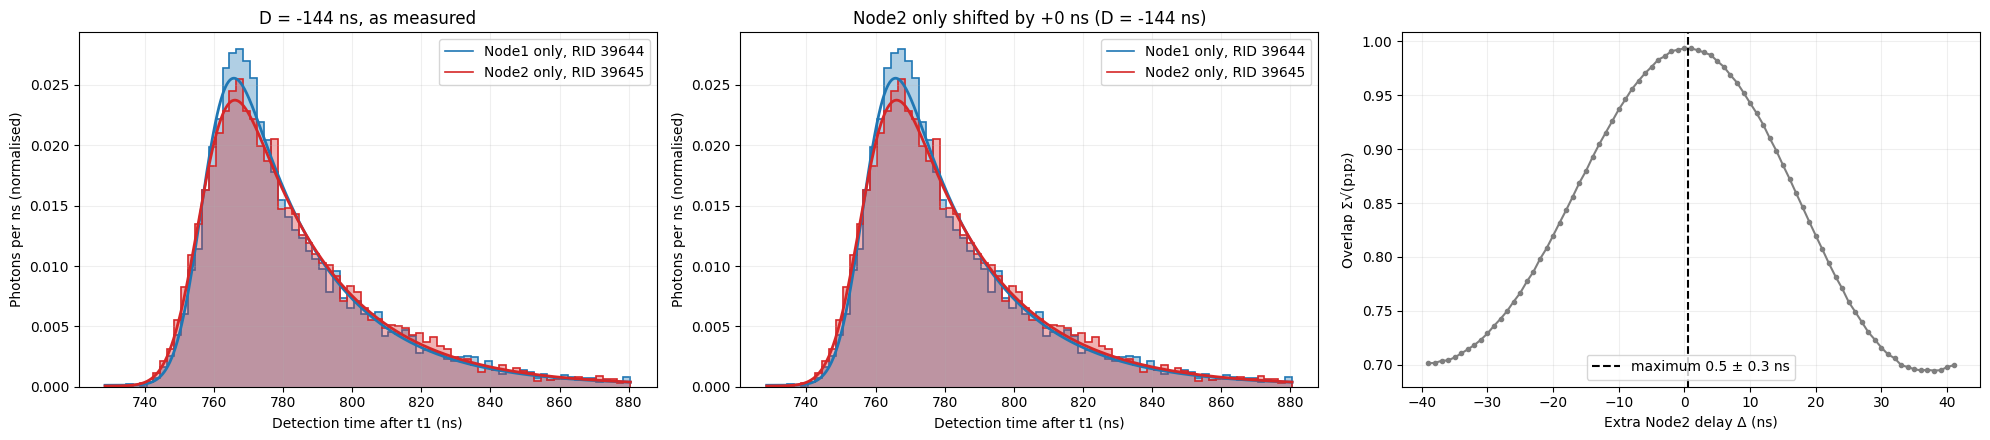

In [2]:
### the two runs to compare (numbers from the list above)
# file_index_Node1_only = 0
# file_index_Node2_only = 1
file_index_Node1_only = 8
file_index_Node2_only = 9


iterations_to_combine = {'Node1 only': None, 'Node2 only': None}  ### None: every iteration
hist_bin_ns = 2  ### whole ns
overlap_bin_ns = 1  ### whole ns
delay_search_half_range_ns = 40
min_common_fraction = 0.5
n_bootstrap = 300

timing_runs = {'Node1 only': load_hom_run(fnames[file_index_Node1_only]),
               'Node2 only': load_hom_run(fnames[file_index_Node2_only])}
expected_excitation = {'Node1 only': (True, False), 'Node2 only': (False, True)}

timing = {}
for label, run in timing_runs.items():
    describe_hom_run(run)
    times, used_iterations = arrival_times(run, iterations_to_combine[label])
    excited = {tuple(bool(x) for x in run['excited_iAll'][i]) for i in used_iterations}
    if excited != {expected_excitation[label]}: print(f"WARNING: RID {run['rid']} was selected as '{label}', but its iterations {used_iterations} excited (Node1, Node2) = {sorted(excited)}.")
    timing[label] = fit_arrival_histogram(times, hist_bin_ns)
    timing[label]['delays'] = sorted({float(run['delay_iAll'][i]) for i in used_iterations})
    t0_fit, A_fit, sigma_fit, tau_fit, B_fit = timing[label]['popt']
    t0_err, A_err, sigma_err, tau_err, B_err = timing[label]['perr']
    print(f"{label}: {len(times)} photons, recorded {timing[label]['window'][0]:.0f}..{timing[label]['window'][1]:.0f} ns after t1, "
          f"t₀ = {t0_fit:.2f} ± {t0_err:.2f} ns, σ = {sigma_fit:.2f} ns, τ = {tau_fit:.2f} ns, peak at {timing[label]['t_peak']:.1f} ns\n")

if timing['Node1 only']['delays'] != timing['Node2 only']['delays']: print(f"WARNING: the two runs used different delays D: {timing['Node1 only']['delays']} vs {timing['Node2 only']['delays']}. Node1's photons do not depend on D, but compare runs with one D.")
delay_used = timing['Node2 only']['delays'][0]

### The extra Node2 delay for the best overlap, as in 2026_Compare_Single_Photon_Arrival_Timing
result1, result2 = timing['Node1 only'], timing['Node2 only']
delay_t0 = result1['popt'][0]-result2['popt'][0]
delay_t0_err = np.hypot(result1['perr'][0], result2['perr'][0])
delays = np.arange(np.round(delay_t0)-delay_search_half_range_ns, np.round(delay_t0)+delay_search_half_range_ns+1)
overlaps = overlap_vs_delay(result1['times'], result1['window'], result2['times'], result2['window'], delays, overlap_bin_ns, min_common_fraction)
if not np.any(np.isfinite(overlaps)): raise ValueError('No extra delay lets the two recorded windows share enough photons; check both histograms above.')
best_delay = refine_peak(delays, overlaps)
best_delay_whole = float(np.round(best_delay))+0.0  ### +0.0: no '-0'
rng = np.random.default_rng(0)
near_delays = np.arange(best_delay_whole-8, best_delay_whole+9)
bootstrap_delays = np.array([refine_peak(near_delays, overlap_vs_delay(rng.choice(result1['times'], len(result1['times'])), result1['window'],
                                                                     rng.choice(result2['times'], len(result2['times'])), result2['window'],
                                                                     near_delays, overlap_bin_ns, min_common_fraction)) for b in range(n_bootstrap)])
best_delay_err = float(np.nanstd(bootstrap_delays, ddof=1))

print(f"Extra Node2 delay for the best overlap: Δ = {best_delay_whole:.0f} ns (histogram-overlap maximum {best_delay:.1f} ± {best_delay_err:.1f} ns, statistical; t₀ difference {delay_t0:.1f} ± {delay_t0_err:.1f} ns)")
print(f"    these runs used D = {delay_used:.0f} ns, so the photons coincide at D = {delay_used+best_delay_whole:.0f} ns: "
      f"t_Node2_excitation_delay_mu = {delay_used+best_delay_whole+float(timing_runs['Node2 only']['t_Node2_rtio_offset_mu']):.0f} "
      f"(with t_Node2_rtio_offset_mu = {timing_runs['Node2 only']['t_Node2_rtio_offset_mu']})")

fig, axs = plt.subplots(1, 3, figsize=(20, 4.5))
for panel, (ax, shift) in enumerate(zip(axs[:2], [0.0, best_delay_whole])):
    for label, result in timing.items():
        density = result['counts']/(result['counts'].sum()*result['bin_ns'])
        this_shift = shift if label == 'Node2 only' else 0.0
        ax.stairs(density, result['edges']+this_shift, fill=True, color=RUN_COLORS[label], alpha=0.35)
        ax.stairs(density, result['edges']+this_shift, color=RUN_COLORS[label], lw=1.2,
                  label=f"{label}, RID {timing_runs[label]['rid']}" + (f", shifted {this_shift:+g} ns" if this_shift else ''))
        fit_x = np.linspace(result['edges'][0], result['edges'][-1], 2000)
        ax.plot(fit_x+this_shift, gauss_exp_conv(fit_x, *result['popt'])/(result['counts'].sum()*result['bin_ns']), color=RUN_COLORS[label], lw=2)
    ax.set_title(f'D = {delay_used:.0f} ns, as measured' if panel == 0 else f'Node2 only shifted by {shift:+g} ns (D = {delay_used+shift:.0f} ns)')
    ax.set_xlabel('Detection time after t1 (ns)')
    ax.set_ylabel('Photons per ns (normalised)')
    ax.legend()
    ax.grid(alpha=0.2)
axs[2].plot(delays, overlaps, 'o-', color='tab:gray', ms=3)
axs[2].axvline(best_delay, color='black', ls='--', label=f'maximum {best_delay:.1f} ± {best_delay_err:.1f} ns')
axs[2].set_xlabel('Extra Node2 delay Δ (ns)')
axs[2].set_ylabel('Overlap Σ√(p₁p₂)')
axs[2].legend(loc='lower center')
axs[2].grid(alpha=0.2)
plt.tight_layout()
plt.show()

## B. HOM: coincidences against the Node2 delay
Runs with both nodes excited, scanning t_Node2_excitation_delay_mu. In every attempt row a coincidence is a click on both SPCMs of a pair. H1H2 + V1V2 (same polarisation, opposite ports) dips where the photons overlap; H1V2 + V1H2 is the cross-polarised reference. Counts are given per excitation cycle, in %: the attempts in a cycle are only there to raise that cycle's chance of a coincidence, so the cycle is what a success probability refers to (heralding atom–atom entanglement this way succeeds in at most 50% of cycles). Since that chance grows with n_excitation_attempts, the runs combined must all use the same value. Since 2026-10-29 a click ends a cycle's attempts, where earlier runs played every attempt, so B warns when the selection mixes runs from before and after. The dip is fitted with y_far·(1 − V·exp(−(D−D₀)²/2s²)) as in June. The plot and the fit use D + 144 ns (`x_offset_ns`), so the overlap delay found in A sits at 0; `show_reference` turns the cross-polarised points on or off.

Below the dip: the photon events per excitation cycle at each delay (attempts with a click on any SPCM over counted cycles, as June's "Overal photon detection efficiency"). The arrival histograms, file by file, are in C.

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
11 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 33300 attempts, 932 photon rows
    iteration 1: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 32520 attempts, 915 photon rows
    iteration 2: D = -159 ns, excited: both, shared gate t1+631..t1+800 mu, 37800 attempts, 1034 photon rows
    iteration 3: D = -154 ns, excited: both, shared gate t1+636..t1+800 mu, 32520 attempts, 867 photon rows
    iteration 4: D = -149 ns, excited: both, shared gate t1+641..t1+800 mu, 36000 attempts, 954 photon rows
    iteration 5: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 29580 attempts, 758 photon rows
    iteration 6: D = -139 ns, excited: both, shared gate t1+650..t1+801 mu, 25380 atte

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
11 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 25740 attempts, 708 photon rows
    iteration 1: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 25860 attempts, 635 photon rows
    iteration 2: D = -159 ns, excited: both, shared gate t1+631..t1+800 mu, 20580 attempts, 517 photon rows
    iteration 3: D = -154 ns, excited: both, shared gate t1+636..t1+800 mu, 24300 attempts, 617 photon rows
    iteration 4: D = -149 ns, excited: both, shared gate t1+641..t1+800 mu, 27000 attempts, 705 photon rows
    iteration 5: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 27720 attempts, 712 photon rows
    iteration 6: D = -139 ns, excited: both, shared gate t1+650..t1+801 mu, 29640 attem

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
11 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 26100 attempts, 669 photon rows
    iteration 1: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 26460 attempts, 661 photon rows
    iteration 2: D = -159 ns, excited: both, shared gate t1+631..t1+800 mu, 21540 attempts, 548 photon rows
    iteration 3: D = -154 ns, excited: both, shared gate t1+636..t1+800 mu, 27000 attempts, 724 photon rows
    iteration 4: D = -149 ns, excited: both, shared gate t1+641..t1+800 mu, 26460 attempts, 721 photon rows
    iteration 5: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 24180 attempts, 637 photon rows
    iteration 6: D = -139 ns, excited: both, shared gate t1+650..t1+801 mu, 22800 attem

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
2 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 22380 attempts, 562 photon rows
    iteration 1: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 26100 attempts, 662 photon rows


override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
11 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 24120 attempts, 612 photon rows
    iteration 1: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 24900 attempts, 639 photon rows
    iteration 2: D = -159 ns, excited: both, shared gate t1+631..t1+800 mu, 20700 attempts, 522 photon rows
    iteration 3: D = -154 ns, excited: both, shared gate t1+636..t1+800 mu, 21060 attempts, 502 photon rows
    iteration 4: D = -149 ns, excited: both, shared gate t1+641..t1+800 mu, 21480 attempts, 530 photon rows
    iteration 5: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 20100 attempts, 477 photon rows
    iteration 6: D = -139 ns, excited: both, shared gate t1+650..t1+801 mu, 20040 attem

...

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 0.4*ms}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
2 iterations x 500 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -214 ns, excited: both, shared gate t1+576..t1+800 mu, 66540 attempts, 1647 photon rows
    iteration 1: D = -74 ns, excited: both, shared gate t1+650..t1+866 mu, 60000 attempts, 1516 photon rows


override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 0.4*ms}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
13 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -214 ns, excited: both, shared gate t1+576..t1+800 mu, 30480 attempts, 760 photon rows
    iteration 1: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 39360 attempts, 1150 photon rows
    iteration 2: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 33000 attempts, 938 photon rows
    iteration 3: D = -159 ns, excited: both, shared gate t1+631..t1+800 mu, 27360 attempts, 632 photon rows
    iteration 4: D = -154 ns, excited: both, shared gate t1+636..t1+800 mu, 34140 attempts, 924 photon rows
    iteration 5: D = -149 ns, excited: both, shared gate t1+641..t1+800 mu, 35760 attempts, 881 photon rows
    iteration 6: D = -144 ns, excited: both, shared ga

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 0.4*ms}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
2 iterations x 500 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -214 ns, excited: both, shared gate t1+576..t1+800 mu, 123660 attempts, 3396 photon rows
    iteration 1: D = -74 ns, excited: both, shared gate t1+650..t1+866 mu, 142680 attempts, 4065 photon rows


override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 0.4*ms}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
13 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -214 ns, excited: both, shared gate t1+576..t1+800 mu, 56880 attempts, 1480 photon rows
    iteration 1: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 61560 attempts, 1598 photon rows
    iteration 2: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 59100 attempts, 1421 photon rows
    iteration 3: D = -159 ns, excited: both, shared gate t1+631..t1+800 mu, 59280 attempts, 1532 photon rows
    iteration 4: D = -154 ns, excited: both, shared gate t1+636..t1+800 mu, 54360 attempts, 1495 photon rows
    iteration 5: D = -149 ns, excited: both, shared gate t1+641..t1+800 mu, 50520 attempts, 1262 photon rows
    iteration 6: D = -144 ns, excited: both, shar

override Node1: {'n_excitation_attempts': 2, 'two_atom_threshold': 31000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0, 't_OP_coil_relax_time': 0.4*ms}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
13 iterations x 200 measurements, scanned over t_Node2_excitation_delay_mu
    iteration 0: D = -214 ns, excited: both, shared gate t1+576..t1+800 mu, 58200 attempts, 1655 photon rows
    iteration 1: D = -184 ns, excited: both, shared gate t1+606..t1+800 mu, 57000 attempts, 1526 photon rows
    iteration 2: D = -164 ns, excited: both, shared gate t1+626..t1+800 mu, 53760 attempts, 1484 photon rows
    iteration 3: D = -159 ns, excited: both, shared gate t1+631..t1+800 mu, 52980 attempts, 1319 photon rows
    iteration 4: D = -154 ns, excited: both, shared gate t1+636..t1+800 mu, 48600 attempts, 1160 photon rows
    iteration 5: D = -149 ns, excited: both, shared gate t1+641..t1+800 mu, 58440 attempts, 1514 photon rows
    iteration 6: D = -144 ns, excited: both, shar

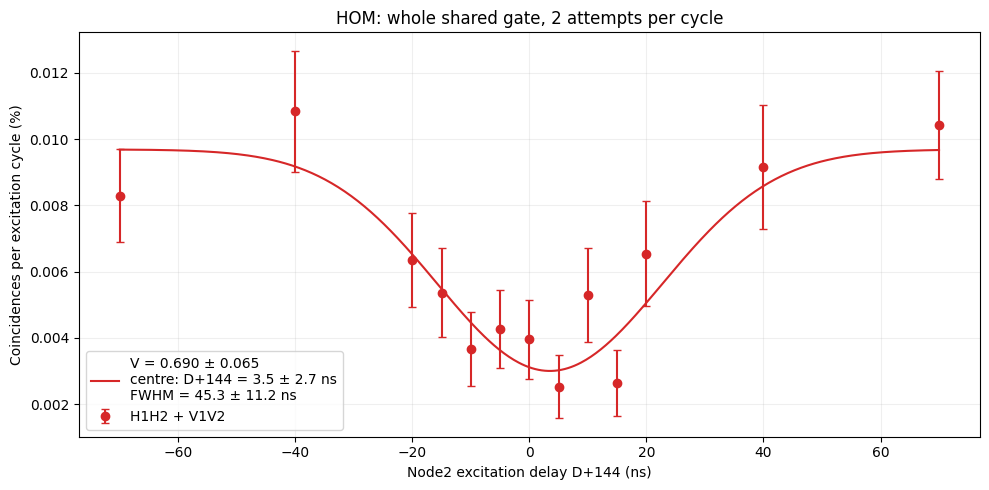

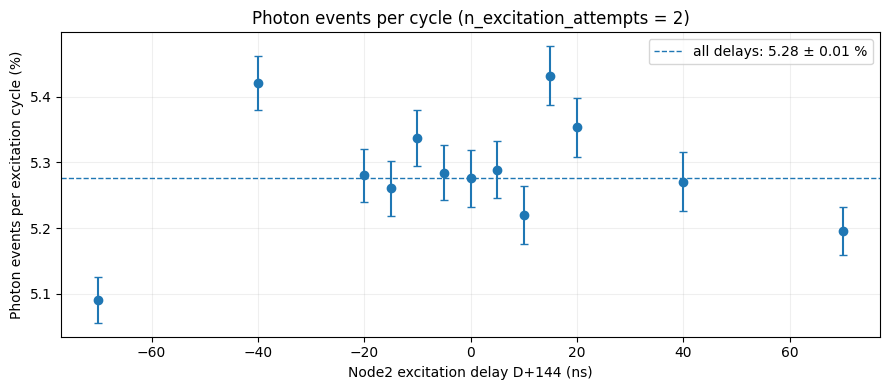

In [108]:
### runs to combine (numbers from the list above); points with the same D are added up
# file_indices = [10]  ##perfect overlap; one point
### 12 (RID 39699) is left out: it ran 5 attempts per cycle, the others 2,
### and coincidences per cycle need one n_excitation_attempts
file_indices = [
                13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
               34, 35, 36, 37, 38, 39, 40, 41, 42 ## t=0.4ms
               ] 

### Count a coincidence only when BOTH clicks fall in this range after t1 (ns).
### None counts the whole shared gate, which widens with |D|, so the
### accidental background does too.
coincidence_window_ns = None
# coincidence_window_ns = (740, 900)

fit_dip = True

### plot and fit against D + x_offset_ns, so the delay where the photons
### overlap (D = -144 ns, section A) sits at 0; 0 plots plain D
x_offset_ns = 144

### also plot the cross-polarised pairs H1V2 + V1H2
show_reference = False

PAIRS = {'H1H2': ('SPCM0', 'SPCM0_OtherNode'), 'V1V2': ('SPCM1', 'SPCM1_OtherNode'),
         'H1V2': ('SPCM0', 'SPCM1_OtherNode'), 'V1H2': ('SPCM1', 'SPCM0_OtherNode'),
         'H1V1': ('SPCM0', 'SPCM1'), 'H2V2': ('SPCM0_OtherNode', 'SPCM1_OtherNode')}

totals = {}
attempts_per_cycle = {}  ### n_excitation_attempts: RIDs
attempt_rules = {}  ### click_ends_cycle: RIDs
for file_index in file_indices:
    run = load_hom_run(fnames[file_index])
    describe_hom_run(run)
    attempts_per_cycle.setdefault(int(run['n_excitation_attempts']), []).append(run['rid'])
    attempt_rules.setdefault(bool(run['click_ends_cycle']), []).append(run['rid'])
    for i in range(run['iterations']):
        if tuple(bool(x) for x in run['excited_iAll'][i]) != (True, True):
            print(f"    skipping RID {run['rid']} iteration {i}: not both nodes excited")
            continue
        rows = run['rows'][i]
        clicked = {}
        for name in SPCM_NAMES:
            clicked[name] = np.isfinite(rows[name])
            if coincidence_window_ns is not None:
                clicked[name] &= (rows[name] >= coincidence_window_ns[0]) & (rows[name] <= coincidence_window_ns[1])
        entry = totals.setdefault(float(run['delay_iAll'][i]), dict({'attempts': 0, 'cycles': 0, 'rows': 0, 'photon_events': 0}, **{pair: 0 for pair in PAIRS}))
        entry['attempts'] += int(run['attempts_iAll'][i])
        entry['cycles'] += int(run['attempts_iAll'][i])//int(run['n_excitation_attempts'])
        entry['rows'] += len(rows['SPCM0'])
        ### attempts with a click on any SPCM anywhere in the gate (coincidence_window_ns not applied)
        entry['photon_events'] += int(np.count_nonzero(np.any([np.isfinite(rows[name]) for name in SPCM_NAMES], axis=0)))
        for pair, (a, b) in PAIRS.items(): entry[pair] += int(np.count_nonzero(clicked[a] & clicked[b]))

if not totals: raise ValueError('No iteration with both nodes excited in the selected runs.')
if len(attempts_per_cycle) > 1:
    raise ValueError('The selected runs used different n_excitation_attempts ('
                     + '; '.join(f"{n}: RID {', '.join(str(rid) for rid in rids)}" for n, rids in sorted(attempts_per_cycle.items()))
                     + '). Coincidences and photons per cycle grow with the attempts in a cycle, so select runs with one value.')
if len(attempt_rules) > 1:
    print('WARNING: the selected runs mix the two attempt rules. Before 2026-10-29 every attempt of a cycle was played '
          f"(RID {', '.join(str(rid) for rid in attempt_rules[False])}); since then a click ends the cycle's attempts "
          f"(RID {', '.join(str(rid) for rid in attempt_rules[True])}). Their coincidences per cycle are not quite the "
          'same measurement, so analyse them separately.')

x = np.array(sorted(totals))
attempts = np.array([totals[d]['attempts'] for d in x], dtype=float)
cycles = np.array([totals[d]['cycles'] for d in x], dtype=float)
photon_events = np.array([totals[d]['photon_events'] for d in x], dtype=float)
counts = {pair: np.array([totals[d][pair] for d in x], dtype=float) for pair in PAIRS}
hom_counts = counts['H1H2']+counts['V1V2']
cross_counts = counts['H1V2']+counts['V1H2']

### Photon events per excitation cycle, as June's "Overal photon detection
### efficiency": attempts with a click on any SPCM over counted cycles
### (n_excitation_cycles + 1), which include the cycles run after an atom was
### lost, up to the next atom check
photons_per_cycle = photon_events/cycles
photons_per_cycle_err = np.sqrt(photon_events)/cycles
total_photons_per_cycle = photon_events.sum()/cycles.sum()
total_photons_per_cycle_err = np.sqrt(photon_events.sum())/cycles.sum()
attempts_label = ', '.join(str(n) for n in sorted(attempts_per_cycle))

x_name = 'D' if x_offset_ns == 0 else f'D{x_offset_ns:+g}'
print(f"{'D (ns)':>8} {x_name:>7} {'cycles':>10} {'attempts':>12} {'rows':>9} " + ' '.join(f'{p:>6}' for p in PAIRS) + f" {'HH+VV':>7} {'HV+VH':>7} {'ph/cyc %':>8}")
for k, d in enumerate(x):
    print(f"{d:8.0f} {d+x_offset_ns:7.0f} {cycles[k]:10.0f} {attempts[k]:12.0f} {totals[d]['rows']:9d} " + ' '.join(f'{counts[p][k]:6.0f}' for p in PAIRS) + f" {hom_counts[k]:7.0f} {cross_counts[k]:7.0f} {100*photons_per_cycle[k]:8.2f}")
print(f"\nPhoton events per excitation cycle: {100*total_photons_per_cycle:.2f} ± {100*total_photons_per_cycle_err:.2f} % "
      f"({100*photon_events.sum()/attempts.sum():.2f} % per attempt, n_excitation_attempts = {attempts_label})")

### coincidences per excitation cycle, in %, Poisson errors (at least 1 count).
### The attempts in a cycle only raise that cycle's chance of a coincidence, so
### the cycle is what a success probability refers to: heralding atom-atom
### entanglement this way succeeds in at most 50% of cycles. Counted cycles
### include those run after an atom was lost, up to the next atom check (as for
### the photons per cycle below); two coincidences in one cycle would count
### twice, which is negligible at these rates.
scale = 100/cycles
hom_rate, hom_err = hom_counts*scale, np.sqrt(np.maximum(hom_counts, 1))*scale
cross_rate, cross_err = cross_counts*scale, np.sqrt(np.maximum(cross_counts, 1))*scale

x_plot = x + x_offset_ns

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(x_plot, hom_rate, yerr=hom_err, fmt='o', color='tab:red', capsize=3, label='H1H2 + V1V2')
if show_reference:
    ax.errorbar(x_plot, cross_rate, yerr=cross_err, fmt='s', color='tab:gray', capsize=3, alpha=0.7, label='H1V2 + V1H2 (reference)')

def hom_dip(d, y_far, V, d0, s): return y_far*(1-V*np.exp(-(d-d0)**2/(2*s**2)))

if fit_dip and len(x) >= 5:
    p0 = [np.max(hom_rate), 0.5, x_plot[np.argmin(hom_rate)], 15.0]
    popt, pcov = curve_fit(hom_dip, x_plot, hom_rate, p0=p0, sigma=hom_err, absolute_sigma=True,
                           bounds=([0, 0, x_plot.min(), 1.0], [np.inf, 1.0, x_plot.max(), np.ptp(x_plot)]), maxfev=100000)
    perr = np.sqrt(np.diag(pcov))
    chi2_red = np.sum(((hom_rate-hom_dip(x_plot, *popt))/hom_err)**2)/max(len(x)-4, 1)
    fine_x = np.linspace(x_plot.min(), x_plot.max(), 500)
    ax.plot(fine_x, hom_dip(fine_x, *popt), color='tab:red', lw=1.5,
            label=f'V = {popt[1]:.3f} ± {perr[1]:.3f}\ncentre: {x_name} = {popt[2]:.1f} ± {perr[2]:.1f} ns\nFWHM = {2.3548*popt[3]:.1f} ± {2.3548*perr[3]:.1f} ns')
    print(f"\nHOM dip: V = {popt[1]:.3f} ± {perr[1]:.3f}, centre at {x_name} = {popt[2]:.1f} ± {perr[2]:.1f} ns, FWHM = {2.3548*popt[3]:.1f} ± {2.3548*perr[3]:.1f} ns, "
          f"far level {popt[0]:.4f} % per cycle, χ²/dof = {chi2_red:.2f}")
elif fit_dip:
    print('\nToo few delays for the dip fit (needs 5).')

ax.set_xlabel(f'Node2 excitation delay {x_name} (ns)')
ax.set_ylabel('Coincidences per excitation cycle (%)')
ax.set_title('HOM: ' + ('whole shared gate' if coincidence_window_ns is None else f'both clicks in t1+{coincidence_window_ns[0]}..{coincidence_window_ns[1]} ns')
             + f', {attempts_label} attempts per cycle')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Photon events per cycle at each delay; the arrival histograms are in C
fig, ax = plt.subplots(figsize=(9, 4))
ax.errorbar(x_plot, 100*photons_per_cycle, yerr=100*photons_per_cycle_err, fmt='o', color='tab:blue', capsize=3)
ax.axhline(100*total_photons_per_cycle, color='tab:blue', ls='--', lw=1,
           label=f'all delays: {100*total_photons_per_cycle:.2f} ± {100*total_photons_per_cycle_err:.2f} %')
ax.set_xlabel(f'Node2 excitation delay {x_name} (ns)')
ax.set_ylabel('Photon events per excitation cycle (%)')
ax.set_title(f'Photon events per cycle (n_excitation_attempts = {attempts_label})')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### B.1. HOM with first-attempt photons only
B again, but only the photon rows of each cycle's first attempt are kept (`attempt_to_keep`); the later attempts are rejected. Since 2026-10-29 every HOM run records each row's attempt (`excitation_attempt_of_row`), and B.1 needs that: older runs are listed and left out, because their t1 timing places only about a third of the rows. The coincidences are per excitation cycle, as in B: every cycle has exactly one first attempt. The same runs' coincidences from every attempt are drawn in grey for comparison. B's settings apply (coincidence window, x offset, fit, reference pairs), so run B first.

In [109]:
### runs to combine: B's selection by default. Runs without a recorded
### attempt per photon row (before 2026-10-29) are listed and left out.
first_attempt_file_indices = file_indices
### the attempt kept from each cycle: 0 = the first
attempt_to_keep = 0

### B's coincidence_window_ns, x_offset_ns, fit_dip, show_reference, PAIRS
### and hom_dip are used as they are
kept_label = 'first attempt' if attempt_to_keep == 0 else f'attempt {attempt_to_keep + 1}'
totals_B1 = {}
unsplit_rids = []
attempts_per_cycle_B1 = {}  ### n_excitation_attempts: RIDs
for file_index in first_attempt_file_indices:
    run = load_hom_run(fnames[file_index])
    if not run['attempt_recorded']:
        unsplit_rids.append(run['rid'])
        continue
    describe_hom_run(run)
    attempts_per_cycle_B1.setdefault(int(run['n_excitation_attempts']), []).append(run['rid'])
    for i in range(run['iterations']):
        if tuple(bool(x) for x in run['excited_iAll'][i]) != (True, True):
            print(f"    skipping RID {run['rid']} iteration {i}: not both nodes excited")
            continue
        rows = run['rows'][i]
        kept = rows['attempt'] == attempt_to_keep
        clicked = {}
        for name in SPCM_NAMES:
            clicked[name] = np.isfinite(rows[name])
            if coincidence_window_ns is not None:
                clicked[name] &= (rows[name] >= coincidence_window_ns[0]) & (rows[name] <= coincidence_window_ns[1])
        entry = totals_B1.setdefault(float(run['delay_iAll'][i]), dict({'cycles': 0, 'rows': 0, 'rows kept': 0},
                                     **{f'{pair} {part}': 0 for pair in PAIRS for part in ('all', 'kept')}))
        entry['cycles'] += int(run['attempts_iAll'][i])//int(run['n_excitation_attempts'])
        entry['rows'] += len(rows['SPCM0'])
        entry['rows kept'] += int(np.count_nonzero(kept))
        for pair, (a, b) in PAIRS.items():
            both = clicked[a] & clicked[b]
            entry[f'{pair} all'] += int(np.count_nonzero(both))
            entry[f'{pair} kept'] += int(np.count_nonzero(both & kept))

if unsplit_rids:
    print(f"Left out, no attempt recorded per photon row (runs before 2026-10-29): RID {', '.join(str(rid) for rid in unsplit_rids)}")
if not totals_B1:
    print('None of the selected runs records the attempt of each photon row, so B.1 has nothing to plot.')
else:
    if len(attempts_per_cycle_B1) > 1:
        raise ValueError('The selected runs used different n_excitation_attempts ('
                         + '; '.join(f"{n}: RID {', '.join(str(rid) for rid in rids)}" for n, rids in sorted(attempts_per_cycle_B1.items()))
                         + '). Coincidences per cycle grow with the attempts in a cycle, so select runs with one value.')
    attempts_label_B1 = ', '.join(str(n) for n in sorted(attempts_per_cycle_B1))

    x1 = np.array(sorted(totals_B1))
    cycles1 = np.array([totals_B1[d]['cycles'] for d in x1], dtype=float)
    rows1 = np.array([totals_B1[d]['rows'] for d in x1], dtype=float)
    rows_kept1 = np.array([totals_B1[d]['rows kept'] for d in x1], dtype=float)
    def summed(pairs, part): return np.array([sum(totals_B1[d][f'{pair} {part}'] for pair in pairs) for d in x1], dtype=float)
    hom_kept, hom_every = summed(('H1H2', 'V1V2'), 'kept'), summed(('H1H2', 'V1V2'), 'all')
    cross_kept, cross_every = summed(('H1V2', 'V1H2'), 'kept'), summed(('H1V2', 'V1H2'), 'all')

    x_name = 'D' if x_offset_ns == 0 else f'D{x_offset_ns:+g}'
    print(f"{'D (ns)':>8} {x_name:>7} {'cycles':>10} {'rows':>8} {'kept':>8} {'HH+VV':>6} {'kept':>5} {'HV+VH':>6} {'kept':>5}")
    for k, d in enumerate(x1):
        print(f"{d:8.0f} {d+x_offset_ns:7.0f} {cycles1[k]:10.0f} {rows1[k]:8.0f} {rows_kept1[k]:8.0f} {hom_every[k]:6.0f} {hom_kept[k]:5.0f} {cross_every[k]:6.0f} {cross_kept[k]:5.0f}")
    print(f"\n{kept_label}: {hom_kept.sum():.0f} of {hom_every.sum():.0f} HH+VV coincidences ({100*hom_kept.sum()/max(hom_every.sum(), 1):.1f} %), "
          f"{rows_kept1.sum():.0f} of {rows1.sum():.0f} photon rows ({100*rows_kept1.sum()/max(rows1.sum(), 1):.1f} %)")

    ### per excitation cycle, in %, Poisson errors (at least 1 count), as in B
    scale1 = 100/cycles1
    kept_rate, kept_err = hom_kept*scale1, np.sqrt(np.maximum(hom_kept, 1))*scale1
    every_rate, every_err = hom_every*scale1, np.sqrt(np.maximum(hom_every, 1))*scale1
    x1_plot = x1 + x_offset_ns

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(x1_plot, every_rate, yerr=every_err, fmt='o', mfc='none', color='tab:gray', capsize=3, alpha=0.7,
                label='H1H2 + V1V2, every attempt (as in B)')
    ax.errorbar(x1_plot, kept_rate, yerr=kept_err, fmt='o', color='tab:red', capsize=3, label=f'H1H2 + V1V2, {kept_label} only')
    if show_reference:
        ax.errorbar(x1_plot, cross_kept*scale1, yerr=np.sqrt(np.maximum(cross_kept, 1))*scale1, fmt='s', color='tab:blue', capsize=3,
                    alpha=0.7, label=f'H1V2 + V1H2, {kept_label} only (reference)')

    if fit_dip and len(x1) >= 5:
        try:
            p0 = [max(np.max(kept_rate), 1e-9), 0.5, x1_plot[np.argmin(kept_rate)], 15.0]
            popt, pcov = curve_fit(hom_dip, x1_plot, kept_rate, p0=p0, sigma=kept_err, absolute_sigma=True,
                                   bounds=([0, 0, x1_plot.min(), 1.0], [np.inf, 1.0, x1_plot.max(), np.ptp(x1_plot)]), maxfev=100000)
        except (RuntimeError, ValueError) as error:
            print(f'\nThe dip fit did not converge: {error}')
        else:
            perr = np.sqrt(np.diag(pcov))
            chi2_red = np.sum(((kept_rate-hom_dip(x1_plot, *popt))/kept_err)**2)/max(len(x1)-4, 1)
            fine_x = np.linspace(x1_plot.min(), x1_plot.max(), 500)
            ax.plot(fine_x, hom_dip(fine_x, *popt), color='tab:red', lw=1.5,
                    label=f'V = {popt[1]:.3f} ± {perr[1]:.3f}\ncentre: {x_name} = {popt[2]:.1f} ± {perr[2]:.1f} ns\nFWHM = {2.3548*popt[3]:.1f} ± {2.3548*perr[3]:.1f} ns')
            print(f"\nHOM dip, {kept_label} only: V = {popt[1]:.3f} ± {perr[1]:.3f}, centre at {x_name} = {popt[2]:.1f} ± {perr[2]:.1f} ns, "
                  f"FWHM = {2.3548*popt[3]:.1f} ± {2.3548*perr[3]:.1f} ns, far level {popt[0]:.4f} % per cycle, χ²/dof = {chi2_red:.2f}")
    elif fit_dip:
        print('\nToo few delays for the dip fit (needs 5).')

    ax.set_xlabel(f'Node2 excitation delay {x_name} (ns)')
    ax.set_ylabel('Coincidences per excitation cycle (%)')
    ax.set_title(f'HOM, {kept_label} only: '
                 + ('whole shared gate' if coincidence_window_ns is None else f'both clicks in t1+{coincidence_window_ns[0]}..{coincidence_window_ns[1]} ns')
                 + f', {attempts_label_B1} attempts per cycle')
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

Left out, no attempt recorded per photon row (runs before 2026-10-29): RID 39737, 39740, 39743, 39746, 39749, 39752, 39755, 39758, 39761, 39764, 39767, 39771, 39822, 39824, 39826, 39828, 39830, 39832, 39834, 39836, 39838, 39913, 39915, 39917, 39919, 39921, 39923, 39925, 39927, 39929
None of the selected runs records the attempt of each photon row, so B.1 has nothing to plot.


### B.2. HOM with first-attempt photons, older runs (attempt from timing)
Runs from before 2026-10-29 do not record each photon's attempt, but their loop timing is regular enough to read it back. Within a measurement the gap between two photon rows' t1 is k cycles + m atom checks + (a₂ − a₁) attempts: in RID 39927 the attempts are 134.06 µs apart, a cycle is 1771.5 µs and an atom check adds 20.56 ms, each to about 2 µs. The next-best explanation of any gap is at least 129 µs off, and reading the attempt difference across a skipped row agreed with the chained one for all 21,999 tested rows (39737, 39824, 39913, 39927). Chaining the differences places every row RELATIVE to the first of its measurement.

The limit: when every photon of a measurement came from the same attempt, timing cannot tell whether that was the first or the second (moving the whole measurement by one attempt fits equally well). Those rows are **ambiguous**. Since the second attempt gives only ~0.37 of the first's photons per node, they are most likely first-attempt, so the red points count them as first attempt; the open red points use only the exactly placed ones (a lower bound). Grey: every attempt, as in B.

Only for runs where every attempt of a cycle was played (before 2026-10-29): since then a click ends the cycle, cycle lengths vary, and the attempt is recorded anyway (B.1). B's settings apply, so run B first.

RID 39737: attempts 134.05 us apart, cycle 3254.31 us, atom check every 30 cycles adds 20952.5 us; 96.5 % of gaps explained; attempt exact for 77.5 % of rows, ambiguous 22.5 %, unplaced 0.0 %
RID 39740: attempts 134.04 us apart, cycle 3254.31 us, atom check every 30 cycles adds 20952.5 us; 96.8 % of gaps explained; attempt exact for 72.0 % of rows, ambiguous 28.0 %, unplaced 0.0 %
RID 39743: attempts 134.10 us apart, cycle 3254.30 us, atom check every 30 cycles adds 20952.7 us; 97.1 % of gaps explained; attempt exact for 72.2 % of rows, ambiguous 27.8 %, unplaced 0.0 %
RID 39746: attempts 134.08 us apart, cycle 3254.29 us, atom check every 30 cycles adds 20952.9 us; 97.4 % of gaps explained; attempt exact for 71.6 % of rows, ambiguous 28.4 %, unplaced 0.0 %
RID 39749: attempts 134.10 us apart, cycle 3254.30 us, atom check every 30 cycles adds 20952.7 us; 97.9 % of gaps explained; attempt exact for 66.6 % of rows, ambiguous 33.4 %, unplaced 0.0 %
RID 39752: attempts 134.10 us apart, cyc

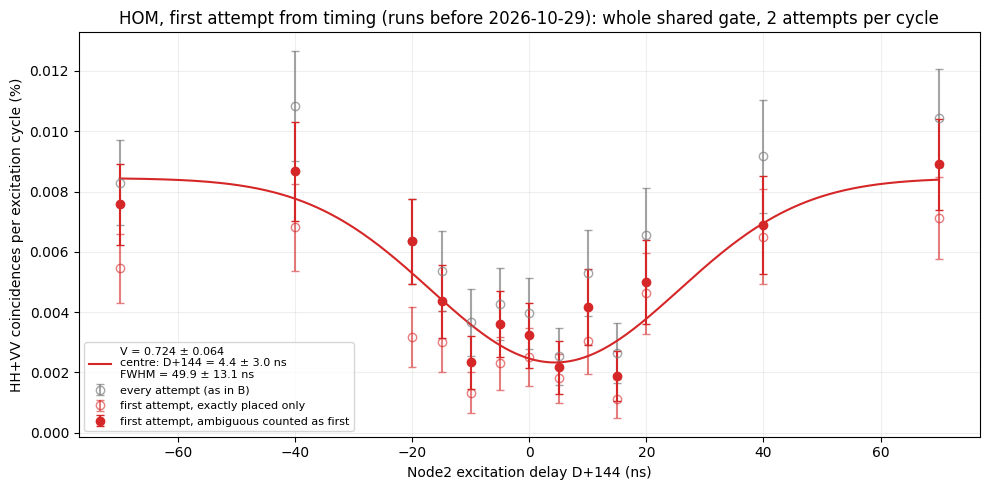

In [110]:
### runs to combine: B's selection by default. Only runs from before 2026-10-29
### (every attempt played); later ones are listed and left out, use B.1.
old_first_attempt_file_indices = file_indices
### a gap must match k cycles + m checks + attempts to this (ns)
timing_tolerance_ns = 5000


def lattice_constants(t1_ns, measurement, n_att):
    """Attempt spacing, cycle period and the atom-check delay modulo the cycle
    period, from the gaps between consecutive photon rows of a measurement."""
    same = measurement[1:] == measurement[:-1]
    gaps = np.diff(t1_ns)[same]
    T_att = float(np.median(gaps[gaps < 1e6]))
    ### the cycle period: the histogram peak that explains the most short gaps
    short = gaps[(gaps > n_att*T_att + 5e4) & (gaps < 15e6)]
    counts, edges = np.histogram(short, bins=np.arange(short.min(), short.min() + 6e6, 2000))
    def explained(Tc, x):
        k = np.maximum(np.round(x/Tc), 1)
        best = np.full(len(x), np.inf)
        for kk in (k - 1, k, k + 1):
            for a in range(-(n_att - 1), n_att):
                best = np.minimum(best, np.abs(x - kk*Tc - a*T_att))
        return best < 3000
    candidates = edges[np.argsort(counts)[::-1][:20]] + 1000
    Tc = max(candidates, key=lambda c: (explained(c, short).mean(), -c))
    fit = explained(Tc, short)
    k = np.round(short[fit]/Tc)
    a = np.round((short[fit] - k*Tc)/T_att)
    Tc = float(np.sum((short[fit] - a*T_att)*k)/np.sum(k*k))
    ### the atom-check delay modulo Tc, from the gaps a cycle count cannot explain
    rest = gaps[gaps > 1e6]
    rest = rest[~explained(Tc, rest)]
    E, best_n = 0.0, -1
    for Ep in np.arange(0, Tc, 250.0):
        r = (rest - Ep) % Tc
        n = sum(np.sum(np.abs(((r - a*T_att + Tc/2) % Tc) - Tc/2) < 3000) for a in range(-(n_att - 1), n_att))
        if n > best_n: E, best_n = Ep, n
    r = ((rest - E) % Tc + Tc/2) % Tc - Tc/2
    if np.any(np.abs(r) < 3000): E += float(np.median(r[np.abs(r) < 3000]))
    return T_att, Tc, E % Tc


def attempts_from_timing(t1_ns, measurement, n_att, T_att, Tc, E, C):
    """Per row: the attempt when the timing fixes it (else -1), the lowest
    attempt consistent with it (-1: the chain did not fit), and the share of
    gaps explained. E is the whole atom-check delay; C the cycles between
    checks, so a gap of k cycles crosses k//C or k//C + 1 checks."""
    exact = np.full(len(t1_ns), -1)
    lowest = np.full(len(t1_ns), -1)
    n_gaps = n_fit = 0
    def close(first, rel):
        rel = np.array(rel)
        span = rel.max() - rel.min()
        if span > n_att - 1: return
        lowest[first:first+len(rel)] = rel - rel.min()
        if span == n_att - 1: exact[first:first+len(rel)] = rel - rel.min()
    first, rel = 0, [0]
    for i in range(1, len(t1_ns)):
        if measurement[i] != measurement[i-1]:
            close(first, rel); first, rel = i, [0]
            continue
        n_gaps += 1
        g, step, best = t1_ns[i] - t1_ns[i-1], None, timing_tolerance_ns
        for m in range(0, 10):
            for a in range(-(n_att - 1), n_att):
                k = round((g - m*E - a*T_att)/Tc)
                if k < 0 or not (k//C <= m <= k//C + 1): continue
                r = abs(g - k*Tc - m*E - a*T_att)
                if r < best: step, best = a, r
        if step is None:
            close(first, rel); first, rel = i, [0]
        else:
            n_fit += 1
            rel.append(rel[-1] + step)
    if len(t1_ns): close(first, rel)
    return exact, lowest, n_fit/max(n_gaps, 1)


totals_B2 = {}
newer_rids = []
attempts_per_cycle_B2 = {}  ### n_excitation_attempts: RIDs
for file_index in old_first_attempt_file_indices:
    run = load_hom_run(fnames[file_index])
    if run['click_ends_cycle']:
        newer_rids.append(run['rid'])
        continue
    n_att = int(run['n_excitation_attempts'])
    attempts_per_cycle_B2.setdefault(n_att, []).append(run['rid'])
    t1_ns = np.concatenate([run['rows'][i]['t1_ns'] for i in range(run['iterations'])])
    measurement = np.concatenate([run['rows'][i]['measurement'] for i in range(run['iterations'])])
    T_att, Tc, E_mod = lattice_constants(t1_ns, measurement, n_att)
    ### the whole check delay: the multiple of the cycle nearest the check's gate
    ### plus ~0.45 ms of coil settling and switching (20.56 ms for a 20 ms gate)
    C = int(per_iteration_value(run, 'atom_check_every_n')[0])
    E_estimate = float(per_iteration_value(run, 't_SPCM_recool_and_shot')[0])*1e9 + 4.5e5
    E = E_mod + np.round((E_estimate - E_mod)/Tc)*Tc
    exact_all, lowest_all, fitted = attempts_from_timing(t1_ns, measurement, n_att, T_att, Tc, E, C)
    print(f"RID {run['rid']}: attempts {T_att/1e3:.2f} us apart, cycle {Tc/1e3:.2f} us, atom check every {C} cycles adds {E/1e3:.1f} us; "
          f"{100*fitted:.1f} % of gaps explained; attempt exact for {100*np.mean(exact_all >= 0):.1f} % of rows, "
          f"ambiguous {100*np.mean((exact_all < 0) & (lowest_all >= 0)):.1f} %, unplaced {100*np.mean(lowest_all < 0):.1f} %")
    offset = 0
    for i in range(run['iterations']):
        rows = run['rows'][i]
        n_rows = len(rows['SPCM0'])
        exact, lowest = exact_all[offset:offset+n_rows], lowest_all[offset:offset+n_rows]
        offset += n_rows
        if tuple(bool(x) for x in run['excited_iAll'][i]) != (True, True):
            continue
        clicked = {}
        for name in SPCM_NAMES:
            clicked[name] = np.isfinite(rows[name])
            if coincidence_window_ns is not None:
                clicked[name] &= (rows[name] >= coincidence_window_ns[0]) & (rows[name] <= coincidence_window_ns[1])
        hom_rows = (clicked['SPCM0'] & clicked['SPCM0_OtherNode']) | (clicked['SPCM1'] & clicked['SPCM1_OtherNode'])
        entry = totals_B2.setdefault(float(run['delay_iAll'][i]), {'cycles': 0, 'every': 0, 'first exact': 0, 'later exact': 0, 'ambiguous': 0, 'unplaced': 0})
        entry['cycles'] += int(run['attempts_iAll'][i])//n_att
        ### HH and VV in one row would be two coincidences, as in B
        weight = (clicked['SPCM0'] & clicked['SPCM0_OtherNode']).astype(int) + (clicked['SPCM1'] & clicked['SPCM1_OtherNode']).astype(int)
        entry['every'] += int(weight.sum())
        entry['first exact'] += int(weight[exact == 0].sum())
        entry['later exact'] += int(weight[exact > 0].sum())
        entry['ambiguous'] += int(weight[(exact < 0) & (lowest == 0)].sum())
        entry['unplaced'] += int(weight[lowest < 0].sum())

if newer_rids:
    print(f"Left out, a click ends the cycle there (runs from 2026-10-29, use B.1): RID {', '.join(str(rid) for rid in newer_rids)}")
if not totals_B2:
    print('None of the selected runs is from before 2026-10-29, so B.2 has nothing to plot.')
else:
    if len(attempts_per_cycle_B2) > 1:
        raise ValueError('The selected runs used different n_excitation_attempts ('
                         + '; '.join(f"{n}: RID {', '.join(str(rid) for rid in rids)}" for n, rids in sorted(attempts_per_cycle_B2.items()))
                         + '). Coincidences per cycle grow with the attempts in a cycle, so select runs with one value.')
    x2 = np.array(sorted(totals_B2))
    def column(key): return np.array([totals_B2[d][key] for d in x2], dtype=float)
    cycles2, every2 = column('cycles'), column('every')
    first_exact2, later_exact2, ambiguous2, unplaced2 = column('first exact'), column('later exact'), column('ambiguous'), column('unplaced')
    first_likely2 = first_exact2 + ambiguous2

    x_name = 'D' if x_offset_ns == 0 else f'D{x_offset_ns:+g}'
    print(f"\n{'D (ns)':>8} {x_name:>7} {'cycles':>10} {'HH+VV':>6} {'1st':>5} {'later':>6} {'ambig':>6} {'unpl':>5}")
    for k, d in enumerate(x2):
        print(f"{d:8.0f} {d+x_offset_ns:7.0f} {cycles2[k]:10.0f} {every2[k]:6.0f} {first_exact2[k]:5.0f} {later_exact2[k]:6.0f} {ambiguous2[k]:6.0f} {unplaced2[k]:5.0f}")
    print(f"\nHH+VV coincidences: {every2.sum():.0f}; first attempt {first_exact2.sum():.0f} exact + {ambiguous2.sum():.0f} ambiguous, "
          f"later attempts {later_exact2.sum():.0f}, unplaced {unplaced2.sum():.0f}")

    ### per excitation cycle, in %, Poisson errors (at least 1 count), as in B
    scale2 = 100/cycles2
    x2_plot = x2 + x_offset_ns
    def rate(counts): return counts*scale2, np.sqrt(np.maximum(counts, 1))*scale2
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(x2_plot, *rate(every2), fmt='o', mfc='none', color='tab:gray', capsize=3, alpha=0.7, label='every attempt (as in B)')
    ax.errorbar(x2_plot, *rate(first_exact2), fmt='o', mfc='none', color='tab:red', capsize=3, alpha=0.6, label='first attempt, exactly placed only')
    likely_rate, likely_err = rate(first_likely2)
    ax.errorbar(x2_plot, likely_rate, yerr=likely_err, fmt='o', color='tab:red', capsize=3, label='first attempt, ambiguous counted as first')

    if fit_dip and len(x2) >= 5:
        for label, counts in (('ambiguous counted as first', first_likely2), ('exactly placed only', first_exact2)):
            values, errors = rate(counts)
            try:
                p0 = [max(np.max(values), 1e-9), 0.5, x2_plot[np.argmin(values)], 15.0]
                popt, pcov = curve_fit(hom_dip, x2_plot, values, p0=p0, sigma=errors, absolute_sigma=True,
                                       bounds=([0, 0, x2_plot.min(), 1.0], [np.inf, 1.0, x2_plot.max(), np.ptp(x2_plot)]), maxfev=100000)
            except (RuntimeError, ValueError) as error:
                print(f'The dip fit ({label}) did not converge: {error}')
                continue
            perr = np.sqrt(np.diag(pcov))
            chi2_red = np.sum(((values-hom_dip(x2_plot, *popt))/errors)**2)/max(len(x2)-4, 1)
            print(f"HOM dip, first attempt, {label}: V = {popt[1]:.3f} ± {perr[1]:.3f}, centre at {x_name} = {popt[2]:.1f} ± {perr[2]:.1f} ns, "
                  f"FWHM = {2.3548*popt[3]:.1f} ± {2.3548*perr[3]:.1f} ns, far level {popt[0]:.4f} % per cycle, χ²/dof = {chi2_red:.2f}")
            if label == 'ambiguous counted as first':
                fine_x = np.linspace(x2_plot.min(), x2_plot.max(), 500)
                ax.plot(fine_x, hom_dip(fine_x, *popt), color='tab:red', lw=1.5,
                        label=f'V = {popt[1]:.3f} ± {perr[1]:.3f}\ncentre: {x_name} = {popt[2]:.1f} ± {perr[2]:.1f} ns\nFWHM = {2.3548*popt[3]:.1f} ± {2.3548*perr[3]:.1f} ns')
    elif fit_dip:
        print('Too few delays for the dip fit (needs 5).')

    ax.set_xlabel(f'Node2 excitation delay {x_name} (ns)')
    ax.set_ylabel('HH+VV coincidences per excitation cycle (%)')
    ax.set_title('HOM, first attempt from timing (runs before 2026-10-29): '
                 + ('whole shared gate' if coincidence_window_ns is None else f'both clicks in t1+{coincidence_window_ns[0]}..{coincidence_window_ns[1]} ns')
                 + f", {', '.join(str(n) for n in sorted(attempts_per_cycle_B2))} attempts per cycle")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

In [17]:
np.arange(13,24,1)

array([13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23])

## C. Photon arrival, file by file
Every click of the four SPCMs in each selected file, in ns after t1, one panel per file. Every iteration is used, whichever nodes were excited, so single-node timing runs (A) can be checked here too. `arrival_lines` sets the lines in each panel: `'all'` one histogram, `'delay'` one per delay, `'spcm'` one per detector. `arrival_window_ns` shades a window, e.g. the coincidence window used in B. The clicks sit about 80 ns later than the programmed gate printed for each iteration (t1+646..800 mu records clicks from ~728 to ~880 ns in 39644/39645), so the gate is not drawn. The histograms are in clicks per ns per 10⁶ excitation cycles, per cycle like B. The title gives the photon events per excitation cycle of the file, counted as in B.

override Node1: {'n_excitation_attempts': 5, 'two_atom_threshold': 33000.0, 'target_780_HWP': 32.0, 'target_780_QWP': 75.0}
override Node2: {'target_780_HWP': 72.4, 'target_780_QWP': 210.0}
25 iterations x 100 measurements, scanned over dummy_variable
    iteration 0: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 47250 attempts, 681 photon rows
    iteration 1: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 31500 attempts, 408 photon rows
    iteration 2: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 39000 attempts, 558 photon rows
    iteration 3: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 46950 attempts, 625 photon rows
    iteration 4: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 38400 attempts, 581 photon rows
    iteration 5: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 41850 attempts, 622 photon rows
    iteration 6: D = -144 ns, excited: both, shared gate t1+646..t1+800 mu, 40800 attempts, 613 phot

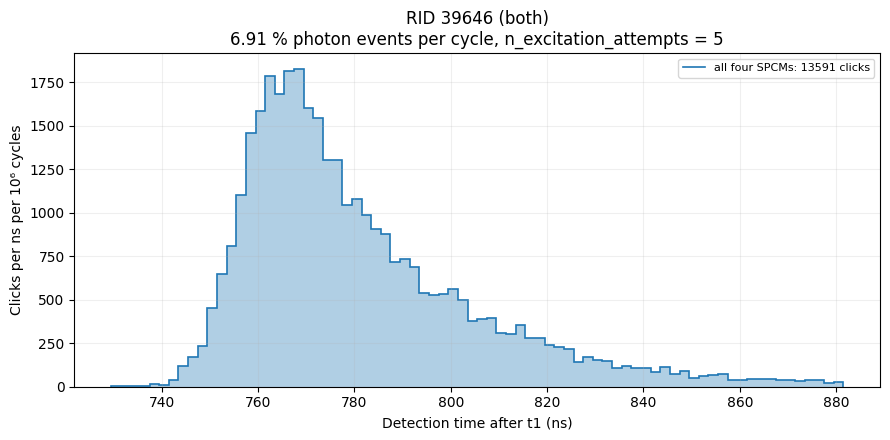

In [ ]:
### the files to check (numbers from the list above), one panel each
arrival_file_indices = [10]

arrival_hist_bin_ns = 2  ### whole ns
### 'all': one histogram per file; 'delay': one per delay; 'spcm': one per detector
arrival_lines = 'all'
### delays are labelled D + x_offset_ns, as in B
x_offset_ns = 144
### shade a window on the time axis, e.g. B's coincidence_window_ns; None for none
arrival_window_ns = None

if arrival_lines not in ('all', 'delay', 'spcm'): raise ValueError(f"arrival_lines must be 'all', 'delay' or 'spcm', not {arrival_lines!r}")

EXCITED_NAMES = {(True, True): 'both', (True, False): 'Node1 only', (False, True): 'Node2 only', (False, False): 'neither'}
SPCM_COLORS = {'SPCM0': 'tab:blue', 'SPCM1': 'tab:orange', 'SPCM0_OtherNode': 'tab:green', 'SPCM1_OtherNode': 'tab:red'}

arrival_runs = []
for file_index in arrival_file_indices:
    run = load_hom_run(fnames[file_index])
    describe_hom_run(run)
    arrival_runs.append(run)

if not arrival_runs: print('no file selected')
n_cols = max(min(2, len(arrival_runs)), 1)
n_rows = max(int(np.ceil(len(arrival_runs)/n_cols)), 1)
fig, axs = plt.subplots(n_rows, n_cols, figsize=(9*n_cols, 4.5*n_rows), squeeze=False)
for ax in axs.ravel()[len(arrival_runs):]: ax.set_visible(False)

print()
for ax, run in zip(axs.ravel(), arrival_runs):
    iterations = list(range(run['iterations']))
    attempts = int(np.sum(run['attempts_iAll']))
    cycles = attempts//int(run['n_excitation_attempts'])
    ### attempts with a click on any SPCM, over counted cycles, as in B
    photon_events = sum(int(np.count_nonzero(np.any([np.isfinite(run['rows'][i][name]) for name in SPCM_NAMES], axis=0))) for i in iterations)
    times = arrival_times(run)[0]
    excited = ', '.join(sorted({EXCITED_NAMES[tuple(bool(x) for x in e)] for e in run['excited_iAll']}))
    print(f"RID {run['rid']} ({excited}): {len(times)} clicks in {attempts} attempts ({cycles} cycles), "
          f"photon events per cycle {100*photon_events/cycles:.2f} ± {100*np.sqrt(photon_events)/cycles:.2f} %, "
          f"per attempt {100*photon_events/attempts:.2f} %")
    if len(times) == 0:
        ax.set_title(f"RID {run['rid']}: no clicks")
        continue

    edges = np.arange(np.floor(times.min())-0.5, times.max()+arrival_hist_bin_ns, arrival_hist_bin_ns)
    if arrival_lines == 'delay':
        delays = sorted({float(d) for d in run['delay_iAll']})
        groups = []
        for k, d in enumerate(delays):
            used = [i for i in iterations if float(run['delay_iAll'][i]) == d]
            label = f'D = {d:g} ns' if x_offset_ns == 0 else f'D{x_offset_ns:+g} = {d+x_offset_ns:g} ns'
            groups.append((label, arrival_times(run, used)[0], int(np.sum(run['attempts_iAll'][used]))//int(run['n_excitation_attempts']), plt.cm.viridis(k/max(len(delays)-1, 1))))
    elif arrival_lines == 'spcm':
        groups = []
        for name in SPCM_NAMES:
            clicks = np.concatenate([run['rows'][i][name] for i in iterations])
            groups.append((f'{DETECTOR_LABELS[name]} ({name})', clicks[np.isfinite(clicks)], cycles, SPCM_COLORS[name]))
    else:
        groups = [('all four SPCMs', times, cycles, 'tab:blue')]

    ### clicks per ns per 10^6 excitation cycles, as B counts per cycle
    for label, clicks, n_cycles, color in groups:
        density = np.histogram(clicks, bins=edges)[0]/arrival_hist_bin_ns/n_cycles*1e6
        if arrival_lines == 'all': ax.stairs(density, edges, fill=True, color=color, alpha=0.35)
        ax.stairs(density, edges, color=color, lw=1.2, label=f'{label}: {len(clicks)} clicks')
    if arrival_window_ns is not None: ax.axvspan(*arrival_window_ns, color='tab:orange', alpha=0.15, label='window')

    ax.set_title(f"RID {run['rid']} ({excited})\n{100*photon_events/cycles:.2f} % photon events per cycle, "
                 f"n_excitation_attempts = {int(run['n_excitation_attempts'])}")
    ax.set_xlabel('Detection time after t1 (ns)')
    ax.set_ylabel('Clicks per ns per 10⁶ cycles')
    ax.legend(fontsize=8, ncol=2 if len(groups) > 6 else 1)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## D. General analysis
Health of the selected files, whatever they scanned. Choose the files in the next cell and run it; it loads each file once. The blocks below it then only plot, in any order:
* D1. Retention and loading, per scan point
* D2. SPCM histograms (RO1 and RO2), per scan point
* D3. Atom loading time: the actual time until the first shot passes, per measurement and averaged per scan point
* D4. FORT MM and FORT APD, normalised to their set points
* D5. Excitation cycles per measurement, against the Node2 delay
* D6. Photon arrival histograms, one panel per scan point and one figure per file

With several files selected, each plot shows them one after another, as "Normalized FORT monitor for all selected files" in 2026_Single_Node_Microwaves: one colour per file, a dashed line at each file boundary.

In [84]:
{i: '' for i in range(12, 35, 1)}

{12: '',
 13: '',
 14: '',
 15: '',
 16: '',
 17: '',
 18: '',
 19: '',
 20: '',
 21: '',
 22: '',
 23: '',
 24: '',
 25: '',
 26: '',
 27: '',
 28: '',
 29: '',
 30: '',
 31: '',
 32: '',
 33: '',
 34: ''}

In [90]:
### the files to analyse (numbers from the list above): {file number: comment for the legends}
general_file_indices = {
 12: '',
 13: '',
 14: '',
 15: '',
 16: '',
 17: '',
 18: '',
 19: '',
 20: '',
 21: '',
 22: '',
 23: '',
 24: '',
 25: '',
 26: '',
 27: '',
 28: '',
 29: '',
 30: '',
 31: '',
 32: '',
 33: '',
 34: ''}
import matplotlib as mpl


def load_general_run(filename):
    """What the general-analysis blocks need from one two-node run, read once."""
    d = {}
    with h5py.File(filename, 'r') as f:
        ms_two_nodes_archive_and_datasets_to_locals(f, d, quiet=True)
        rid = int(f['rid'][()])
        ### Straight from the file. Both are seeded with one entry and filled
        ### only by confirm-by-first-shot runs, one entry per measurement;
        ### Atom_loading_time_first_shot_alive exists since 2026-10-27 20:40.
        datasets = f['datasets']
        confirm_tries = np.asarray(datasets['n_first_shot_confirm_tries'][1:], dtype=float) if 'n_first_shot_confirm_tries' in datasets else np.array([])
        first_shot_alive = np.asarray(datasets['Atom_loading_time_first_shot_alive'][1:], dtype=float) if 'Atom_loading_time_first_shot_alive' in datasets else np.array([])
        ### HOM runs (D5): the excitation loop's index at exit, one entry per
        ### measurement after its seed
        excitation_cycles = np.asarray(datasets['n_excitation_cycles'][1:], dtype=float) if 'n_excitation_cycles' in datasets else np.array([])
        ### successful loads per scan point, appended once at the end of each
        ### point after its seed (D3, to split Atom_loading_time by point)
        loads_per_point = np.asarray(datasets['n_atom_loaded_per_iteration'][1:], dtype=int) if 'n_atom_loaded_per_iteration' in datasets else np.array([], dtype=int)

    run = {'rid': rid, 'filename': filename, 'confirm_tries': confirm_tries, 'first_shot_alive': first_shot_alive,
           'n_excitation_cycles': excitation_cycles, 'n_atom_loaded_per_iteration': loads_per_point}
    for name in ('experiment_function', 'scan_variable1_name'):
        run[name] = d.get(name)
    ### older files may only hold the per-node pair
    for name in ('t_SPCM_first_shot', 't_SPCM_second_shot'):
        run[name] = d.get(name) if d.get(name) is not None else d.get(f'{name}_Node1')
    ### NaN when the run has no joint cut, so no retention is computed from it
    for name in ('two_atom_threshold', 'two_atom_threshold_for_loading'):
        run[name] = float(d[name]) if d.get(name) is not None else np.nan
    run['max_loading_rounds'] = next((d[name] for name in ('max_loading_rounds', 'max_loading_rounds_two_node') if d.get(name) is not None), None)
    ### the excitation loop's shape (HOM runs), for D5
    for name in ('atom_check_every_n', 'max_excitation_cycles', 'n_excitation_attempts'):
        run[name] = int(d[name]) if d.get(name) is not None else None
    run['n_measurements'] = int(d['n_measurements'])
    run['scan_sequence1'] = np.ravel(np.asarray(d['scan_sequence1'], dtype=float))
    run['scan_sequence2'] = np.ravel(np.asarray(d['scan_sequence2'], dtype=float))
    ### the readouts come without their seed; Atom_loading_time keeps it
    for name in ['AllSPCMs'] + SPCM_NAMES:
        for shot in ('RO1', 'RO2'):
            run[f'{name}_{shot}'] = np.ravel(np.asarray(d.get(f'{name}_{shot}', []), dtype=float))
    run['Atom_loading_time'] = np.ravel(np.asarray(d['Atom_loading_time'], dtype=float))[1:]
    for node in MASTER_SATELLITE_NODES:
        for name in ('FORT_MM_monitor', 'FORT_APD_monitor'):
            run[f'{name}_{node}'] = np.ravel(np.asarray(d.get(f'{name}_{node}', []), dtype=float))
        for name in ('best_852_power_ref', 'set_point_FORT_APD_loading'):
            run[f'{name}_{node}'] = float(d[f'{name}_{node}']) if f'{name}_{node}' in d else np.nan

    ### A point retried after an RTIO underflow leaves the aborted execution's
    ### measurements in the file: keep the last ones, as load_hom_run does, so
    ### D and B/C use the same measurements. Each series is cut from its own
    ### end: the confirm tries and first-shot times are appended before the
    ### excitation loop, the readouts after it, so an underflow in the loop
    ### leaves those two one entry longer. n_excitation_cycles comes last of all.
    run['n_points'] = len(run['scan_sequence1'])*len(run['scan_sequence2'])
    n_keep = run['n_points']*run['n_measurements']
    if len(run['AllSPCMs_RO1']) > n_keep:
        print(f"WARNING: RID {rid}: {len(run['AllSPCMs_RO1'])-n_keep} measurements more than {run['n_points']} x {run['n_measurements']}, "
              f"left by an underflow retry; using the last {n_keep}, as B and C do")
    for key in [f'{name}_{shot}' for name in ['AllSPCMs']+SPCM_NAMES for shot in ('RO1', 'RO2')] + ['confirm_tries', 'first_shot_alive', 'n_excitation_cycles']:
        if len(run[key]) > n_keep: run[key] = run[key][-n_keep:]

    ### whole scan points only: an aborted run, or one still going, ends in a partial point
    run['iterations'] = min(run['n_points'], len(run['AllSPCMs_RO1'])//run['n_measurements'])
    if run['t_SPCM_first_shot'] is None or run['t_SPCM_second_shot'] is None:
        print(f"RID {rid}: no t_SPCM_first_shot/t_SPCM_second_shot, so it is left out of D1 and D2")
        run['iterations'] = 0

    ### D5 and D6: the delay, shared gate and photon rows of each scan point,
    ### loaded as B and C load them
    run['hom'] = None
    if run['experiment_function'] == 'Two_nodes_HOM_experiment':
        try:
            run['hom'] = load_hom_run(filename)
        except ValueError as error:
            print(f"RID {rid}: {error} D5 and D6 leave it out.")
    return run


general_runs = []
for file_index, comment in general_file_indices.items():
    run = load_general_run(fnames[file_index])
    run['comment'] = comment
    general_runs.append(run)
    print(f"file {file_index}: RID {run['rid']}, {run['experiment_function']} over {run['scan_variable1_name']}, "
          f"{run['iterations']} of {run['n_points']} scan points x {run['n_measurements']} measurements, "
          f"loading check {run['two_atom_threshold_for_loading']:.0f} c/s, first-shot cut {run['two_atom_threshold']:.0f} c/s"
          + (f", {comment}" if comment else ''))


### shared by D1-D4: one colour per file, and the files plotted one after another
def file_color(k):
    return mpl.colormaps['turbo'](k/max(len(general_runs)-1, 1))


def file_label(run):
    return f"RID {run['rid']}" + (f", {run['comment']}" if run['comment'] else '')


def plot_one_after_another(ax, series, errors=None, fmt='.-', labels=True):
    """One array per selected file, plotted against a running index, each in its
    file's colour, with a dashed line at each file boundary. Returns the
    starting index of each file."""
    starts = []
    offset = 0
    for k, (run, y) in enumerate(zip(general_runs, series)):
        starts.append(offset)
        y = np.asarray(y, dtype=float)
        if len(y) == 0: continue
        x = np.arange(offset, offset+len(y))
        label = file_label(run) if labels else None
        if errors is None: ax.plot(x, y, fmt, color=file_color(k), label=label)
        else: ax.errorbar(x, y, yerr=errors[k], fmt=fmt, color=file_color(k), capsize=2, label=label)
        if offset > 0: ax.axvline(offset-0.5, color='gray', ls='--', alpha=0.4)
        offset += len(y)
    return starts

file 12: RID 39699, Two_nodes_HOM_experiment over t_Node2_excitation_delay_mu, 11 of 11 scan points x 200 measurements, loading check 95000 c/s, first-shot cut 33000 c/s
file 13: RID 39737, Two_nodes_HOM_experiment over t_Node2_excitation_delay_mu, 11 of 11 scan points x 200 measurements, loading check 95000 c/s, first-shot cut 33000 c/s
file 14: RID 39740, Two_nodes_HOM_experiment over t_Node2_excitation_delay_mu, 11 of 11 scan points x 200 measurements, loading check 95000 c/s, first-shot cut 33000 c/s
file 15: RID 39743, Two_nodes_HOM_experiment over t_Node2_excitation_delay_mu, 11 of 11 scan points x 200 measurements, loading check 100000 c/s, first-shot cut 33000 c/s
file 16: RID 39746, Two_nodes_HOM_experiment over t_Node2_excitation_delay_mu, 2 of 11 scan points x 200 measurements, loading check 100000 c/s, first-shot cut 33000 c/s
file 17: RID 39749, Two_nodes_HOM_experiment over t_Node2_excitation_delay_mu, 11 of 11 scan points x 200 measurements, loading check 100000 c/s, fir

### D1. Retention and loading
Per scan point, cut at each run's two_atom_threshold (the joint cut on the summed four-SPCM counts/s). Retention errors are 1/√(atoms loaded), as in the other notebooks. In confirm-by-first-shot runs loading is 1/mean(n_first_shot_confirm_tries), since their first shot is bright by construction. In a HOM run the excitation loop only ends once an atom check fails (or at max_excitation_cycles), so its retention is low by design.

RID 39699: cut 33000 counts/s, retention 0.004, loading 0.559 (1/mean(tries)), 11 scan points
RID 39737: cut 33000 counts/s, retention 0.007, loading 0.508 (1/mean(tries)), 11 scan points
RID 39740: cut 33000 counts/s, retention 0.005, loading 0.445 (1/mean(tries)), 11 scan points
RID 39743: cut 33000 counts/s, retention 0.006, loading 0.541 (1/mean(tries)), 11 scan points
RID 39746: cut 33000 counts/s, retention 0.015, loading 0.520 (1/mean(tries)), 2 scan points
RID 39749: cut 33000 counts/s, retention 0.006, loading 0.532 (1/mean(tries)), 11 scan points
RID 39752: cut 33000 counts/s, retention 0.006, loading 0.531 (1/mean(tries)), 7 scan points
RID 39755: cut 33000 counts/s, retention 0.005, loading 0.600 (1/mean(tries)), 11 scan points
RID 39758: cut 33000 counts/s, retention 0.005, loading 0.631 (1/mean(tries)), 11 scan points
RID 39761: cut 33000 counts/s, retention 0.010, loading 0.635 (1/mean(tries)), 11 scan points
RID 39764: cut 33000 counts/s, retention 0.017, loading 0.615 

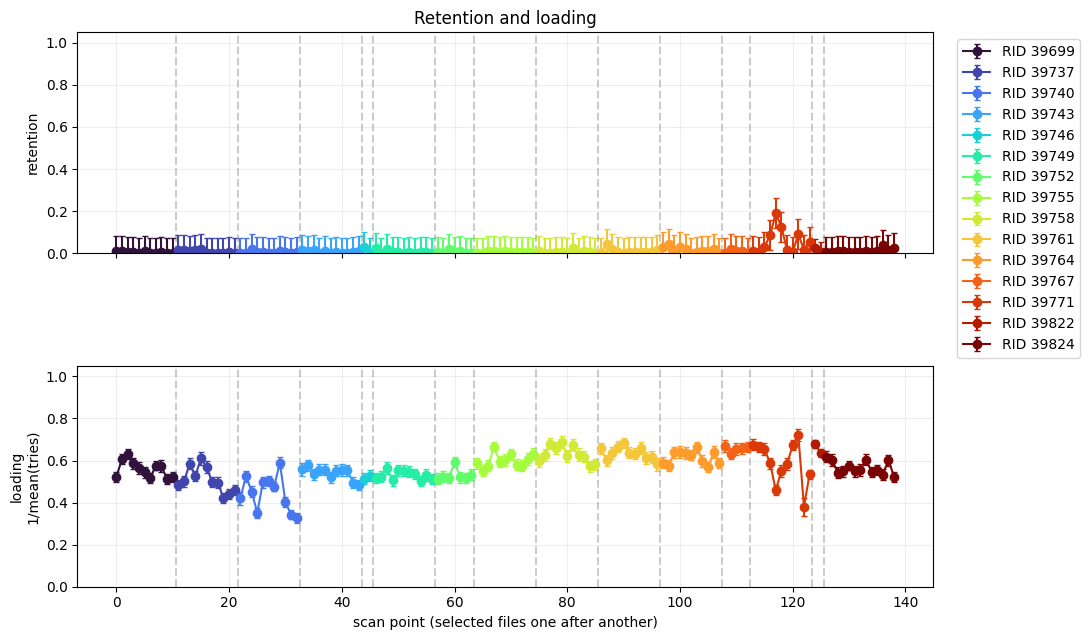

In [53]:
### Retention and loading per scan point, the selected files one after another.
### True plots against the scan variable instead, every file on one axis.
against_scan_variable = False

### The joint cut on the summed counts/s of the four SPCMs. False uses each
### run's own two_atom_threshold, the cut its first-shot confirm loop compared against.
manual_threshold = False
user_set_manual_threshold = 33000

retention_series, retention_err_series, loading_series, loading_err_series, x_series = [], [], [], [], []
loading_kinds = set()
for run in general_runs:
    n, iterations = run['n_measurements'], run['iterations']
    rate = user_set_manual_threshold if manual_threshold else run['two_atom_threshold']
    if iterations == 0 or np.isnan(rate):
        print(f"RID {run['rid']}: " + ("no whole scan point yet" if iterations == 0 else "no two_atom_threshold; set manual_threshold"))
        for series in (retention_series, retention_err_series, loading_series, loading_err_series, x_series): series.append(np.array([]))
        continue

    retention, loading_rate, n_loaded = get_loading_and_retention(run['AllSPCMs_RO1'], run['AllSPCMs_RO2'], n, iterations,
                                                                  rate*run['t_SPCM_first_shot'], cutoff2=rate*run['t_SPCM_second_shot'])
    retention = np.where(n_loaded > 0, retention, np.nan)
    retention_err = np.array([1/np.sqrt(m) if m > 0 else np.nan for m in n_loaded])

    ### A confirm-by-first-shot run retries load + first shot until the first
    ### shot is bright, so its RO1 fraction is ~1 by construction; its loading
    ### probability is 1/mean(n_first_shot_confirm_tries) per scan point.
    if len(run['confirm_tries']):
        tries = [run['confirm_tries'][i*n:(i+1)*n] for i in range(iterations)]
        loading = np.array([1/np.mean(t) for t in tries])
        loading_err = np.array([np.std(t)/np.sqrt(len(t))/np.mean(t)**2 for t in tries])
        loading_kinds.add('1/mean(tries)')
        ### a try count at the cap with a dark first shot is a give-up, which
        ### counts as a success on the last try above
        if run['max_loading_rounds'] is not None:
            used = min(len(run['confirm_tries']), len(run['AllSPCMs_RO1']), iterations*n)
            give_ups = int(np.sum((run['confirm_tries'][:used] == run['max_loading_rounds'])
                                  & (run['AllSPCMs_RO1'][:used] <= rate*run['t_SPCM_first_shot'])))
            if give_ups: print(f"RID {run['rid']}: {give_ups} measurements used all {run['max_loading_rounds']} tries without a bright first shot")
    else:
        loading, loading_err = loading_rate, np.sqrt(loading_rate*(1-loading_rate)/n)
        loading_kinds.add('RO1 above the cut')

    scan_values = run['scan_sequence1'][:iterations] if len(run['scan_sequence2']) == 1 else np.arange(iterations)
    retention_series.append(retention); retention_err_series.append(retention_err)
    loading_series.append(loading); loading_err_series.append(loading_err)
    x_series.append(scan_values)
    print(f"RID {run['rid']}: cut {rate:.0f} counts/s, retention {np.nanmean(retention):.3f}, "
          f"loading {np.mean(loading):.3f} ({'1/mean(tries)' if len(run['confirm_tries']) else 'RO1 above the cut'}), "
          f"{iterations} scan points")

fig, (ax_ret, ax_load) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
if against_scan_variable:
    for k, run in enumerate(general_runs):
        if len(x_series[k]) == 0: continue
        ax_ret.errorbar(x_series[k], retention_series[k], yerr=retention_err_series[k], fmt='o--', color=file_color(k), capsize=2, label=file_label(run))
        ax_load.errorbar(x_series[k], loading_series[k], yerr=loading_err_series[k], fmt='o--', color=file_color(k), capsize=2, label=file_label(run))
    ax_load.set_xlabel(', '.join(sorted({str(run['scan_variable1_name']) for run in general_runs})))
else:
    plot_one_after_another(ax_ret, retention_series, retention_err_series, fmt='o-')
    plot_one_after_another(ax_load, loading_series, loading_err_series, fmt='o-')
    ax_load.set_xlabel('scan point (selected files one after another)')
ax_ret.set_ylabel('retention')
ax_load.set_ylabel('loading\n' + (loading_kinds.pop() if len(loading_kinds) == 1 else '(see the printout)'))
for ax in (ax_ret, ax_load):
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.2)
ax_ret.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax_ret.set_title('Retention and loading')
plt.tight_layout()
plt.show()

### D2. SPCM histograms
RO1 and RO2 of each detector and of all four summed, per scan point.

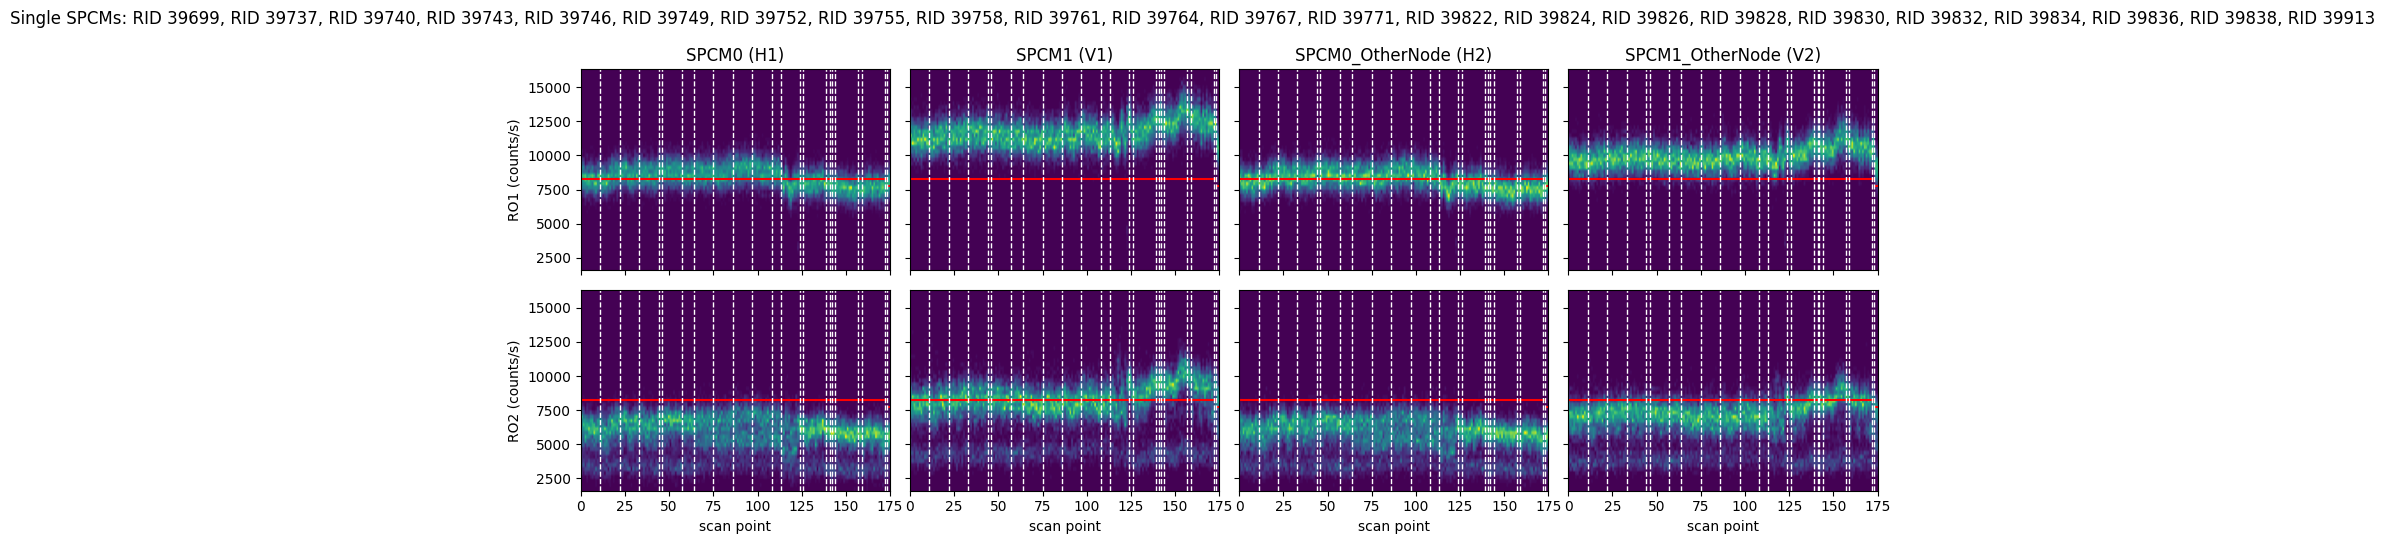

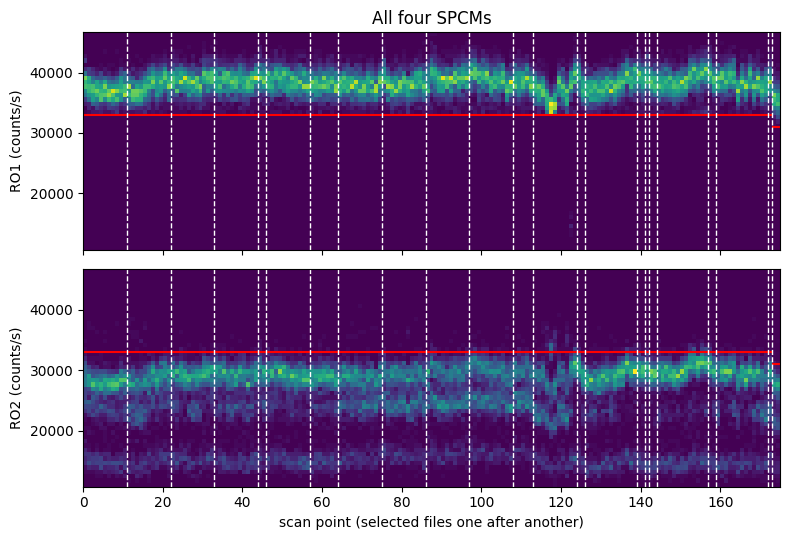

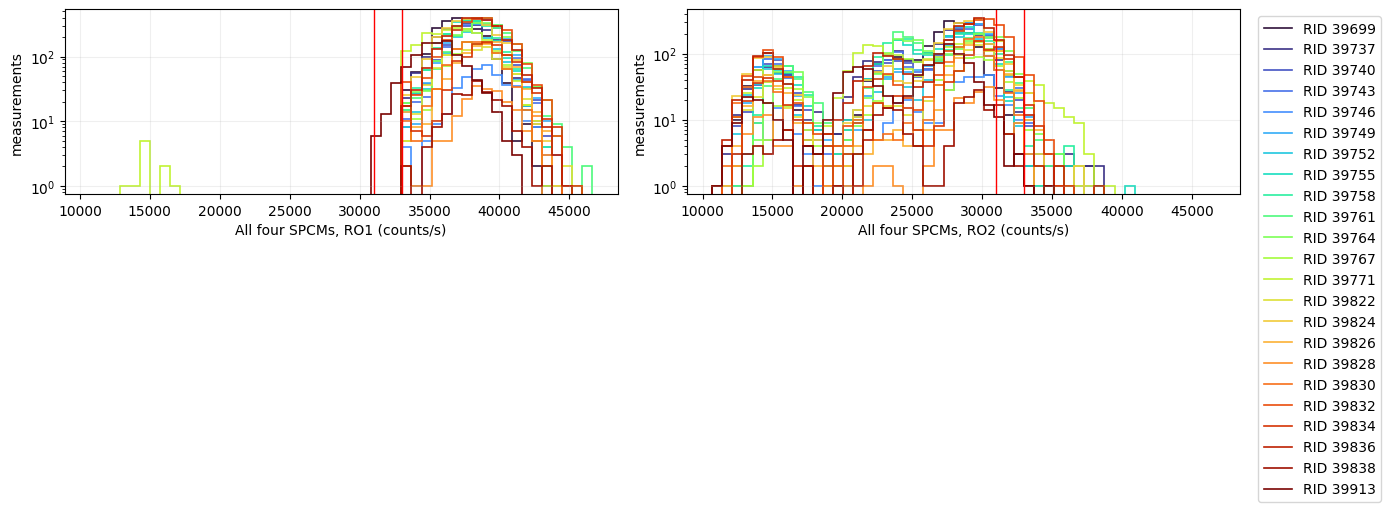

In [86]:
### RO1 and RO2 in counts/s, scan point by scan point (colour: fraction of that
### point's measurements), the selected files one after another (dashed lines
### at the file boundaries). Red: each file's joint
### cut (two_atom_threshold); on the single detectors a quarter of it, a guide
### only -- every detector sees both traps, and nothing in the sequence uses it.
n_hist_bins = 50
### also the RO1 and RO2 histograms of all four SPCMs, one line per file
show_summed_histograms = True
hist_log_y = True


def readout_rates(run, name, shot):
    """counts/s of the whole scan points"""
    t = run['t_SPCM_first_shot'] if shot == 'RO1' else run['t_SPCM_second_shot']
    return run[f'{name}_{shot}'][:run['iterations']*run['n_measurements']]/t


hist_runs = [run for run in general_runs if run['iterations'] > 0]
for run in general_runs:
    if run['iterations'] == 0: print(f"RID {run['rid']}: no whole scan point yet, left out")

if hist_runs:
    def bins_for(names):
        values = np.concatenate([readout_rates(run, name, shot) for run in hist_runs for name in names for shot in ('RO1', 'RO2')])
        return np.linspace(values.min(), values.max(), n_hist_bins+1)

    def per_point_hist(names, bins):
        """{(name, shot): (scan points, bins)}, files one after another, as the
        fraction of each point's measurements, so files with different
        n_measurements share one colour scale"""
        out = {}
        for name in names:
            for shot in ('RO1', 'RO2'):
                out[(name, shot)] = np.concatenate([[np.histogram(readout_rates(run, name, shot)[i*run['n_measurements']:(i+1)*run['n_measurements']], bins=bins)[0]/run['n_measurements']
                                                     for i in range(run['iterations'])] for run in hist_runs])
        return out

    ### where each file starts, and its cut, along the scan-point axis
    starts = np.cumsum([0] + [run['iterations'] for run in hist_runs])

    def draw(ax, image, bins, cut_fraction):
        ax.imshow(image.T, origin='lower', aspect='auto', extent=[0, starts[-1], bins[0], bins[-1]])
        for k, run in enumerate(hist_runs):
            ax.hlines(cut_fraction*run['two_atom_threshold'], starts[k], starts[k+1], color='red')
            if k > 0: ax.axvline(starts[k], color='white', ls='--', lw=1)

    bins_single = bins_for(SPCM_NAMES)
    single = per_point_hist(SPCM_NAMES, bins_single)
    fig, axes = plt.subplots(2, 4, figsize=(14, 5.5), sharex=True, sharey=True)
    for col, name in enumerate(SPCM_NAMES):
        for row, shot in enumerate(('RO1', 'RO2')):
            draw(axes[row, col], single[(name, shot)], bins_single, 0.25)
        axes[0, col].set_title(f'{name} ({DETECTOR_LABELS[name]})')
        axes[1, col].set_xlabel('scan point')
    axes[0, 0].set_ylabel('RO1 (counts/s)')
    axes[1, 0].set_ylabel('RO2 (counts/s)')
    fig.suptitle('Single SPCMs: ' + ', '.join(file_label(run) for run in hist_runs))
    plt.tight_layout()

    bins_all = bins_for(['AllSPCMs'])
    summed = per_point_hist(['AllSPCMs'], bins_all)
    fig, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)
    for ax, shot in zip(axes, ('RO1', 'RO2')):
        draw(ax, summed[('AllSPCMs', shot)], bins_all, 1.0)
        ax.set_ylabel(f'{shot} (counts/s)')
    axes[0].set_title('All four SPCMs')
    axes[1].set_xlabel('scan point (selected files one after another)')
    plt.tight_layout()

    if show_summed_histograms:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4))
        for ax, shot in zip(axes, ('RO1', 'RO2')):
            for k, run in enumerate(general_runs):
                if run['iterations'] == 0: continue
                ax.stairs(np.histogram(readout_rates(run, 'AllSPCMs', shot), bins=bins_all)[0], bins_all, color=file_color(k), lw=1.2, label=file_label(run))
            for rate in sorted({run['two_atom_threshold'] for run in hist_runs}):
                ax.axvline(rate, color='red', lw=1)
            ax.set_xlabel(f'All four SPCMs, {shot} (counts/s)')
            ax.set_ylabel('measurements')
            if hist_log_y: ax.set_yscale('log')
            ax.grid(alpha=0.2)
        axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
        plt.tight_layout()
    plt.show()

### D3. Atom loading time until the first shot passes
The actual time each measurement spent loading: from its first load until a first shot saw both atoms, rejected tries included. The second block averages per scan point (iteration) instead of per measurement: the loader's own time for one load, and this time until the first shot passed.

RID 39699: 2200 measurements, until the first shot passed: median 0.78 s, mean 1.00 s, 90% 2.01 s, max 5.14 s; 1.80 tries (load + first shot) and 1.79 loads per measurement, single load median 0.44 s
RID 39737: 2200 measurements, until the first shot passed: median 0.74 s, mean 1.00 s, 90% 2.03 s, max 6.58 s; 1.99 tries (load + first shot) and 1.98 loads per measurement, single load median 0.38 s
RID 39740: 2200 measurements, until the first shot passed: median 0.79 s, mean 1.09 s, 90% 2.27 s, max 5.96 s; 2.33 tries (load + first shot) and 2.32 loads per measurement, single load median 0.34 s
RID 39743: 2200 measurements, until the first shot passed: median 0.76 s, mean 1.00 s, 90% 2.01 s, max 5.70 s; 1.85 tries (load + first shot) and 1.85 loads per measurement, single load median 0.42 s
RID 39746: 407 measurements, until the first shot passed: median 0.79 s, mean 0.98 s, 90% 1.88 s, max 5.62 s; 1.91 tries (load + first shot) and 1.90 loads per measurement, single load median 0.40 s
R

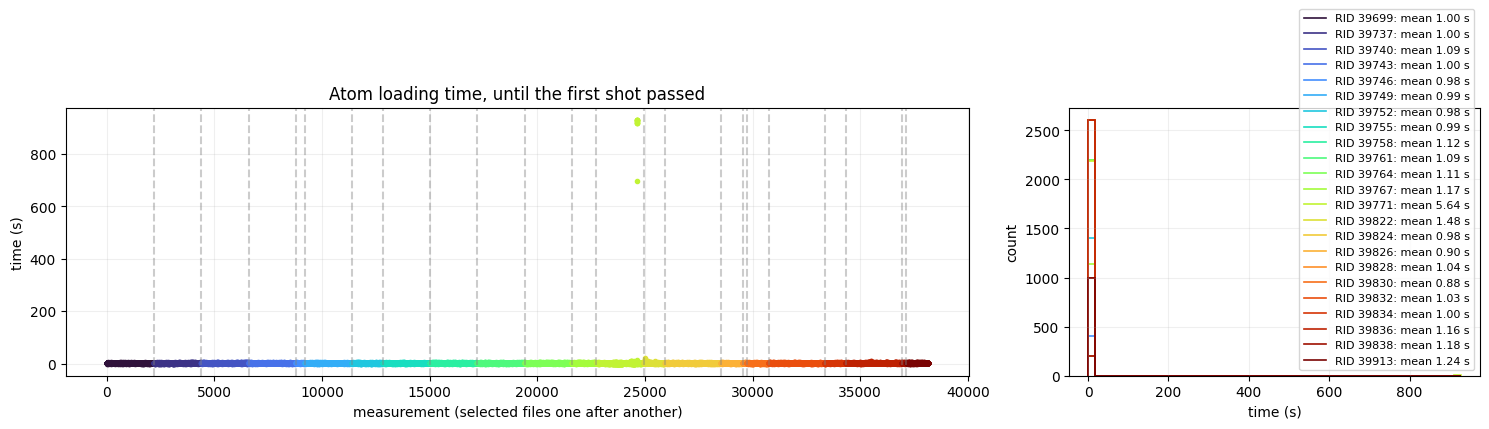

In [91]:
### Atom_loading_time_first_shot_alive: per measurement, the time from the
### start of its first load until its first shot saw both atoms, every rejected
### load + first shot included (confirm-by-first-shot runs, since 2026-10-27
### 20:40). Atom_loading_time is the loader's own time for each single load;
### a 0 there is a load it gave up on.
also_per_load_time = False
n_time_bins = 50

alive_series, per_load_series = [], []
for run in general_runs:
    alive = run['first_shot_alive']
    loads = run['Atom_loading_time'][run['Atom_loading_time'] > 0]
    alive_series.append(alive)
    per_load_series.append(loads)
    if len(alive) == 0:
        print(f"RID {run['rid']}: no Atom_loading_time_first_shot_alive (not a confirm-by-first-shot run, or older than 2026-10-27 20:40)")
    else:
        ### a try reuses the atoms of the previous second shot when that was
        ### bright, without loading, so loads per measurement can be lower
        tries = run['confirm_tries']
        print(f"RID {run['rid']}: {len(alive)} measurements, until the first shot passed: median {np.median(alive):.2f} s, "
              f"mean {np.mean(alive):.2f} s, 90% {np.percentile(alive, 90):.2f} s, max {np.max(alive):.2f} s; "
              f"{np.mean(tries):.2f} tries (load + first shot) and {len(loads)/len(alive):.2f} loads per measurement"
              + (f", single load median {np.median(loads):.2f} s" if len(loads) else ''))

rows = [('until the first shot passed', alive_series)] + ([('single loads (Atom_loading_time)', per_load_series)] if also_per_load_time else [])
fig, axes = plt.subplots(len(rows), 2, figsize=(15, 4*len(rows)), squeeze=False, gridspec_kw={'width_ratios': [2.2, 1]})
for (title, series), (ax_t, ax_h) in zip(rows, axes):
    plot_one_after_another(ax_t, series, fmt='.')
    ax_t.set_xlabel('measurement (selected files one after another)' if series is alive_series else 'load (selected files one after another)')
    ax_t.set_ylabel('time (s)')
    ax_t.set_title(f'Atom loading time, {title}')
    ax_t.grid(alpha=0.2)
    values = [y for y in series if len(y)]
    if values:
        bins = np.linspace(0, np.max(np.concatenate(values)), n_time_bins+1)
        for k, (run, y) in enumerate(zip(general_runs, series)):
            if len(y): ax_h.stairs(np.histogram(y, bins=bins)[0], bins, color=file_color(k), lw=1.2,
                                   label=f"{file_label(run)}: mean {np.mean(y):.2f} s")
        ax_h.legend(fontsize=8)
    ax_h.set_xlabel('time (s)')
    ax_h.set_ylabel('count')
    ax_h.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Atom loading time per scan point: one load (Atom_loading_time)
  RID 39699: 11 points, 3942 loads, mean 0.478 s (median 0.442 s); point means 0.410-0.545 s
  RID 39737: 11 points, 4365 loads, mean 0.423 s (median 0.382 s); point means 0.388-0.465 s
  RID 39740: 11 points, 5106 loads, mean 0.391 s (median 0.342 s); point means 0.318-0.465 s
  RID 39743: 11 points, 4067 loads, mean 0.459 s (median 0.422 s); point means 0.426-0.475 s
  RID 39746: 2 points, 763 loads, mean 0.436 s (median 0.402 s); point means 0.423-0.449 s
  RID 39749: 11 points, 4130 loads, mean 0.447 s (median 0.402 s); point means 0.392-0.511 s
  RID 39752: 7 points, 2635 loads, mean 0.438 s (median 0.402 s); point means 0.429-0.448 s
  RID 39755: 11 points, 3664 loads, mean 0.514 s (median 0.462 s); point means 0.430-0.629 s
  RID 39758: 11 points, 3484 loads, mean 0.627 s (median 0.563 s); point means 0.476-0.725 s
  RID 39761: 11 points, 3451 loads, mean 0.614 s (median 0.543 s); point means 0.479-0.755 s
  RID 3976

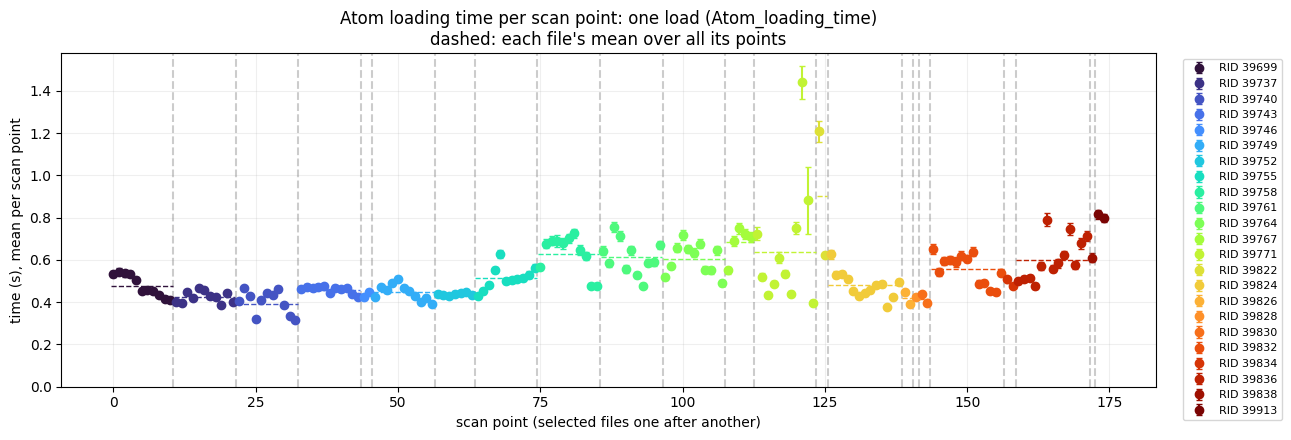

Atom loading time per scan point: until the first shot passed (Atom_loading_time_first_shot_alive)
  RID 39699: 11 points, 2200 measurements, mean 0.999 s (median 0.783 s); point means 0.894-1.169 s
  RID 39737: 11 points, 2200 measurements, mean 0.997 s (median 0.743 s); point means 0.883-1.179 s
  RID 39740: 11 points, 2200 measurements, mean 1.094 s (median 0.789 s); point means 0.914-1.211 s
  RID 39743: 11 points, 2200 measurements, mean 0.996 s (median 0.763 s); point means 0.950-1.052 s
  RID 39746: 2 points, 400 measurements, mean 0.988 s (median 0.787 s); point means 0.969-1.007 s
  RID 39749: 11 points, 2200 measurements, mean 0.992 s (median 0.747 s); point means 0.923-1.125 s
  RID 39752: 7 points, 1400 measurements, mean 0.979 s (median 0.743 s); point means 0.880-1.029 s
  RID 39755: 11 points, 2200 measurements, mean 0.993 s (median 0.783 s); point means 0.872-1.191 s
  RID 39758: 11 points, 2200 measurements, mean 1.123 s (median 0.887 s); point means 0.960-1.261 s
  RI

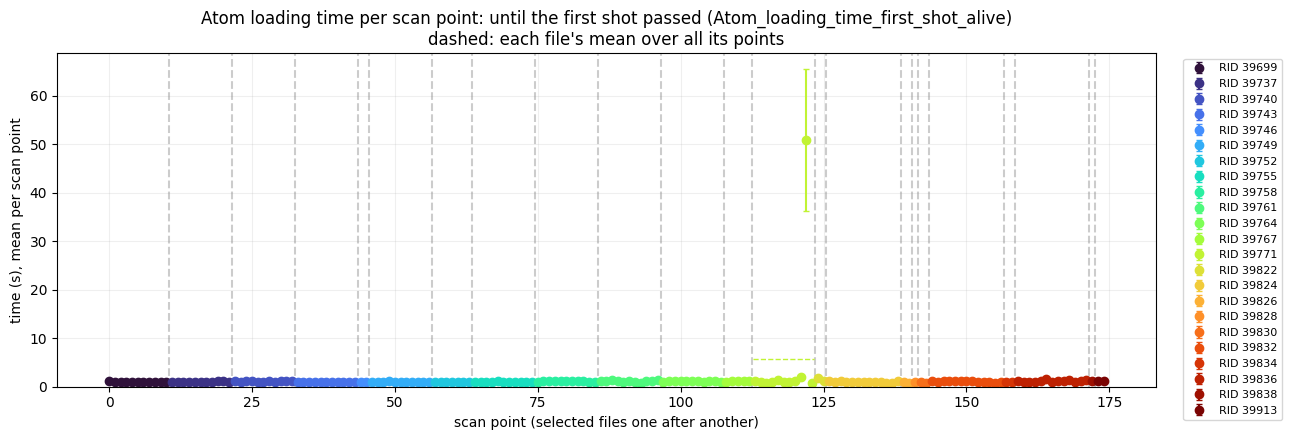

In [92]:
### Per scan point (iteration) rather than per measurement: the mean of each
### point with its standard error, files one after another as in D1, and each
### file's mean over all its points as a dashed line.
###   1. Atom_loading_time: the loader's own MOT time for one load; the 0 of a
###      load it gave up on is left out. Split by point with
###      n_atom_loaded_per_iteration, the loads each point counted.
###   2. Atom_loading_time_first_shot_alive (D3 above): per measurement, from its
###      first load until a first shot saw both atoms, rejected tries included.
show_median = False  ### also mark each point's median (x)
print_per_point = False  ### a table of the points of each file

if any('n_atom_loaded_per_iteration' not in run for run in general_runs): raise RuntimeError('general_runs was loaded before this block existed: run the file-selection cell of D again')


def per_point_statistics(points):
    """mean, standard error and median of each point's values (NaN if empty)"""
    means = np.array([np.mean(v) if len(v) else np.nan for v in points])
    errors = np.array([np.std(v, ddof=1)/np.sqrt(len(v)) if len(v) > 1 else np.nan for v in points])
    medians = np.array([np.median(v) if len(v) else np.nan for v in points])
    return means, errors, medians


load_points, alive_points = [], []
for run in general_runs:
    ### 1. single loads by point. The loads of a point cut short (an aborted
    ### run's last point) come after all counted ones, so they are dropped.
    loads = run['Atom_loading_time'][run['Atom_loading_time'] > 0]
    counts = run['n_atom_loaded_per_iteration'][:run['iterations']]
    edges = np.concatenate([[0], np.cumsum(counts)]).astype(int)
    if len(counts) and edges[-1] <= len(loads):
        load_points.append([loads[edges[i]:edges[i+1]] for i in range(len(counts))])
    else:
        load_points.append([])
        if len(loads):
            print(f"RID {run['rid']}: {len(loads)} loads, but n_atom_loaded_per_iteration counts {edges[-1]} "
                  f"over {len(counts)} points, so the loads cannot be split by point: left out of figure 1")
    ### 2. until the first shot passed: n_measurements per point, whole points only
    n = run['n_measurements']
    alive = run['first_shot_alive']
    alive_points.append([alive[i*n:(i+1)*n] for i in range(min(run['iterations'], len(alive)//n))])
    if len(alive) == 0:
        print(f"RID {run['rid']}: no Atom_loading_time_first_shot_alive, left out of figure 2")

figures = (
    ('Atom loading time per scan point: one load (Atom_loading_time)', load_points, 'loads'),
    ('Atom loading time per scan point: until the first shot passed (Atom_loading_time_first_shot_alive)', alive_points, 'measurements'),
)
for title, points_of_files, what in figures:
    statistics = [per_point_statistics(points) for points in points_of_files]
    fig, ax = plt.subplots(figsize=(13, 4.5))
    starts = plot_one_after_another(ax, [s[0] for s in statistics], [s[1] for s in statistics], fmt='o')
    if show_median:
        plot_one_after_another(ax, [s[2] for s in statistics], fmt='x', labels=False)
    print(title)
    for k, (run, points, start) in enumerate(zip(general_runs, points_of_files, starts)):
        values = [v for v in points if len(v)]
        if not values: continue
        overall = np.concatenate(values)
        means = statistics[k][0]
        ### this file's mean over all its points
        ax.hlines(np.mean(overall), start-0.4, start+len(points)-0.6, color=file_color(k), ls='--', lw=1)
        print(f"  {file_label(run)}: {len(points)} points, {len(overall)} {what}, mean {np.mean(overall):.3f} s "
              f"(median {np.median(overall):.3f} s); point means {np.nanmin(means):.3f}-{np.nanmax(means):.3f} s")
        if print_per_point:
            scan_values = np.ravel(np.outer(run['scan_sequence1'], np.ones(len(run['scan_sequence2']))))
            for i, v in enumerate(points):
                if len(v):
                    print(f"      point {i:2d} ({run['scan_variable1_name']} = {scan_values[i]:g}): {len(v):4d} {what}, "
                          f"mean {np.mean(v):.3f} +- {statistics[k][1][i]:.3f} s, median {np.median(v):.3f} s")
    ax.set_xlabel('scan point (selected files one after another)')
    ax.set_ylabel('time (s), mean per scan point')
    ax.set_title(title + '\ndashed: each file\'s mean over all its points')
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
    if any(len(points) for points in points_of_files): ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()

### D4. FORT monitors, normalised to their set points

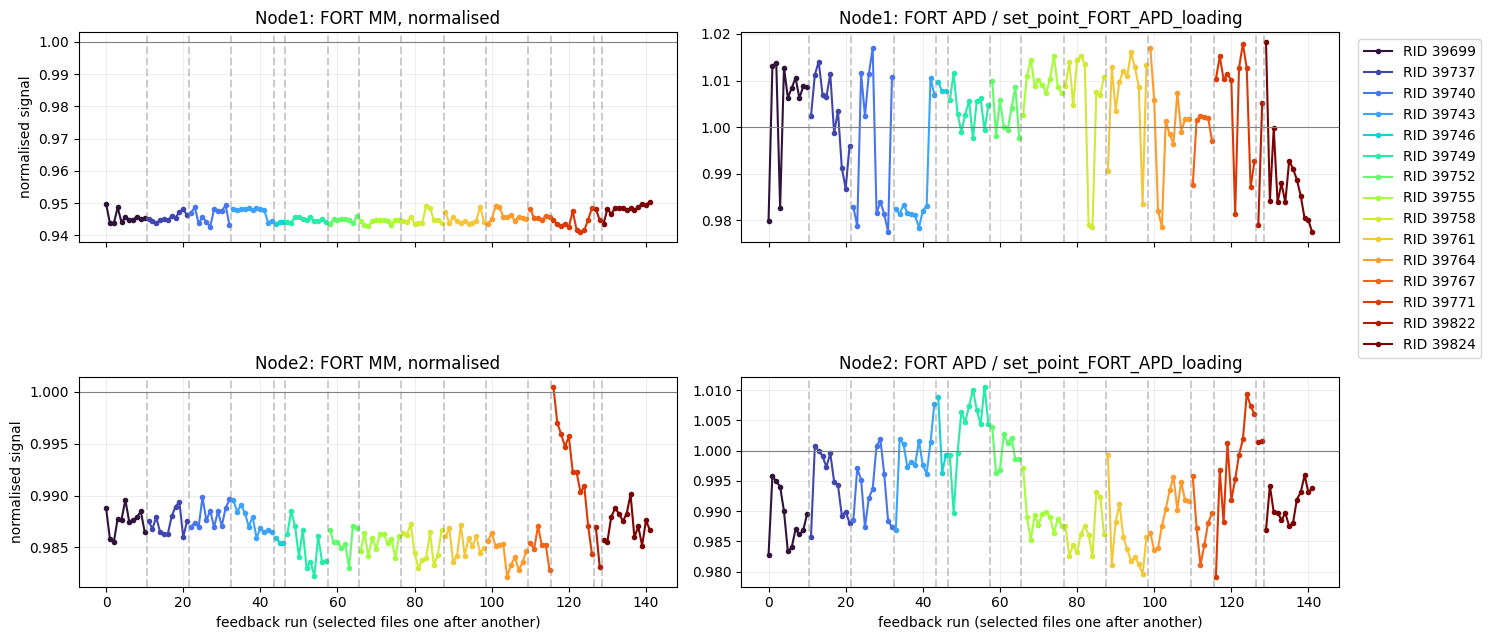

In [56]:
### One entry per feedback run, recorded with the FORT at its loading set point.
### FORT MM is normalised as in 2026_Single_Node_Microwaves:
###     FORT_MM_monitor / best_852_power_ref / (FORT_APD_monitor / set_point_FORT_APD_loading)
### and FORT APD by its loading set point, so both sit at ~1 when all is well.
fig, axes = plt.subplots(2, 2, figsize=(15, 6.5), sharex='col')
for row, node in enumerate(MASTER_SATELLITE_NODES):
    MM_series, APD_series = [], []
    for run in general_runs:
        MM, APD = run[f'FORT_MM_monitor_{node}'], run[f'FORT_APD_monitor_{node}']
        APD_norm = APD/run[f'set_point_FORT_APD_loading_{node}']
        MM_series.append(MM/run[f'best_852_power_ref_{node}']/APD_norm if len(MM) == len(APD) else np.array([]))
        APD_series.append(APD_norm)
        if len(MM) == 0: print(f"RID {run['rid']}: no FORT monitor for {node} (enable_laser_feedback off?)")
    for col, (series, title) in enumerate([(MM_series, 'FORT MM, normalised'), (APD_series, 'FORT APD / set_point_FORT_APD_loading')]):
        ax = axes[row, col]
        plot_one_after_another(ax, series, fmt='.-')
        ax.axhline(1, color='gray', lw=0.8)
        ax.set_title(f'{node}: {title}')
        ax.grid(alpha=0.2)
    axes[row, 0].set_ylabel('normalised signal')
for ax in axes[1]: ax.set_xlabel('feedback run (selected files one after another)')
axes[0, 1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### D5. Excitation cycles per measurement
Each measurement repeats excitation cycles (optical pumping, then n_excitation_attempts excitation attempts) until an atom check, every atom_check_every_n cycles, finds either atom gone, or until max_excitation_cycles. The mean number of cycles per scan point, n_excitation_cycles + 1, therefore shows how long both atoms survive the excitation. In every attempt both FORTs are dark for 50 ns + the shared gate, which is t_photon_collection_time + |D − (G1 − G2)| long (G = gate_start_offset_mu of each node). It is shortest where the two nodes' gates coincide: D = G1 − G2 = −140 now, i.e. D + 144 = +4, not at the photon overlap. If the dark time loses atoms, the mean drops on both sides of that point. The printout gives the dark time of every scan point. The scan points run one after another, so a drift during a run (loading, the cooling laser) also looks like a trend with the delay. Only a drop that follows the dark time and comes back file after file points to it.

RID 39699: atom check every 30 cycles, 5 attempts per cycle, at most 2000 cycles
   i   D+144  FORT dark (ns)  kept    mean cycles  median  ended at 1st check
   0     -40             244   200     61.8 ±  3.5      60              48.5 %
   1     -20             224   200     62.4 ±  3.3      60              45.5 %
   2     -15             219   200     62.9 ±  3.3      60              48.0 %
   3     -10             214   200     61.0 ±  3.2      45              50.0 %
   4      -5             209   200     54.5 ±  2.3      30              54.5 %
   5       0             204   200     48.8 ±  2.4      30              60.0 %
   6       5             201   200     60.3 ±  2.9      60              48.5 %
   7      10             206   200     59.4 ±  3.0      60              48.5 %
   8      15             211   200     53.2 ±  2.3      30              57.0 %
   9      20             216   200     52.4 ±  2.8      30              60.5 %
  10      40             236   200     52.2 ±  2.3 

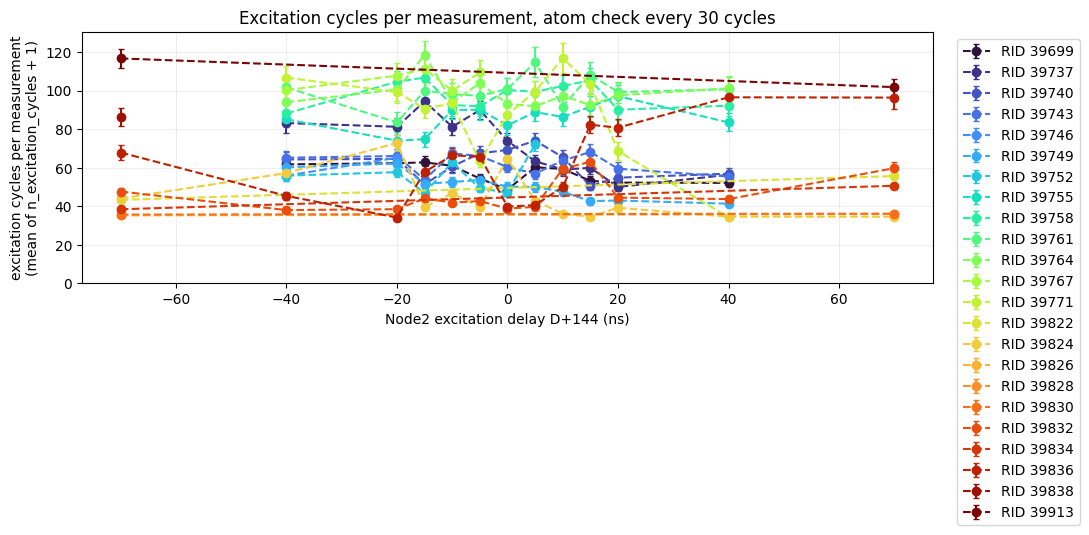

In [88]:
### Per scan point, the mean number of excitation cycles a measurement ran,
### n_excitation_cycles + 1 (the loop index at exit, plus one), with its
### standard error.
### True: against D + x_offset_ns, every file on one axis.
### False: scan point by scan point, the selected files one after another, as D1.
against_delay = True
### delays are labelled D + x_offset_ns, as in B and C
x_offset_ns = 144
### Leave out the measurements whose load gave up (max_loading_rounds tries
### without a bright first shot, counted as in D1; e.g. 39771 while the
### cooling laser was unlocked): without both atoms they end at the first
### atom check, whatever the delay.
skip_given_up_loads = True

if any('hom' not in run for run in general_runs): raise RuntimeError('general_runs was loaded before D5 and D6 existed: run the file-selection cell of D again')

x_name = 'D' if x_offset_ns == 0 else f'D{x_offset_ns:+g}'
cycle_means, cycle_errors, cycle_x = [], [], []
for run in general_runs:
    hom, n = run['hom'], run['n_measurements']
    ### whole scan points in both the D loader's series and load_hom_run
    iterations = min(hom['iterations'], len(run['n_excitation_cycles'])//n) if hom is not None else 0
    if iterations == 0:
        print(f"RID {run['rid']}: no whole HOM scan point, left out")
        for series in (cycle_means, cycle_errors, cycle_x): series.append(np.array([]))
        continue

    cycles = (run['n_excitation_cycles'][:iterations*n]+1).reshape(iterations, n)
    keep = np.ones(cycles.shape, dtype=bool)
    note = ''
    ### first shots at or below the joint cut the confirm loop compares against
    cut = run['two_atom_threshold']*run['t_SPCM_first_shot'] if run['t_SPCM_first_shot'] is not None else np.nan
    dark_first_shot = run['AllSPCMs_RO1'][:iterations*n] <= cut if len(run['AllSPCMs_RO1']) >= iterations*n else None
    if dark_first_shot is not None and run['max_loading_rounds'] is not None and len(run['confirm_tries']) >= iterations*n:
        given_up = (run['confirm_tries'][:iterations*n] == run['max_loading_rounds']) & dark_first_shot
        if skip_given_up_loads: keep = ~given_up.reshape(iterations, n)
        if np.any(given_up): note = f"; {np.count_nonzero(given_up)} given-up loads " + ('left out' if skip_given_up_loads else 'kept')
    elif dark_first_shot is not None and np.any(dark_first_shot):
        ### no confirm-by-first-shot loop: a measurement may start without both atoms
        note = f"; no confirm loop, {np.count_nonzero(dark_first_shot)} of {iterations*n} first shots at or below the joint cut (kept)"
    kept = [cycles[i][keep[i]] for i in range(iterations)]
    means = np.array([np.mean(c) if len(c) else np.nan for c in kept])
    errors = np.array([np.std(c, ddof=1)/np.sqrt(len(c)) if len(c) > 1 else np.nan for c in kept])
    delays = np.asarray(hom['delay_iAll'][:iterations], dtype=float)
    ### both FORTs are dark for 50 ns + the shared gate in every attempt
    dark = np.array([50+gate[1]-gate[0] for gate in hom['gate_iAll'][:iterations]])
    cycle_means.append(means)
    cycle_errors.append(errors)
    cycle_x.append(delays+x_offset_ns)

    K = run['atom_check_every_n']
    print(f"{file_label(run)}: atom check every {K} cycles, {run['n_excitation_attempts']} attempts per cycle, "
          f"at most {run['max_excitation_cycles']} cycles{note}")
    print(f"{'i':>4} {x_name:>7} {'FORT dark (ns)':>15} {'kept':>5} {'mean cycles':>14} {'median':>7} {'ended at 1st check':>19}")
    for i in range(iterations):
        first_check = 100*np.mean(kept[i] == K) if K and len(kept[i]) else np.nan
        median = np.median(kept[i]) if len(kept[i]) else np.nan
        print(f"{i:4d} {delays[i]+x_offset_ns:7.0f} {dark[i]:15.0f} {len(kept[i]):5d} {means[i]:8.1f} ± {errors[i]:4.1f} {median:7.0f} {first_check:17.1f} %")
    if against_delay and len(set(delays)) < iterations:
        print(f"    (several points at one delay: they overlap in the plot; against_delay = False shows them one by one)")
    print()

fig, ax = plt.subplots(figsize=(11, 4.5))
if against_delay:
    for k, run in enumerate(general_runs):
        if len(cycle_x[k]) == 0: continue
        ax.errorbar(cycle_x[k], cycle_means[k], yerr=cycle_errors[k], fmt='o--', color=file_color(k), capsize=2, label=file_label(run))
    ax.set_xlabel(f'Node2 excitation delay {x_name} (ns)')
else:
    plot_one_after_another(ax, cycle_means, cycle_errors, fmt='o-')
    ax.set_xlabel('scan point (selected files one after another)')
checks = sorted({run['atom_check_every_n'] for run in general_runs if run['atom_check_every_n']})
ax.set_title('Excitation cycles per measurement' + (f', atom check every {checks[0]} cycles' if len(checks) == 1 else ''))
ax.set_ylabel('excitation cycles per measurement\n(mean of n_excitation_cycles + 1)')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
if any(len(x) for x in cycle_x): ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### D6. Photon arrival, scan point by scan point
The first click of each of the four SPCMs in every attempt, in ns after t1: one panel per scan point and one figure per selected file, as "Accumulated All SPCMs photons" in two_photon_analysis_20260626. Node1's photons keep their place after t1 and Node2's move with D, so the two peaks merge at D + 144 = 0 and separate towards both ends of the scan. `grid_per_cycle` (on) gives clicks per ns per 10⁶ excitation cycles, as in C; off gives clicks per bin, as in June.

RID 39699: 11 scan points, 8218 clicks


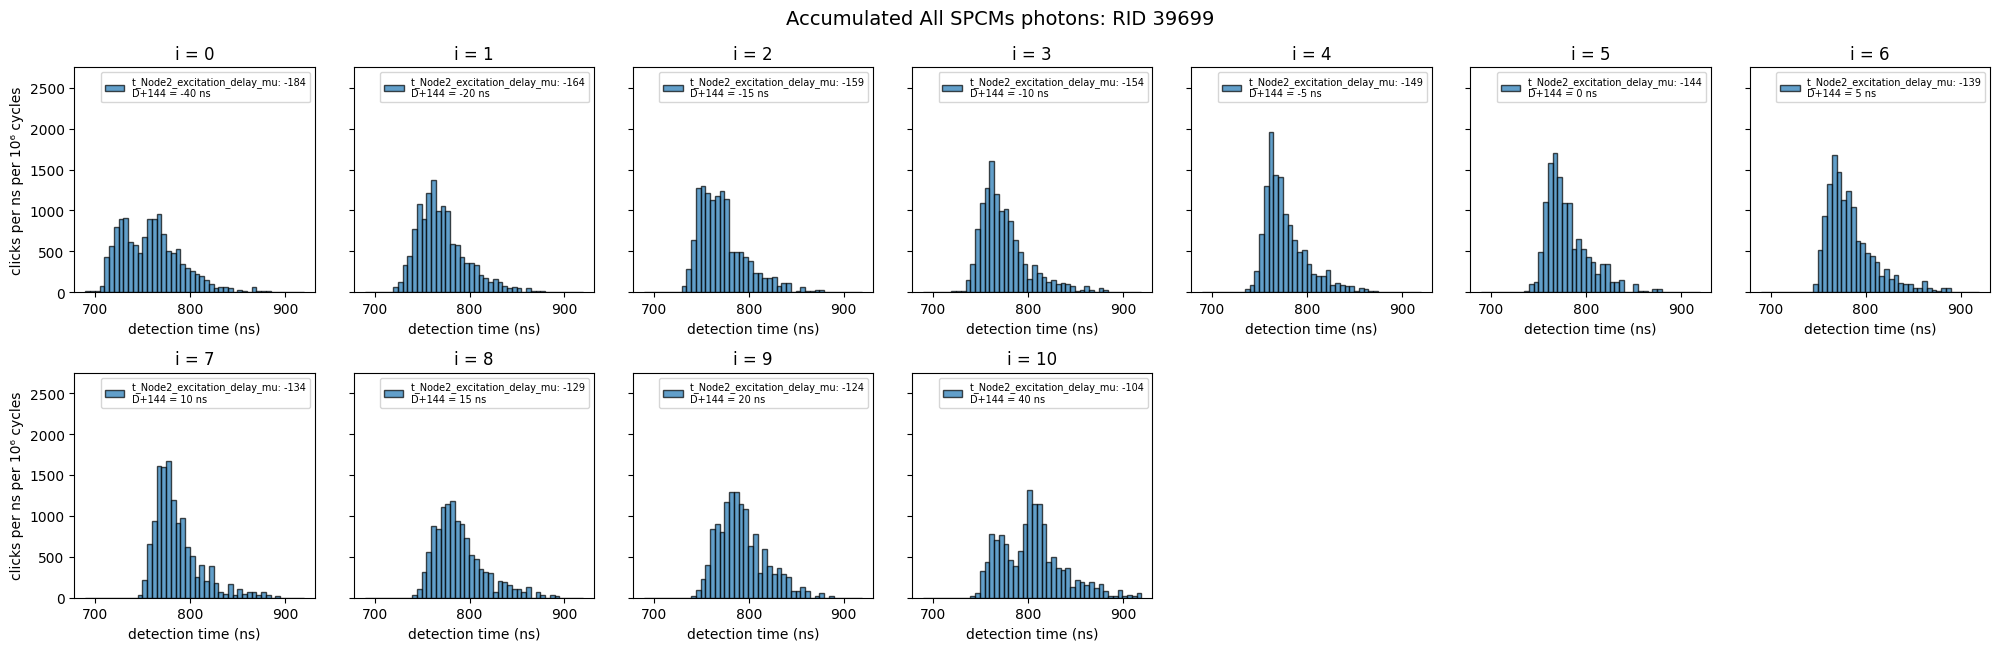

RID 39737: 11 scan points, 8374 clicks


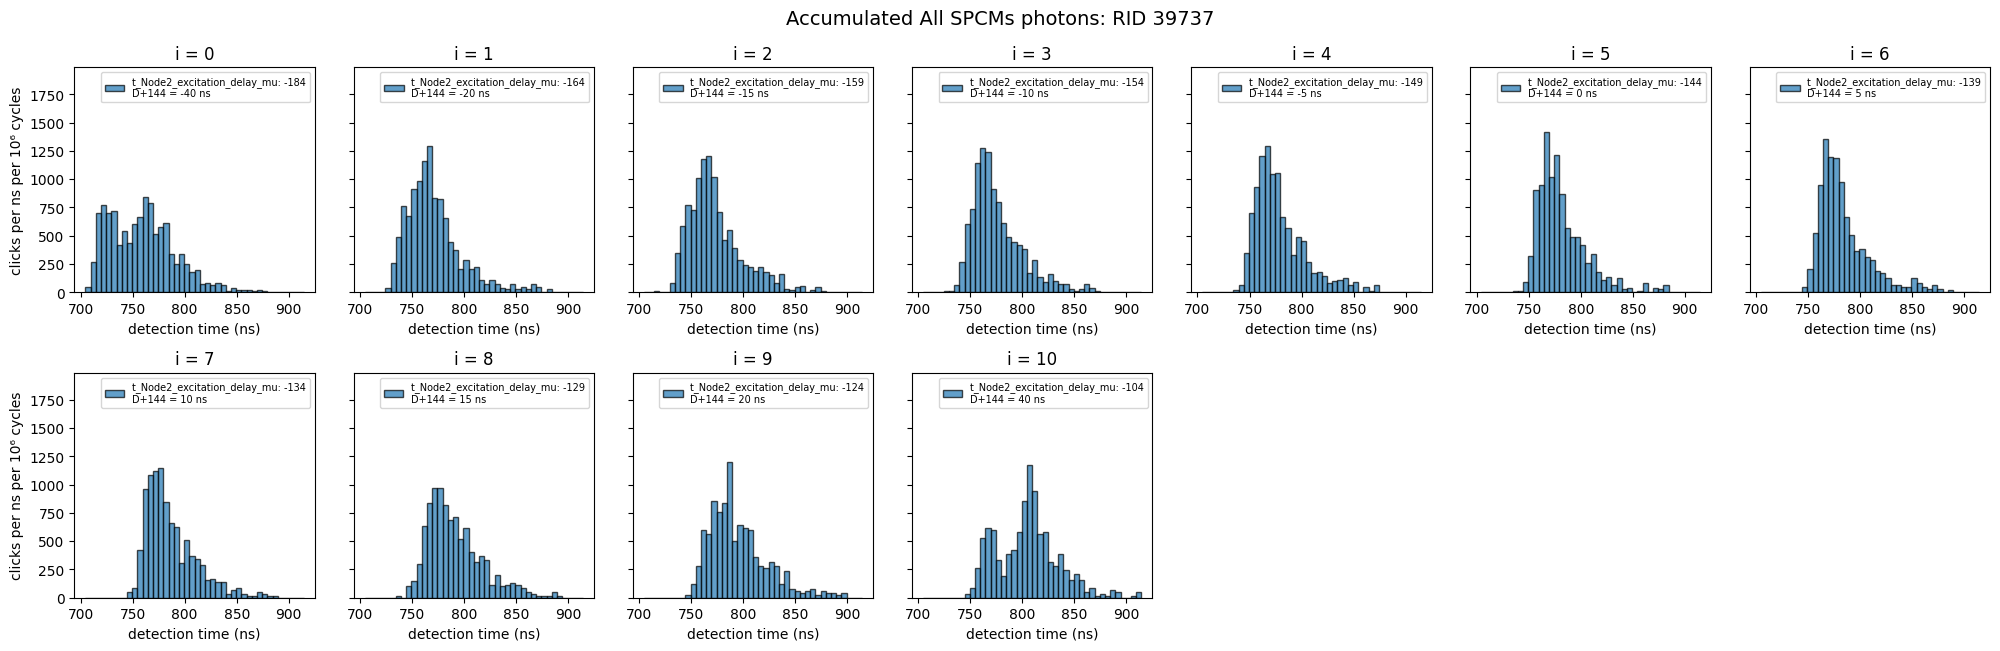

RID 39740: 11 scan points, 7123 clicks


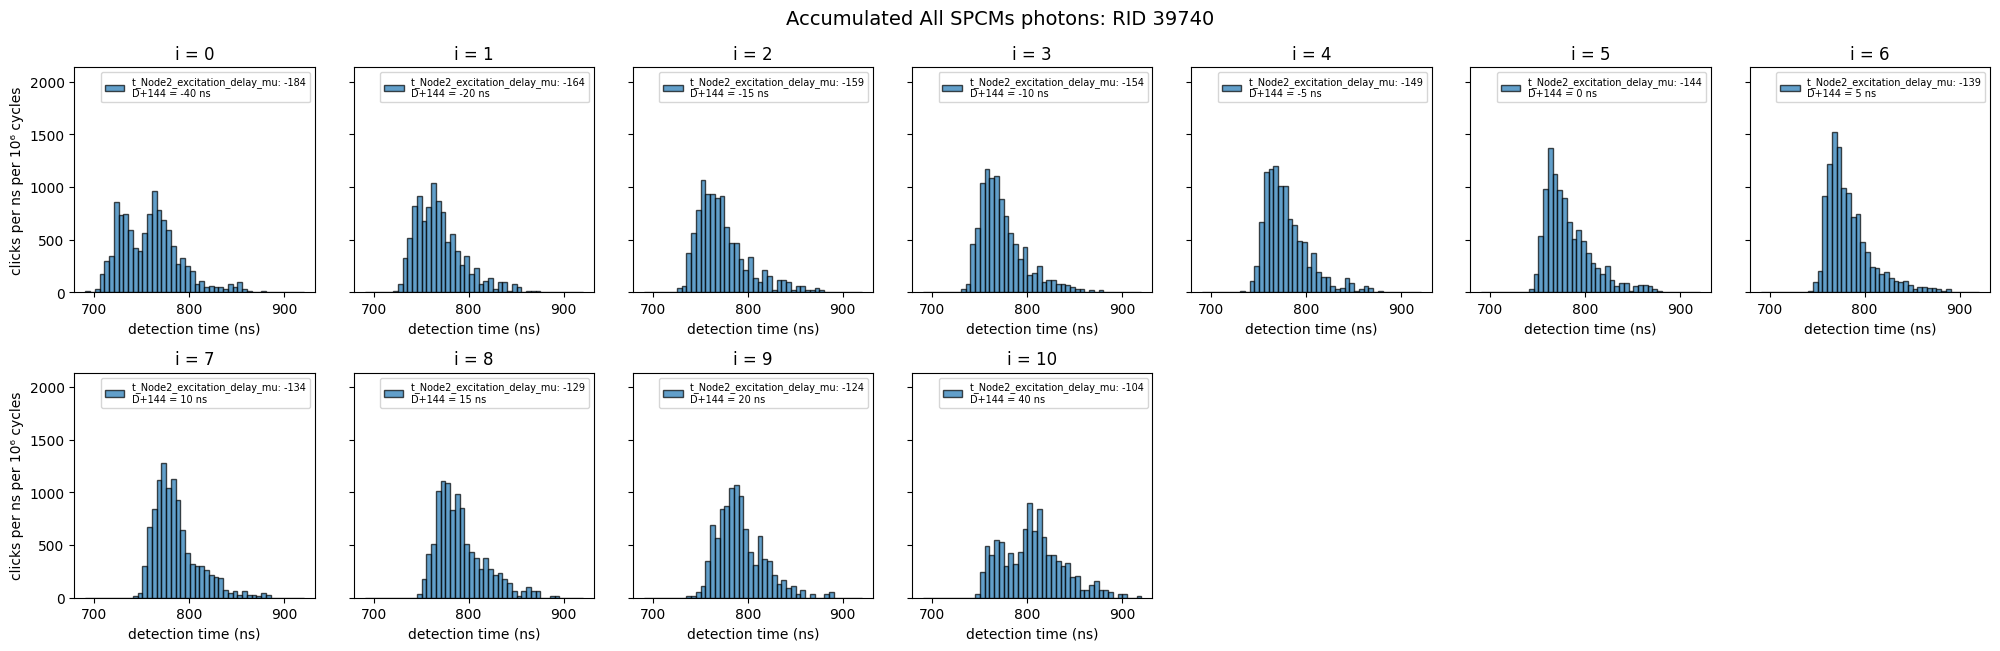

RID 39743: 11 scan points, 7159 clicks


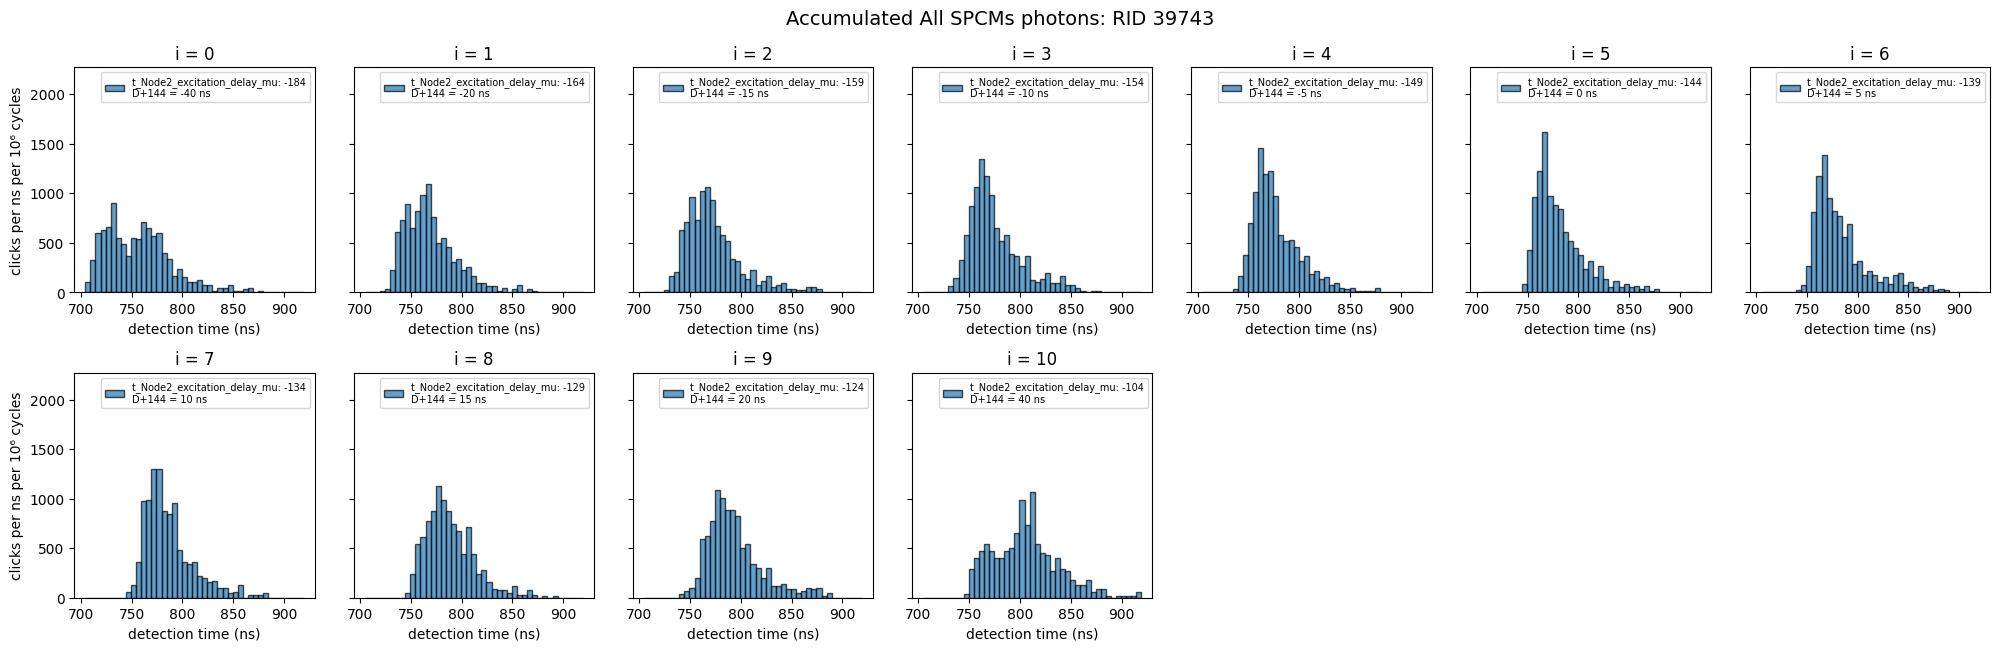

RID 39746: 2 scan points, 1234 clicks


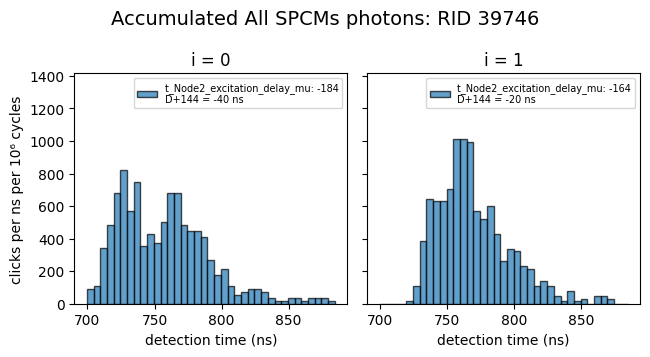

RID 39749: 11 scan points, 5346 clicks


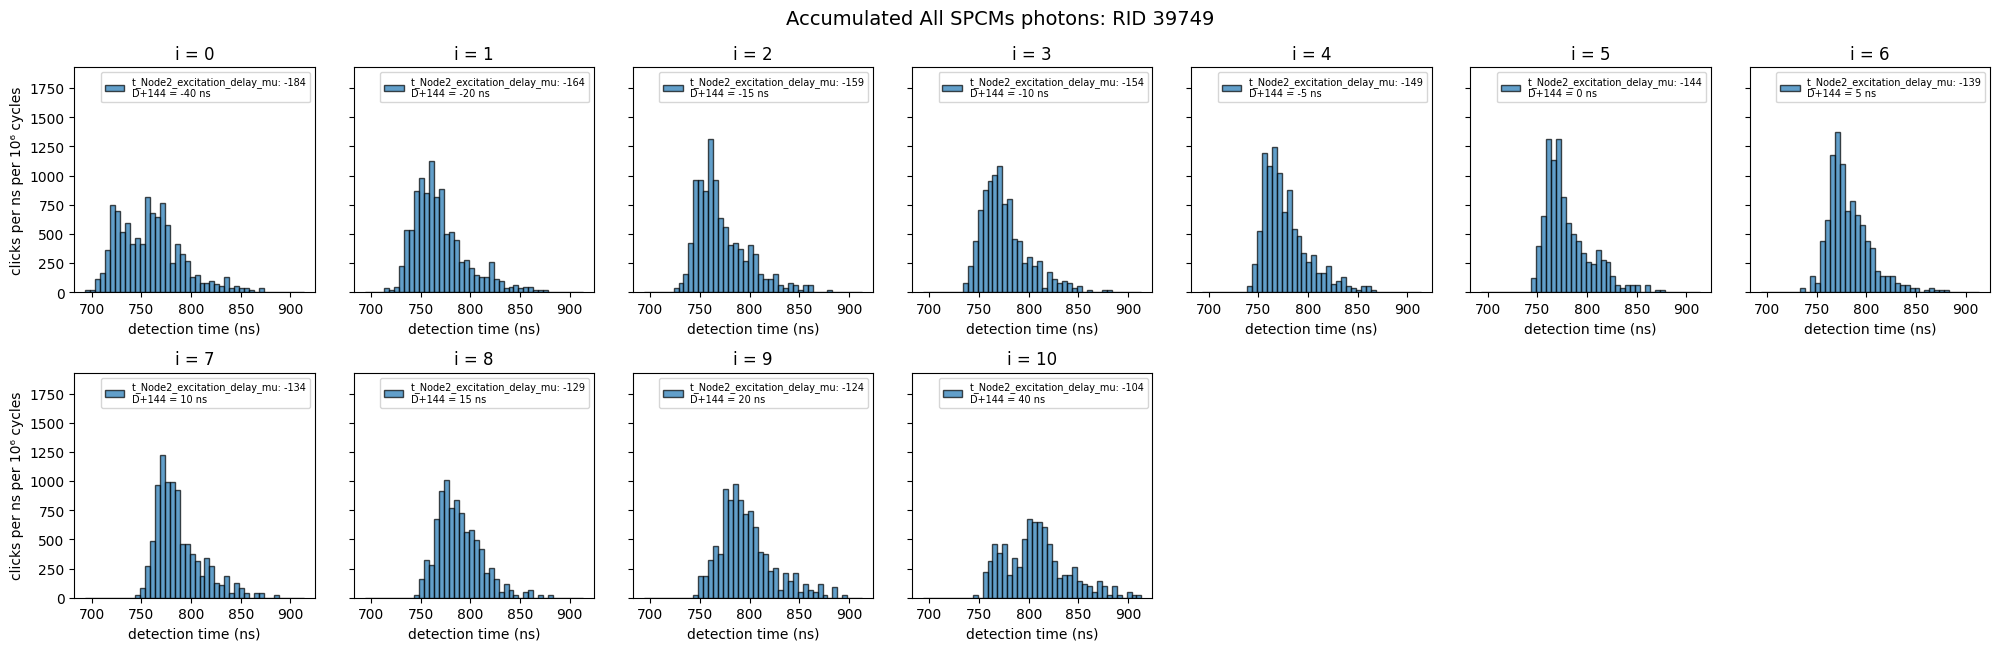

RID 39752: 7 scan points, 3986 clicks


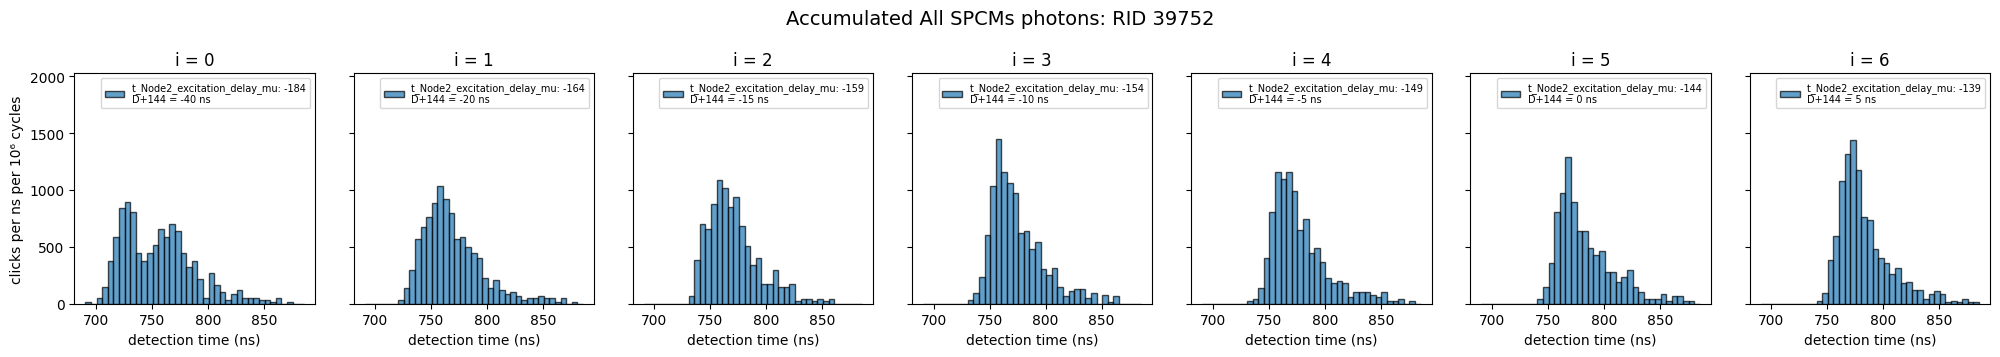

RID 39755: 11 scan points, 10630 clicks


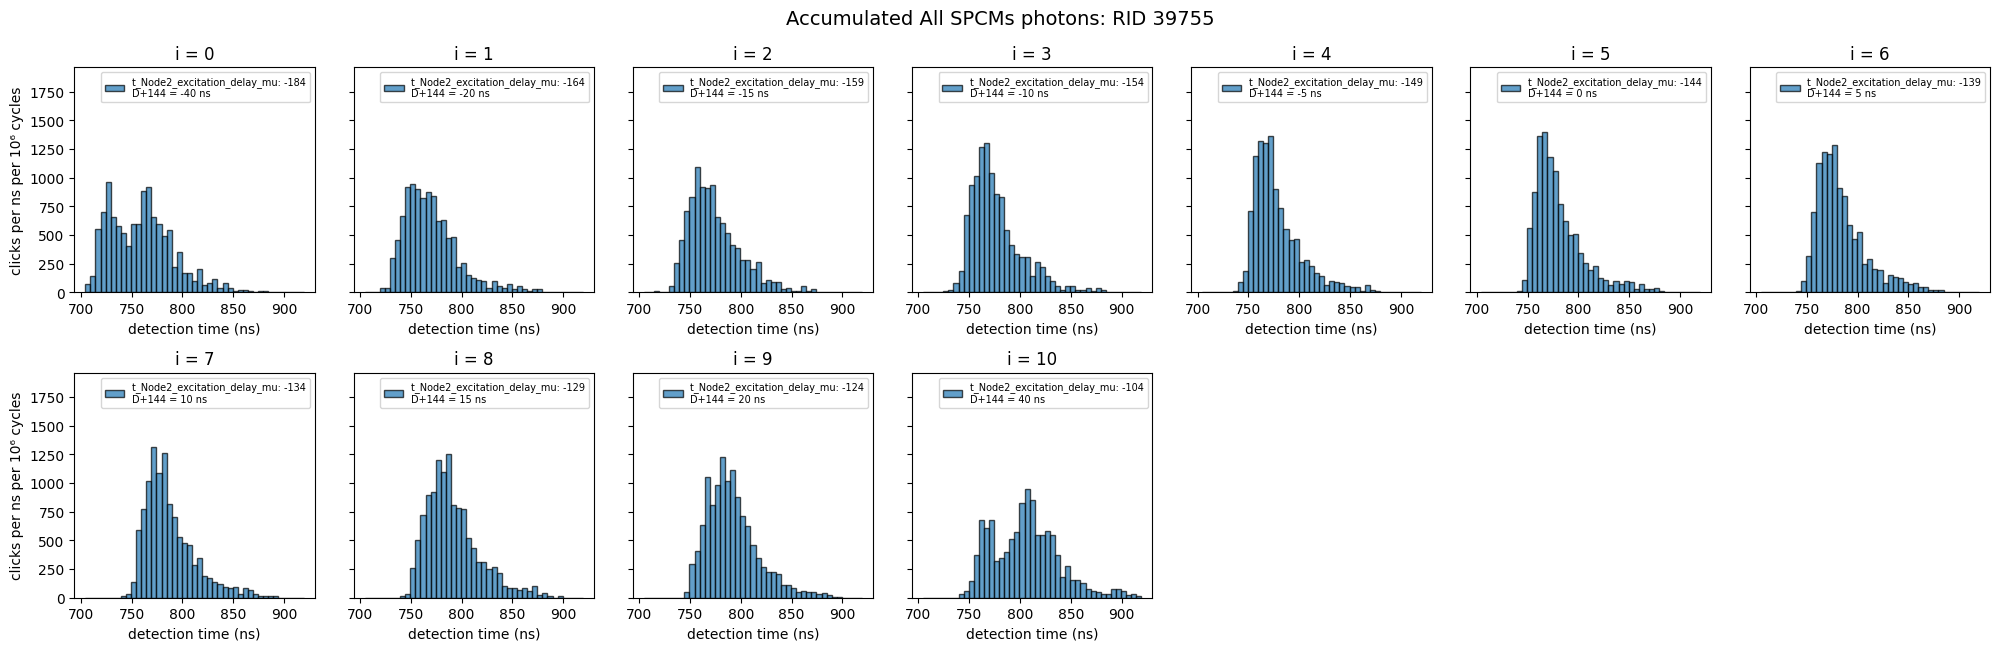

RID 39758: 11 scan points, 12138 clicks


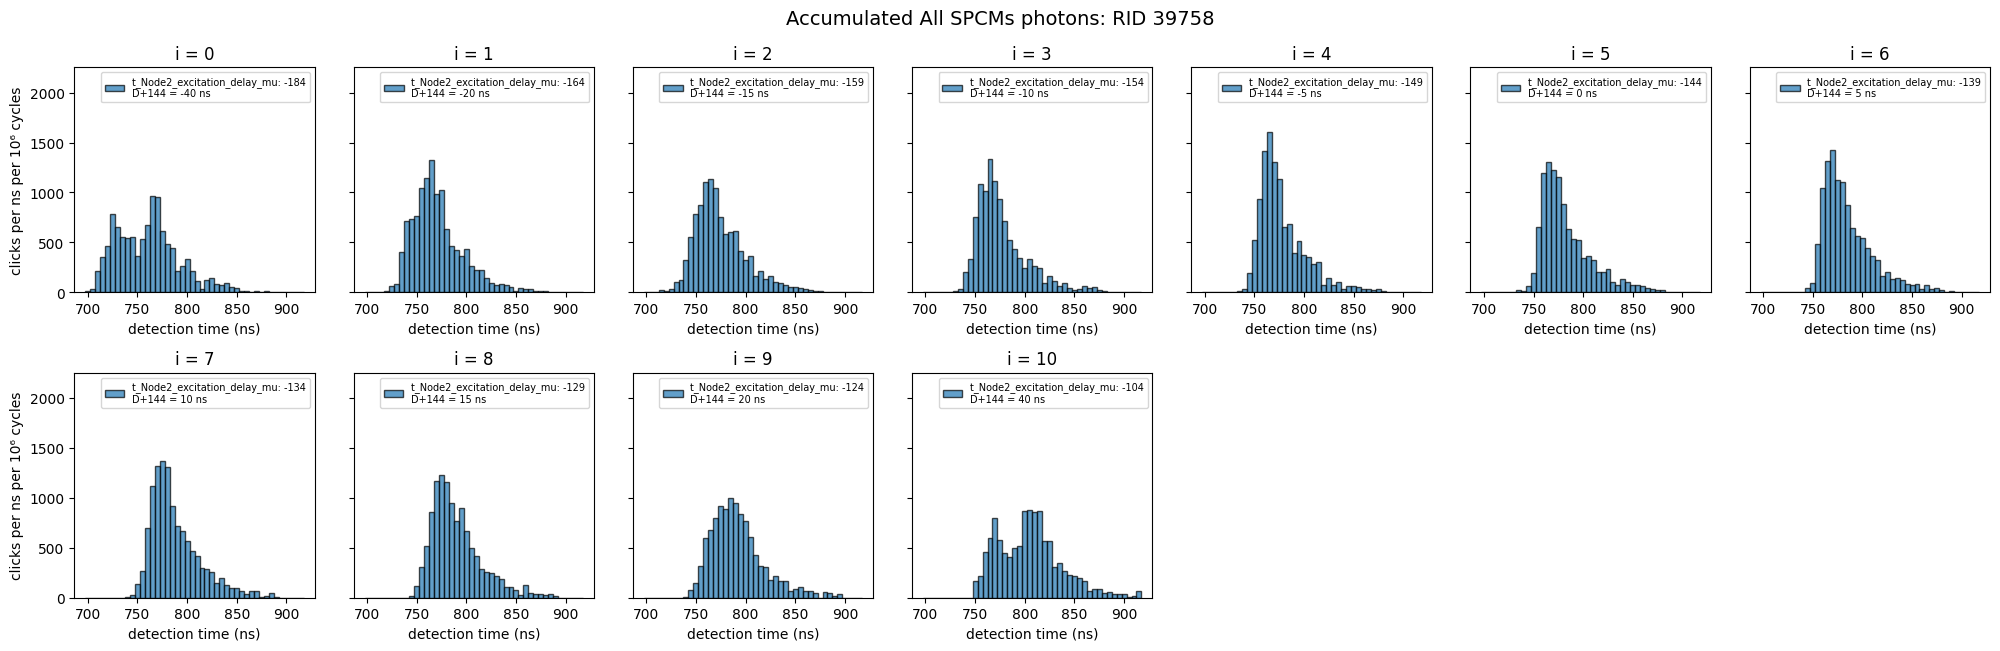

RID 39761: 11 scan points, 12654 clicks


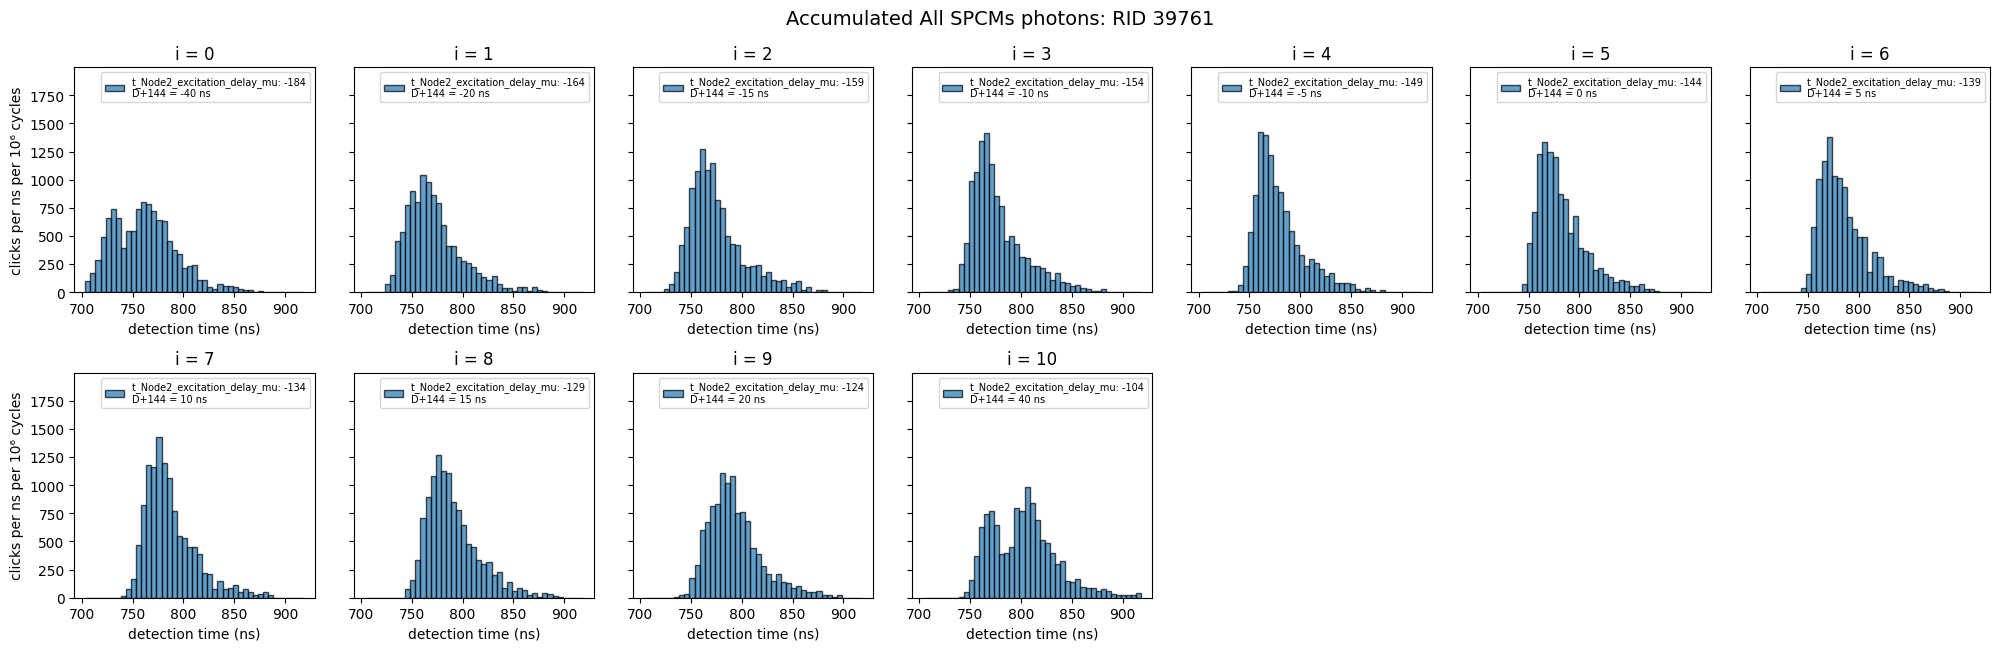

RID 39764: 11 scan points, 12378 clicks


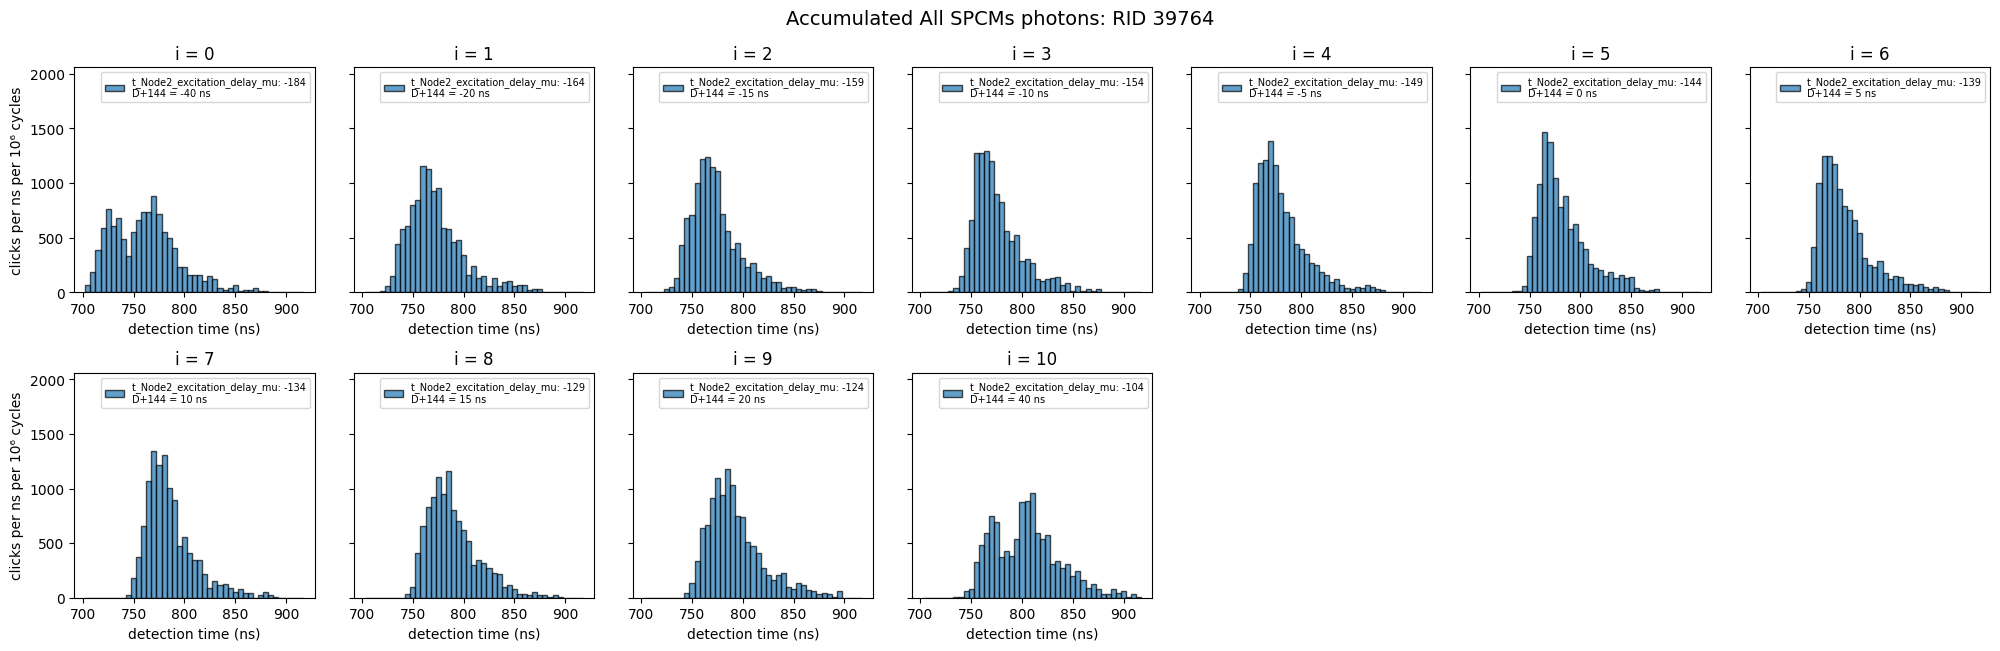

RID 39767: 5 scan points, 6178 clicks


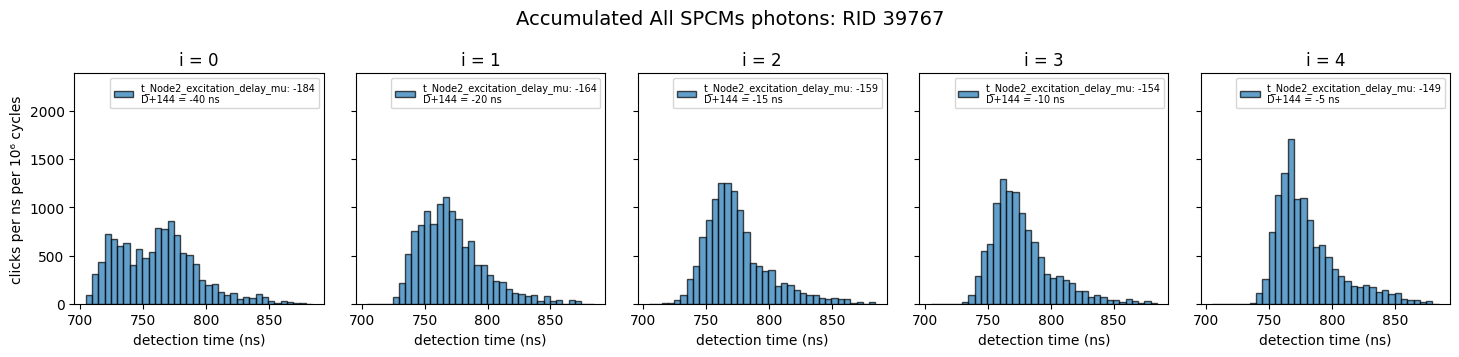

RID 39771: 11 scan points, 11029 clicks


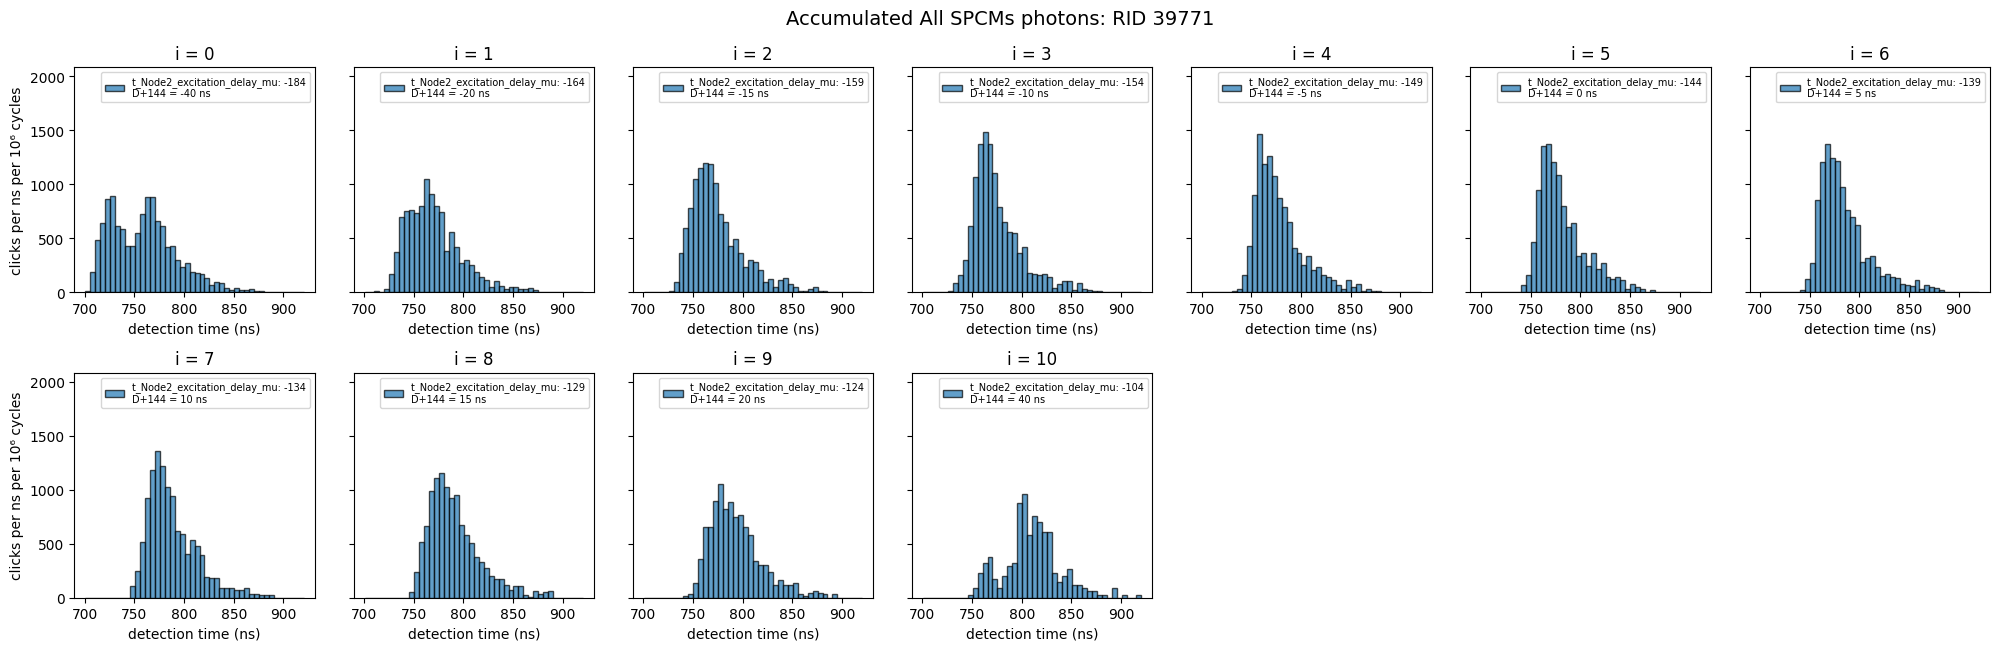

RID 39822: 2 scan points, 2331 clicks


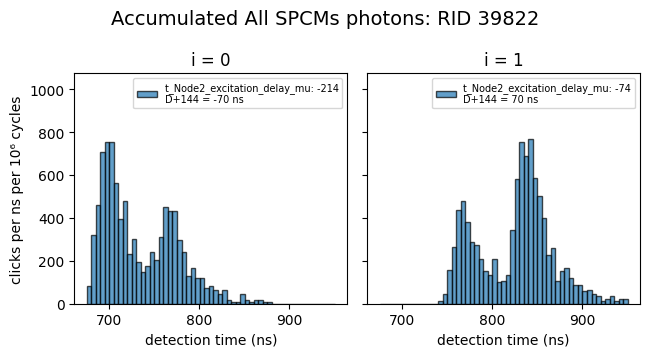

RID 39824: 13 scan points, 5490 clicks


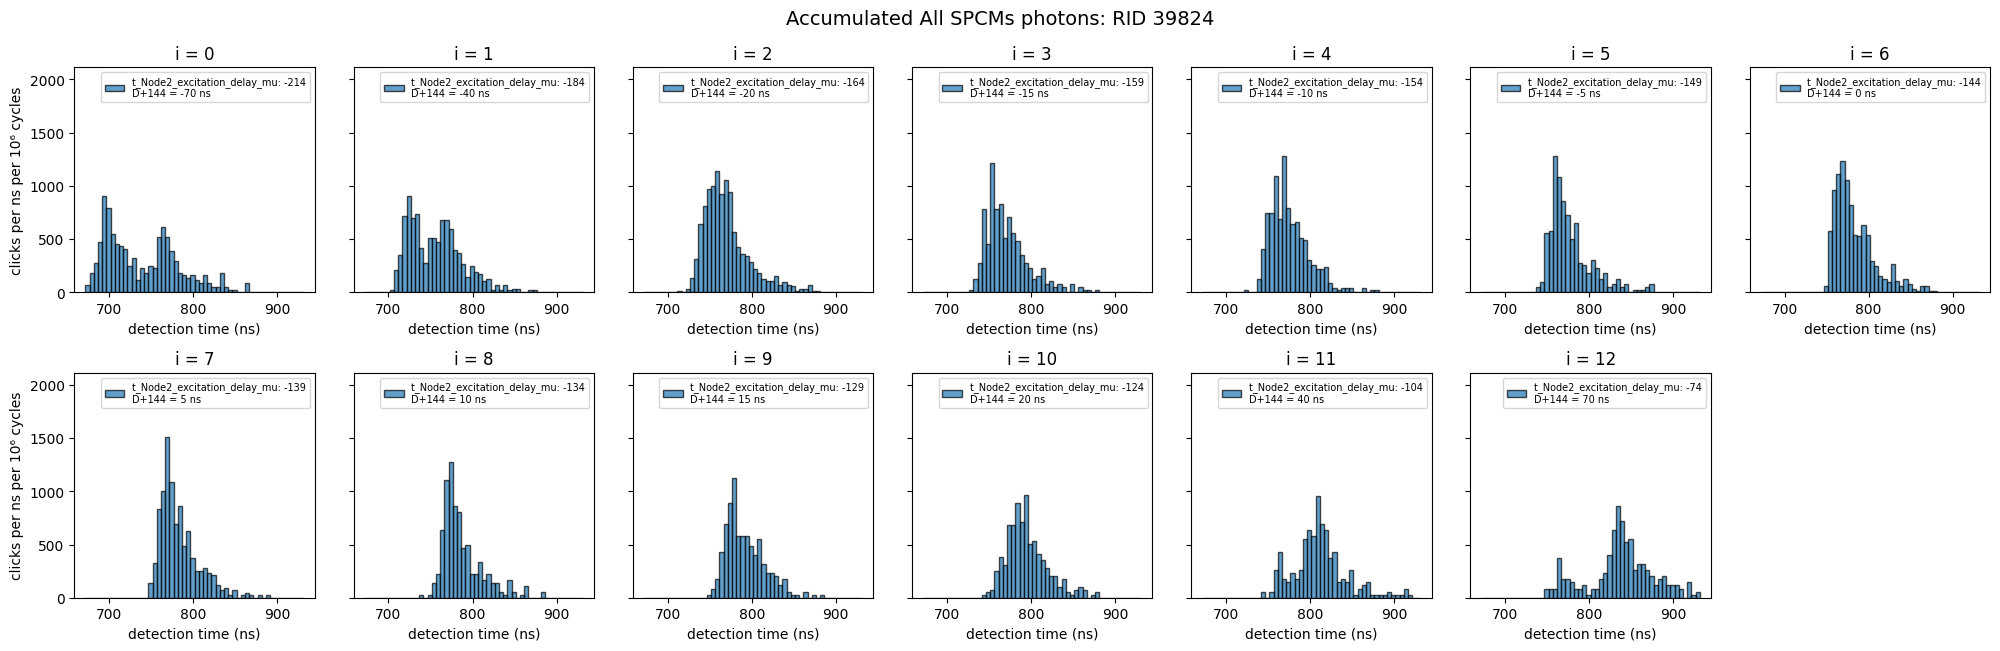

RID 39826: 2 scan points, 1433 clicks


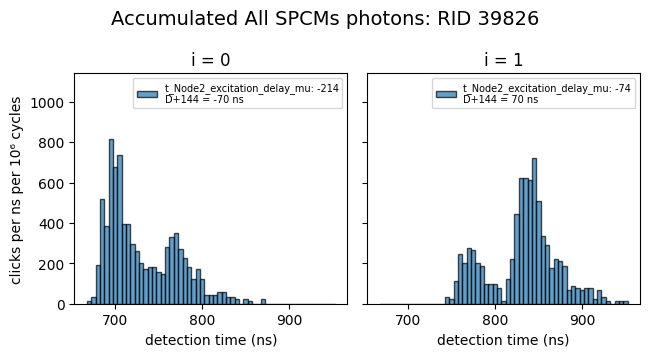

RID 39828: 1 scan points, 342 clicks


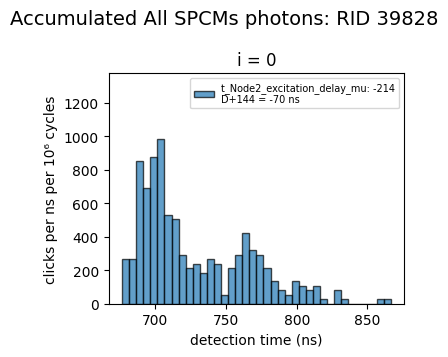

RID 39830: 2 scan points, 1505 clicks


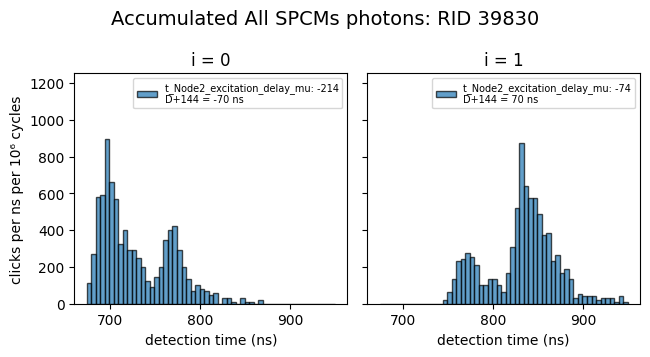

RID 39832: 13 scan points, 5555 clicks


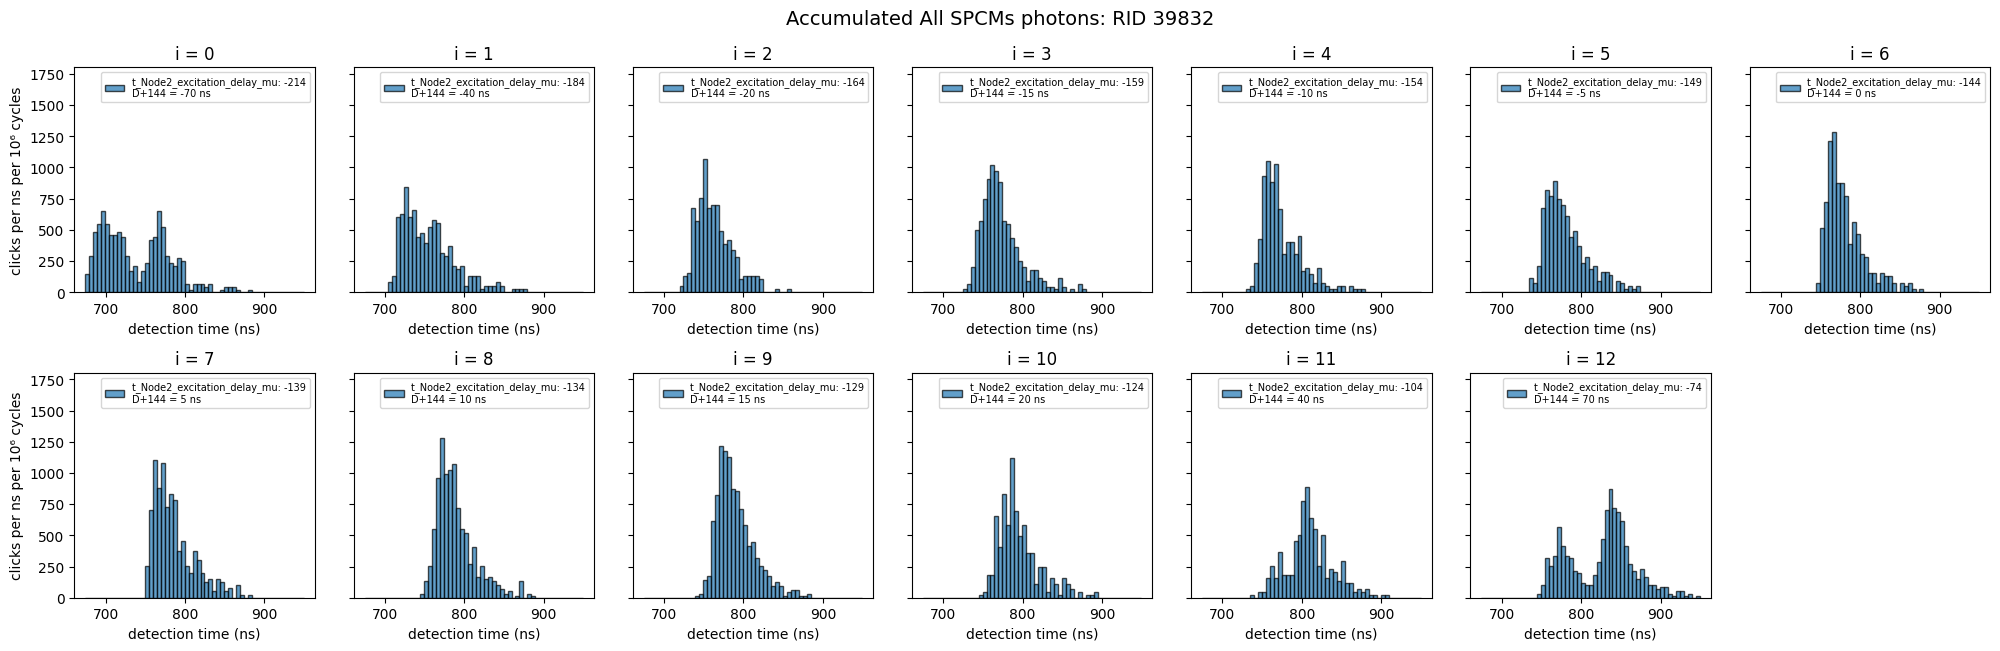

RID 39834: 2 scan points, 2103 clicks


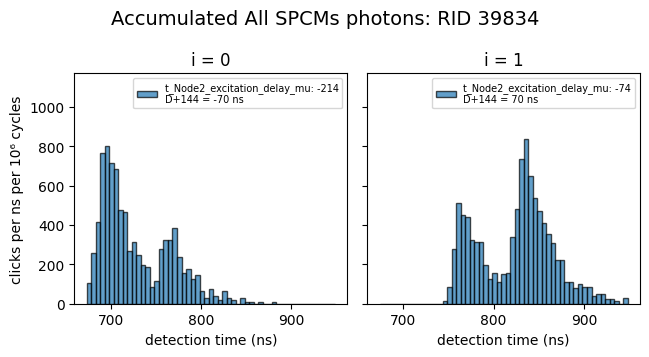

RID 39836: 13 scan points, 8692 clicks


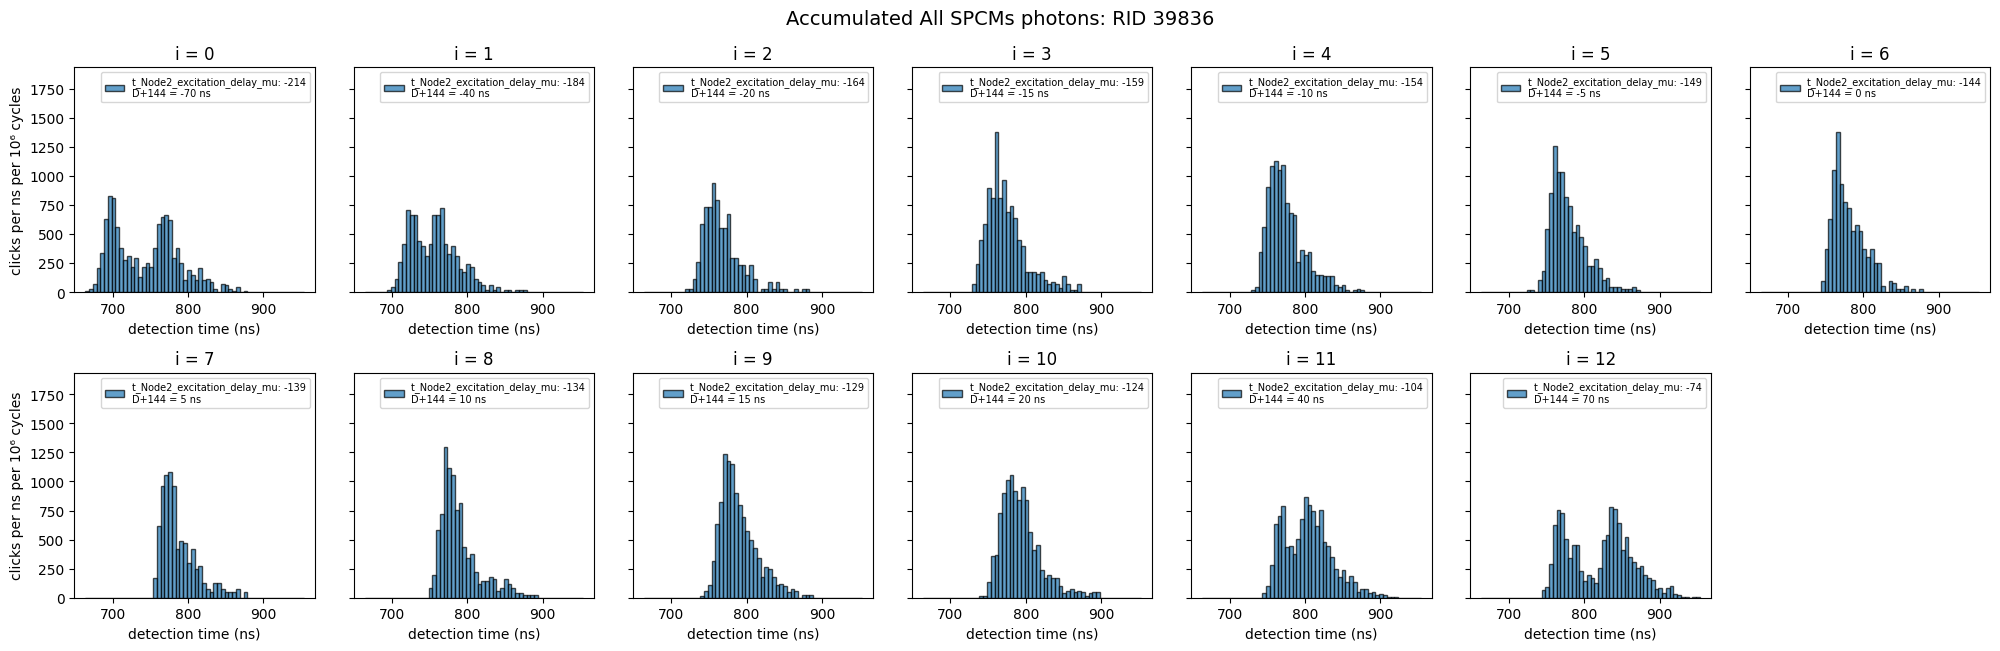

RID 39838: 1 scan points, 951 clicks


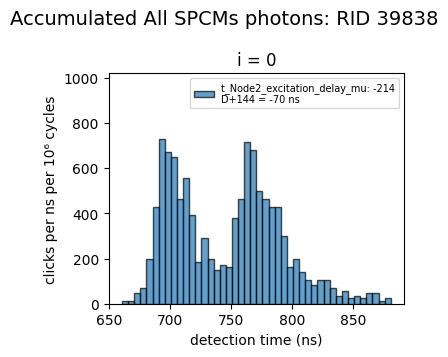

RID 39913: 2 scan points, 6488 clicks


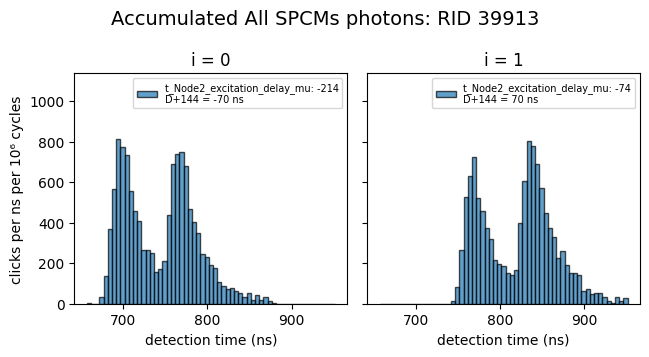

In [ ]:
### The first click of each of the four SPCMs in every attempt, in ns after
### t1: one panel per scan point, one figure per selected file, as
### "Accumulated All SPCMs photons" in two_photon_analysis_20260626. Every
### scan point is used, whichever nodes were excited, as in C.
grid_bin_ns = 5  ### whole ns
grid_columns = 7
### True: clicks per ns per 10⁶ excitation cycles, as in C, so a point with
### fewer cycles is not simply lower; False: clicks per bin, as in June
grid_per_cycle = True
### delays are labelled D + x_offset_ns, as in B and C
x_offset_ns = 144

if any('hom' not in run for run in general_runs): raise RuntimeError('general_runs was loaded before D5 and D6 existed: run the file-selection cell of D again')

x_name = 'D' if x_offset_ns == 0 else f'D{x_offset_ns:+g}'
excited_suffix = {(True, True): '', (True, False): ', Node1 only', (False, True): ', Node2 only', (False, False): ', neither excited'}
for run in general_runs:
    hom = run['hom']
    if hom is None:
        print(f"RID {run['rid']}: no HOM data, left out")
        continue
    scan_values = np.ravel(np.asarray(hom['scan_sequence1'], dtype=float))
    panels = []
    for i in range(hom['iterations']):
        excited = excited_suffix[tuple(bool(e) for e in hom['excited_iAll'][i])]
        label = f"{hom['scan_variable1_name']}: {scan_values[i]:g}\n{x_name} = {hom['delay_iAll'][i]+x_offset_ns:g} ns{excited}"
        panels.append((i, label, arrival_times(hom, [i])[0], int(hom['attempts_iAll'][i])//int(hom['n_excitation_attempts'])))
    clicks_all = np.concatenate([clicks for _, _, clicks, _ in panels])
    print(f"{file_label(run)}: {len(panels)} scan points, {len(clicks_all)} clicks")
    if len(clicks_all) == 0: continue

    edges = np.arange(np.floor(clicks_all.min())-0.5, clicks_all.max()+grid_bin_ns, grid_bin_ns)
    n_cols = min(grid_columns, len(panels))
    n_rows = int(np.ceil(len(panels)/n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(2.7*n_cols+1.2, 3*n_rows+0.6), sharex=True, sharey=True, squeeze=False)
    axs = axs.ravel()
    tallest = 0
    for ax, (i, label, clicks, cycles) in zip(axs, panels):
        weights = np.full(len(clicks), 1e6/grid_bin_ns/max(cycles, 1)) if grid_per_cycle else None
        heights = ax.hist(clicks, bins=edges, weights=weights, edgecolor='black', alpha=0.7, label=label)[0]
        tallest = max(tallest, np.max(heights))
        ax.set_title(f'i = {i}')
        ax.set_xlabel('detection time (ns)')
        ax.tick_params(axis='x', labelbottom=True)
        ax.legend(fontsize=7, loc='upper right')
    ### room for the legends above the tallest bar (the y axis is shared)
    axs[0].set_ylim(0, 1.4*tallest)
    for ax in axs[len(panels):]: ax.axis('off')
    for ax in axs[::n_cols]: ax.set_ylabel('clicks per ns per 10⁶ cycles' if grid_per_cycle else f'clicks per {grid_bin_ns} ns')
    fig.suptitle(f'Accumulated All SPCMs photons: {file_label(run)}', fontsize=14)
    plt.tight_layout()
    plt.show()